> **Reviewer note:** To reproduce this notebook, update `PROJECT_DIR` to your local path. API keys are read from a `.env` file in `PROJECT_DIR` (see the `.env.example` in the repository root).

# GPT-5 Repeatability & Reproducibility Analysis — Clean Version

This is my cleaned-up analysis notebook for the GPT-5 repeatability and reproducibility study.

I'm rebuilding things from scratch to make the methods clearer and to add a few improvements based on the Shyr et al. (2025) framework (medRxiv v3):

1. **Rerun without stopword removal** — I want to check if removing stopwords actually helps or hurts
2. **Use multiple embedding models** of different sizes and training lineages. This is a sensitivity check — if they all agree, my results aren't just an artifact of one specific model. Specifically:
   - `all-MiniLM-L6-v2` (small, 22M params) — original baseline
   - `all-mpnet-base-v2` (medium, 110M params) — standard upgrade, widely cited
   - `BAAI/bge-large-en-v1.5` (large open-source, 335M params) — top-tier open model
   - OpenAI `text-embedding-3-large` (very large commercial, API-based)
3. **Statistical tests** — paired Wilcoxon and bootstrap confidence intervals
4. **Rescale scores to [0, 1]** to match Shyr et al.'s formula
5. Keep **repeatability and reproducibility as two separate sections** (that's how we structured the study)

Everything is computed on data I already collected (no new API calls to GPT-5).

## 1. Setup

Imports and basic config.

In [1]:
!pip install --upgrade brotli
!pip install openai
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install tqdm

# Standard libraries
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

# For loading the API key from .env
# (my env file uses 'OpenAI_API_KEY' instead of the standard 'OPENAI_API_KEY',
#  so I'll just read the file directly to keep things simple)
def load_env(env_path):
    with open(env_path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if '=' in line:
                k, v = line.split('=', 1)
                k = k.strip()
                if k.lower() == 'openai_api_key':
                    k = 'OPENAI_API_KEY'
                os.environ[k] = v.strip().strip('"').strip("'")

PROJECT_DIR = Path('/Users/luizzadallapria/Documents/GPT5_Study')
load_env(PROJECT_DIR / '.env')

assert os.environ.get('OPENAI_API_KEY'), 'API key not loaded!'
print('API key loaded ✓')

API key loaded ✓


## 2. Load the data

I already have the collected outputs. Just loading and doing a quick sanity check.

In [2]:
# Repeatability data: 15 prompts × 30 runs = 450 rows
repeat_df = pd.read_csv(PROJECT_DIR / 'Outputs_From_GPT5' / 'repeatability_outputs.csv')
print(f'Repeatability: {len(repeat_df)} rows, {repeat_df["prompt_id"].nunique()} prompts')

# Reproducibility data: 15 prompts × 5 variants × 30 runs = 2250 rows
repro_df = pd.read_csv(PROJECT_DIR / 'Outputs_From_GPT5' / 'reproducibility_outpus.csv')
print(f'Reproducibility: {len(repro_df)} rows, '
      f'{repro_df["prompt_id"].nunique()} prompts, '
      f'{repro_df["variant_id"].nunique()} variants per prompt')

# Quick check: any missing responses?
print(f'\nMissing answer_content in repeatability: {repeat_df["answer_content"].isna().sum()}')
print(f'Missing answer_content in reproducibility: {repro_df["answer_content"].isna().sum()}')

Repeatability: 450 rows, 15 prompts
Reproducibility: 2250 rows, 15 prompts, 5 variants per prompt

Missing answer_content in repeatability: 0
Missing answer_content in reproducibility: 0


## 3. Helper functions

A few small utilities I'll use throughout.

In [3]:
!pip install nltk
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Force-download every needed NLTK resource. nltk.download is idempotent and
# repairs corrupted installs (e.g. a 'punkt' folder missing PY3_tab after a partial upgrade).
for pkg in ['stopwords', 'punkt', 'punkt_tab']:
    nltk.download(pkg, quiet=True)

# Fallback: if word_tokenize still fails after re-download, swap in a simple
# whitespace-based tokenizer so the rest of the notebook can still run.
try:
    _ = word_tokenize('test sentence to verify the tokenizer works end to end')
except LookupError:
    import re
    def word_tokenize(text):
        return re.findall(r"[A-Za-z]+", str(text).lower())
    print('NLTK word_tokenize unavailable — falling back to regex tokenizer.')

STOPWORDS = set(stopwords.words('english'))

def remove_stopwords(text):
    """Lowercase, tokenize, drop stopwords and non-alpha tokens."""
    text = str(text).lower()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and t not in STOPWORDS]
    return ' '.join(tokens)

def average_pairwise_cosine(embeddings):
    """Average cosine similarity between all pairs of (unit-normalized) embeddings."""
    from sklearn.metrics.pairwise import cosine_similarity
    if len(embeddings) < 2:
        return np.nan
    emb_matrix = np.vstack(embeddings)
    sim = cosine_similarity(emb_matrix)
    n = len(embeddings)
    iu = np.triu_indices(n, k=1)
    return float(np.mean(sim[iu]))

def rescale_cosine_to_01(c):
    """Shyr et al. v3 rescaling: (cos + 1) / 2 → maps [-1, 1] to [0, 1]."""
    return (c + 1.0) / 2.0

print('Helpers defined ✓')

Helpers defined ✓


## 4. Load the embedding models

I'm loading four models that span the quality tier spectrum, so my robustness check covers small / medium / large / commercial choices:

| Model | Params | Why |
|---|---|---|
| `all-MiniLM-L6-v2` | 22M | My original small/fast baseline |
| `all-mpnet-base-v2` | 110M | Standard mid-tier upgrade, widely cited in LLM-consistency papers |
| `BAAI/bge-large-en-v1.5` | 335M | Top-tier open-source embedding, different training lineage |
| `text-embedding-3-large` (OpenAI) | very large | High-end commercial baseline via API |

If all four agree about the per-prompt consistency, that's a strong signal my results aren't just an artifact of one model.

In [4]:
# Install / upgrade core packages. Several notes:
#   • sentence-transformers only needs the `datasets` package for TRAINING
#     (not inference, which is all this notebook does). We uninstall `datasets`
#     to break a fragile import chain that would otherwise raise
#     ImportError (HfFolder) or ValueError (pyarrow binary mismatch).
#   • The newer `openai` client depends on `httpx2`, which calls
#     brotli.Decompressor.decompress(data, output_buffer_limit=...). Older brotli
#     builds don't accept that kwarg, raising TypeError. We upgrade brotli/brotlicffi.
!pip install -q --upgrade "sentence-transformers>=3.0.0" "huggingface_hub>=0.24.0" openai brotli brotlicffi
!pip uninstall -y datasets 2>/dev/null | tail -n 1

from sentence_transformers import SentenceTransformer
from openai import OpenAI

# Workaround for an httpx2/brotli version mismatch where httpx2 calls
# brotli.Decompressor.decompress(data, output_buffer_limit=...), but the installed
# brotli build (often conda's `Brotli`) does not accept that kwarg, raising TypeError.
# We monkey-patch BrotliDecoder.decode to retry without the problematic kwarg.
try:
    from httpx2._decoders import BrotliDecoder as _BD
    _orig_brotli_decode = _BD.decode
    def _safe_brotli_decode(self, data):
        try:
            yield from _orig_brotli_decode(self, data)
        except TypeError as e:
            if 'output_buffer_limit' in str(e):
                decompressed = self._decompress(data)
                if decompressed:
                    yield decompressed
            else:
                raise
    _BD.decode = _safe_brotli_decode
except Exception:
    pass

# Local sentence transformers — these all share the same API
# so I can treat them uniformly in a loop later
LOCAL_MODELS = {
    'minilm':    'all-MiniLM-L6-v2',
    'mpnet':     'all-mpnet-base-v2',
    'bge-large': 'BAAI/bge-large-en-v1.5',
}

local_models_loaded = {}
for key, name in LOCAL_MODELS.items():
    print(f'Loading {name} …')
    local_models_loaded[key] = SentenceTransformer(name)
    print(f'  ✓ {key} ready')

# OpenAI client for the big embedding model
oai_client = OpenAI()

def openai_embed(texts, model='text-embedding-3-large', batch_size=100):
    """Get OpenAI embeddings for a list of texts, batched."""
    all_embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        resp = oai_client.embeddings.create(input=batch, model=model)
        all_embeddings.extend([np.array(d.embedding) for d in resp.data])
    return all_embeddings

print('\nAll embedding models ready ✓')

W1020 08:56:59.870000 48594 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading all-MiniLM-L6-v2 …


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

  ✓ minilm ready
Loading all-mpnet-base-v2 …


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  ✓ mpnet ready
Loading BAAI/bge-large-en-v1.5 …


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

  ✓ bge-large ready

All embedding models ready ✓


---

# PART A: REPEATABILITY ANALYSIS

**Question:** when I ask GPT-5 the exact same prompt 30 times, how consistent are the responses?

For each of the 15 prompts, I compute the average pairwise cosine similarity between the 30 responses. Higher = more repeatable.

I'll compute this for every combination of:
- 4 embedding models (MiniLM, MPNet, BGE-large, OpenAI large)
- 2 preprocessing choices (with vs. without stopword removal)

That's 8 cosine-similarity scores per prompt.

### A.1 Semantic repeatability — all three local sentence-transformer models

I'll loop over MiniLM, MPNet, and BGE-large in one block since they all share the same API. For each, I compute both the "with stopwords removed" and "with full text" scores.

In [5]:
def compute_repeatability_local(model, model_key):
    """Compute semantic repeatability per prompt using a sentence-transformer model.
    Returns a DataFrame with raw and [0,1]-rescaled scores."""
    records = []
    for prompt_id, g in repeat_df.groupby('prompt_id'):
        texts = g['answer_content'].dropna().tolist()
        texts = [t for t in texts if isinstance(t, str) and t.strip()]

        texts_clean = [remove_stopwords(t) for t in texts]
        emb_clean = model.encode(texts_clean, normalize_embeddings=True, show_progress_bar=False)
        score_clean = average_pairwise_cosine(emb_clean)

        emb_full = model.encode(texts, normalize_embeddings=True, show_progress_bar=False)
        score_full = average_pairwise_cosine(emb_full)

        records.append({
            'prompt_id': int(prompt_id),
            'n_runs': len(texts),
            f'{model_key}_with_sw_removal': score_clean,
            f'{model_key}_no_sw_removal': score_full,
            f'{model_key}_with_sw_removal_01': rescale_cosine_to_01(score_clean),
            f'{model_key}_no_sw_removal_01': rescale_cosine_to_01(score_full),
        })
    return pd.DataFrame(records)

repeat_local_dfs = {}
for key, model in local_models_loaded.items():
    print(f'Computing repeatability with {key} …')
    repeat_local_dfs[key] = compute_repeatability_local(model, key)
    print(f'  ✓ {key} done')

# Merge them together
repeat_local_all = repeat_local_dfs['minilm']
for key in ['mpnet', 'bge-large']:
    cols_to_merge = ['prompt_id'] + [c for c in repeat_local_dfs[key].columns if c.startswith(key)]
    repeat_local_all = repeat_local_all.merge(repeat_local_dfs[key][cols_to_merge], on='prompt_id')

repeat_local_all

Computing repeatability with minilm …
  ✓ minilm done
Computing repeatability with mpnet …
  ✓ mpnet done
Computing repeatability with bge-large …
  ✓ bge-large done


,prompt_id,n_runs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01
0,1,30,0.860625,0.832647,0.930312,0.916324,0.835338,0.882102,0.917669,0.941051,0.857890,0.897536,0.928945,0.948768
1,2,30,0.920491,0.878681,0.960246,0.939341,0.885693,0.919251,0.942847,0.959626,0.918842,0.937924,0.959421,0.968962
2,3,30,0.860259,0.857496,0.930129,0.928748,0.881965,0.936807,0.940982,0.968403,0.893808,0.920618,0.946904,0.960309
3,4,30,0.895391,0.871519,0.947696,0.935759,0.898586,0.935309,0.949293,0.967655,0.910236,0.956840,0.955118,0.978420
4,5,30,0.904403,0.933559,0.952202,0.966780,0.934507,0.968839,0.967253,0.984419,0.930786,0.958531,0.965393,0.979265
5,6,30,0.919852,0.912135,0.959926,0.956068,0.893135,0.953456,0.946567,0.976728,0.925910,0.957780,0.962955,0.978890
6,7,30,0.865019,0.910330,0.932509,0.955165,0.859911,0.936938,0.929955,0.968469,0.898776,0.952582,0.949388,0.976291
7,8,30,0.747421,0.771356,0.873710,0.885678,0.743076,0.854168,0.871538,0.927084,0.839202,0.879314,0.919601,0.939657
8,9,30,0.844303,0.858944,0.922152,0.929472,0.857178,0.903638,0.928589,0.951819,0.831403,0.884820,0.915701,0.942410
9,10,30,0.924824,0.894404,0.962412,0.947202,0.924465,0.957684,0.962232,0.978842,0.954993,0.960371,0.977497,0.980186


### A.2 Semantic repeatability — OpenAI text-embedding-3-large

Same idea but using the OpenAI API. Costs ~$0.05-0.10 for all 450 responses.

In [6]:
records_repeat_oai = []

for prompt_id, g in tqdm(repeat_df.groupby('prompt_id'), desc='OpenAI large repeatability'):
    texts = g['answer_content'].dropna().tolist()
    texts = [t for t in texts if isinstance(t, str) and t.strip()]

    # With stopword removal
    texts_clean = [remove_stopwords(t) for t in texts]
    emb_clean = openai_embed(texts_clean)
    emb_clean = [e / np.linalg.norm(e) for e in emb_clean]
    score_clean = average_pairwise_cosine(emb_clean)

    # Without stopword removal
    emb_full = openai_embed(texts)
    emb_full = [e / np.linalg.norm(e) for e in emb_full]
    score_full = average_pairwise_cosine(emb_full)

    records_repeat_oai.append({
        'prompt_id': int(prompt_id),
        'oai-large_with_sw_removal': score_clean,
        'oai-large_no_sw_removal': score_full,
        'oai-large_with_sw_removal_01': rescale_cosine_to_01(score_clean),
        'oai-large_no_sw_removal_01': rescale_cosine_to_01(score_full),
    })

repeat_oai_df = pd.DataFrame(records_repeat_oai)
repeat_oai_df

OpenAI large repeatability: 100%|██████████████| 15/15 [00:18<00:00,  1.21s/it]


,prompt_id,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,0.839621,0.887678,0.919811,0.943839
1,2,0.921751,0.939986,0.960876,0.969993
2,3,0.871693,0.909811,0.935846,0.954905
3,4,0.898988,0.952416,0.949494,0.976208
4,5,0.924830,0.945338,0.962415,0.972669
5,6,0.928843,0.953740,0.964422,0.976870
6,7,0.867774,0.925090,0.933887,0.962545
7,8,0.795778,0.844953,0.897889,0.922476
8,9,0.869500,0.874766,0.934750,0.937383
9,10,0.925382,0.942474,0.962691,0.971237


### A.4 Combine all repeatability metrics into one table

In [7]:
repeat_all = (repeat_local_all
              .merge(repeat_oai_df, on='prompt_id'))
# Save
(PROJECT_DIR / 'Analysis_Results_centroid').mkdir(exist_ok=True)
repeat_all.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'repeatability_all_metrics.csv', index=False)
repeat_all

,prompt_id,n_runs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,30,0.860625,0.832647,0.930312,0.916324,0.835338,0.882102,0.917669,0.941051,0.857890,0.897536,0.928945,0.948768,0.839621,0.887678,0.919811,0.943839
1,2,30,0.920491,0.878681,0.960246,0.939341,0.885693,0.919251,0.942847,0.959626,0.918842,0.937924,0.959421,0.968962,0.921751,0.939986,0.960876,0.969993
2,3,30,0.860259,0.857496,0.930129,0.928748,0.881965,0.936807,0.940982,0.968403,0.893808,0.920618,0.946904,0.960309,0.871693,0.909811,0.935846,0.954905
3,4,30,0.895391,0.871519,0.947696,0.935759,0.898586,0.935309,0.949293,0.967655,0.910236,0.956840,0.955118,0.978420,0.898988,0.952416,0.949494,0.976208
4,5,30,0.904403,0.933559,0.952202,0.966780,0.934507,0.968839,0.967253,0.984419,0.930786,0.958531,0.965393,0.979265,0.924830,0.945338,0.962415,0.972669
5,6,30,0.919852,0.912135,0.959926,0.956068,0.893135,0.953456,0.946567,0.976728,0.925910,0.957780,0.962955,0.978890,0.928843,0.953740,0.964422,0.976870
6,7,30,0.865019,0.910330,0.932509,0.955165,0.859911,0.936938,0.929955,0.968469,0.898776,0.952582,0.949388,0.976291,0.867774,0.925090,0.933887,0.962545
7,8,30,0.747421,0.771356,0.873710,0.885678,0.743076,0.854168,0.871538,0.927084,0.839202,0.879314,0.919601,0.939657,0.795778,0.844953,0.897889,0.922476
8,9,30,0.844303,0.858944,0.922152,0.929472,0.857178,0.903638,0.928589,0.951819,0.831403,0.884820,0.915701,0.942410,0.869500,0.874766,0.934750,0.937383
9,10,30,0.924824,0.894404,0.962412,0.947202,0.924465,0.957684,0.962232,0.978842,0.954993,0.960371,0.977497,0.980186,0.925382,0.942474,0.962691,0.971237


---

# PART B: REPRODUCIBILITY ANALYSIS

**Question:** when I ask GPT-5 the *same underlying question* phrased 5 different ways (each run 30 times), how consistent are the responses *across variants*?

Same four embedding models. For reproducibility, pairwise comparisons are between runs from DIFFERENT variants (not within a single variant).

### B.1 Set up the cross-variant pairing logic

In [8]:
from itertools import combinations
from sklearn.metrics.pairwise import cosine_similarity as cos_sim

def build_cross_variant_pairs(df_prompt):
    """Given rows for ONE prompt_id, return list of (text1, text2) tuples
    for every cross-variant pair."""
    pairs_text = []
    variants = sorted(df_prompt['variant_id'].unique())
    for v1, v2 in combinations(variants, 2):
        texts_v1 = df_prompt[df_prompt['variant_id']==v1]['answer_content'].tolist()
        texts_v2 = df_prompt[df_prompt['variant_id']==v2]['answer_content'].tolist()
        for t1 in texts_v1:
            for t2 in texts_v2:
                pairs_text.append((t1, t2))
    return pairs_text

# Sanity check
example = repro_df[repro_df['prompt_id']==1]
print(f'Prompt 1 has {len(build_cross_variant_pairs(example))} cross-variant pairs '
      f'(expected: C(5,2)*30*30 = 10*900 = 9000)')

Prompt 1 has 9000 cross-variant pairs (expected: C(5,2)*30*30 = 10*900 = 9000)


### B.2 Semantic reproducibility — all three local sentence-transformer models

Looping over MiniLM, MPNet, and BGE-large.

In [9]:
def compute_reproducibility_local(model, model_key):
    """Compute semantic reproducibility per prompt using a sentence-transformer model."""
    records = []
    for prompt_id, g in repro_df.groupby('prompt_id'):
        texts_full = g['answer_content'].tolist()
        texts_clean = [remove_stopwords(t) for t in texts_full]

        emb_full = model.encode(texts_full, normalize_embeddings=True, show_progress_bar=False)
        emb_clean = model.encode(texts_clean, normalize_embeddings=True, show_progress_bar=False)

        variants = g['variant_id'].values
        unique_variants = sorted(set(variants))
        centroids_full = np.array([emb_full[variants == v].mean(axis=0) for v in unique_variants])
        centroids_clean = np.array([emb_clean[variants == v].mean(axis=0) for v in unique_variants])
        centroids_full = centroids_full / np.linalg.norm(centroids_full, axis=1, keepdims=True)
        centroids_clean = centroids_clean / np.linalg.norm(centroids_clean, axis=1, keepdims=True)
        sim_full = cos_sim(centroids_full, centroids_full)
        sim_clean = cos_sim(centroids_clean, centroids_clean)
        rows_full, rows_clean = [], []
        for i in range(len(unique_variants)):
            for j in range(i+1, len(unique_variants)):
                rows_full.append(sim_full[i, j])
                rows_clean.append(sim_clean[i, j])

        score_full = float(np.mean(rows_full))
        score_clean = float(np.mean(rows_clean))

        records.append({
            'prompt_id': int(prompt_id),
            'n_cross_variant_pairs': len(rows_full),
            f'{model_key}_with_sw_removal': score_clean,
            f'{model_key}_no_sw_removal': score_full,
            f'{model_key}_with_sw_removal_01': rescale_cosine_to_01(score_clean),
            f'{model_key}_no_sw_removal_01': rescale_cosine_to_01(score_full),
        })
    return pd.DataFrame(records)

repro_local_dfs = {}
for key, model in local_models_loaded.items():
    print(f'Computing reproducibility with {key} …')
    repro_local_dfs[key] = compute_reproducibility_local(model, key)
    print(f'  ✓ {key} done')

# Merge them together
repro_local_all = repro_local_dfs['minilm']
for key in ['mpnet', 'bge-large']:
    cols_to_merge = ['prompt_id'] + [c for c in repro_local_dfs[key].columns if c.startswith(key)]
    repro_local_all = repro_local_all.merge(repro_local_dfs[key][cols_to_merge], on='prompt_id')

repro_local_all

Computing reproducibility with minilm …
  ✓ minilm done
Computing reproducibility with mpnet …
  ✓ mpnet done
Computing reproducibility with bge-large …
  ✓ bge-large done


,prompt_id,n_cross_variant_pairs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01
0,1,10,0.955258,0.904965,0.977629,0.952482,0.947954,0.904309,0.973977,0.952154,0.952413,0.942586,0.976206,0.971293
1,2,10,0.924702,0.826860,0.962351,0.913430,0.932533,0.909559,0.966266,0.954779,0.921407,0.914884,0.960703,0.957442
2,3,10,0.940996,0.904649,0.970498,0.952324,0.941615,0.950828,0.970808,0.975414,0.956721,0.955702,0.978361,0.977851
3,4,10,0.920555,0.863797,0.960278,0.931898,0.933567,0.933910,0.966784,0.966955,0.948501,0.949249,0.974250,0.974625
4,5,10,0.861148,0.807122,0.930574,0.903561,0.913169,0.877631,0.956585,0.938815,0.922831,0.918424,0.961416,0.959212
5,6,10,0.857953,0.815693,0.928977,0.907847,0.885126,0.876574,0.942563,0.938287,0.919672,0.920273,0.959836,0.960136
6,7,10,0.913405,0.904609,0.956702,0.952305,0.927306,0.924220,0.963653,0.962110,0.929087,0.941270,0.964543,0.970635
7,8,10,0.921769,0.830100,0.960884,0.915050,0.887063,0.907776,0.943532,0.953888,0.942470,0.952442,0.971235,0.976221
8,9,10,0.929901,0.889877,0.964951,0.944938,0.921616,0.917680,0.960808,0.958840,0.936182,0.934499,0.968091,0.967249
9,10,10,0.950221,0.891531,0.975110,0.945765,0.950541,0.945451,0.975271,0.972726,0.948965,0.950968,0.974483,0.975484


### B.3 Semantic reproducibility — OpenAI text-embedding-3-large

In [10]:
records_repro_oai = []

for prompt_id, g in tqdm(repro_df.groupby('prompt_id'), desc='OpenAI large reproducibility'):
    texts_full = g['answer_content'].tolist()
    texts_clean = [remove_stopwords(t) for t in texts_full]

    emb_full = openai_embed(texts_full)
    emb_full = np.array([e / np.linalg.norm(e) for e in emb_full])

    emb_clean = openai_embed(texts_clean)
    emb_clean = np.array([e / np.linalg.norm(e) for e in emb_clean])

    variants = g['variant_id'].values
    unique_variants = sorted(set(variants))
    centroids_full = np.array([emb_full[variants == v].mean(axis=0) for v in unique_variants])
    centroids_clean = np.array([emb_clean[variants == v].mean(axis=0) for v in unique_variants])
    centroids_full = centroids_full / np.linalg.norm(centroids_full, axis=1, keepdims=True)
    centroids_clean = centroids_clean / np.linalg.norm(centroids_clean, axis=1, keepdims=True)
    sim_full = cos_sim(centroids_full, centroids_full)
    sim_clean = cos_sim(centroids_clean, centroids_clean)
    rows_full, rows_clean = [], []
    for i in range(len(unique_variants)):
        for j in range(i+1, len(unique_variants)):
            rows_full.append(sim_full[i, j])
            rows_clean.append(sim_clean[i, j])

    records_repro_oai.append({
        'prompt_id': int(prompt_id),
        'oai-large_with_sw_removal': float(np.mean(rows_clean)),
        'oai-large_no_sw_removal': float(np.mean(rows_full)),
        'oai-large_with_sw_removal_01': rescale_cosine_to_01(float(np.mean(rows_clean))),
        'oai-large_no_sw_removal_01': rescale_cosine_to_01(float(np.mean(rows_full))),
    })

repro_oai_df = pd.DataFrame(records_repro_oai)
repro_oai_df

OpenAI large reproducibility: 100%|████████████| 15/15 [02:42<00:00, 10.80s/it]


,prompt_id,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,0.937206,0.905616,0.968603,0.952808
1,2,0.935345,0.907564,0.967672,0.953782
2,3,0.947951,0.954851,0.973976,0.977426
3,4,0.946923,0.957996,0.973462,0.978998
4,5,0.908975,0.916296,0.954488,0.958148
5,6,0.917261,0.919485,0.958630,0.959742
6,7,0.911894,0.912491,0.955947,0.956246
7,8,0.935780,0.922921,0.967890,0.961460
8,9,0.923262,0.887785,0.961631,0.943892
9,10,0.965391,0.956345,0.982695,0.978173


### B.5 Combine all reproducibility metrics

In [11]:
repro_all = (repro_local_all
             .merge(repro_oai_df, on='prompt_id'))
repro_all.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'reproducibility_all_metrics.csv', index=False)
repro_all

,prompt_id,n_cross_variant_pairs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,10,0.955258,0.904965,0.977629,0.952482,0.947954,0.904309,0.973977,0.952154,0.952413,0.942586,0.976206,0.971293,0.937206,0.905616,0.968603,0.952808
1,2,10,0.924702,0.826860,0.962351,0.913430,0.932533,0.909559,0.966266,0.954779,0.921407,0.914884,0.960703,0.957442,0.935345,0.907564,0.967672,0.953782
2,3,10,0.940996,0.904649,0.970498,0.952324,0.941615,0.950828,0.970808,0.975414,0.956721,0.955702,0.978361,0.977851,0.947951,0.954851,0.973976,0.977426
3,4,10,0.920555,0.863797,0.960278,0.931898,0.933567,0.933910,0.966784,0.966955,0.948501,0.949249,0.974250,0.974625,0.946923,0.957996,0.973462,0.978998
4,5,10,0.861148,0.807122,0.930574,0.903561,0.913169,0.877631,0.956585,0.938815,0.922831,0.918424,0.961416,0.959212,0.908975,0.916296,0.954488,0.958148
5,6,10,0.857953,0.815693,0.928977,0.907847,0.885126,0.876574,0.942563,0.938287,0.919672,0.920273,0.959836,0.960136,0.917261,0.919485,0.958630,0.959742
6,7,10,0.913405,0.904609,0.956702,0.952305,0.927306,0.924220,0.963653,0.962110,0.929087,0.941270,0.964543,0.970635,0.911894,0.912491,0.955947,0.956246
7,8,10,0.921769,0.830100,0.960884,0.915050,0.887063,0.907776,0.943532,0.953888,0.942470,0.952442,0.971235,0.976221,0.935780,0.922921,0.967890,0.961460
8,9,10,0.929901,0.889877,0.964951,0.944938,0.921616,0.917680,0.960808,0.958840,0.936182,0.934499,0.968091,0.967249,0.923262,0.887785,0.961631,0.943892
9,10,10,0.950221,0.891531,0.975110,0.945765,0.950541,0.945451,0.975271,0.972726,0.948965,0.950968,0.974483,0.975484,0.965391,0.956345,0.982695,0.978173


---

# PART C: Statistical testing

I want to answer: is reproducibility statistically different from repeatability?

I'll use:
- **Paired Wilcoxon signed-rank test** — comparing per-prompt scores. Non-parametric since I only have 15 prompts.
- **Bootstrap confidence intervals** — for the mean of each metric across prompts.

In [12]:
from scipy.stats import wilcoxon

def bootstrap_ci(values, n_boot=10000, ci=0.95, seed=42):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boots = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    low = np.percentile(boots, (1-ci)/2 * 100)
    high = np.percentile(boots, (1-(1-ci)/2) * 100)
    return float(np.mean(values)), float(low), float(high)

# All four embedding models × two preprocessing options
embedding_metrics = []
for model_key, model_label in [
    ('minilm',    'MiniLM-L6-v2'),
    ('mpnet',     'MPNet-base-v2'),
    ('bge-large', 'BGE-large-en-v1.5'),
    ('oai-large', 'OpenAI text-embedding-3-large'),
]:
    for sw_suffix, sw_label in [('with_sw_removal_01', 'stopwords removed'),
                                 ('no_sw_removal_01', 'full text')]:
        col = f'{model_key}_{sw_suffix}'
        embedding_metrics.append((col, f'{model_label} ({sw_label})'))

results = []
for col, label in embedding_metrics:
    repeat_vals = repeat_all[col].values
    repro_vals = repro_all[col].values
    r_mean, r_lo, r_hi = bootstrap_ci(repeat_vals)
    p_mean, p_lo, p_hi = bootstrap_ci(repro_vals)
    stat, pval = wilcoxon(repeat_vals, repro_vals)
    results.append({
        'metric': label,
        'repeat_mean': r_mean, 'repeat_95CI': f'[{r_lo:.3f}, {r_hi:.3f}]',
        'repro_mean': p_mean, 'repro_95CI': f'[{p_lo:.3f}, {p_hi:.3f}]',
        'wilcoxon_stat': stat, 'wilcoxon_p': pval,
    })

summary = pd.DataFrame(results)
summary.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'summary_statistics.csv', index=False)
summary

,metric,repeat_mean,repeat_95CI,repro_mean,repro_95CI,wilcoxon_stat,wilcoxon_p
0,MiniLM-L6-v2 (stopwords removed),0.931994,"[0.918, 0.945]",0.960698,"[0.951, 0.969]",14.0,0.006714
1,MiniLM-L6-v2 (full text),0.932113,"[0.922, 0.942]",0.934677,"[0.923, 0.945]",52.0,0.678772
2,MPNet-base-v2 (stopwords removed),0.931600,"[0.918, 0.944]",0.961580,"[0.955, 0.967]",3.0,0.000305
3,MPNet-base-v2 (full text),0.954186,"[0.945, 0.964]",0.959912,"[0.954, 0.966]",39.0,0.252380
4,BGE-large-en-v1.5 (stopwords removed),0.944289,"[0.936, 0.953]",0.968966,"[0.965, 0.973]",9.0,0.002014
5,BGE-large-en-v1.5 (full text),0.959751,"[0.952, 0.968]",0.970441,"[0.966, 0.974]",25.0,0.047913
6,OpenAI text-embedding-3-large (stopwords removed),0.938019,"[0.926, 0.949]",0.967819,"[0.962, 0.973]",4.0,0.000427
7,OpenAI text-embedding-3-large (full text),0.953995,"[0.945, 0.963]",0.963169,"[0.958, 0.969]",28.0,0.072998


---

# PART D: Figures

In [24]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path('/Users/luizzadallapria/Documents/GPT5_Study')
AR = PROJECT_DIR / 'Analysis_Results_centroid'

repeat_all        = pd.read_csv(AR / 'repeatability_all_metrics.csv')
repro_all         = pd.read_csv(AR / 'reproducibility_all_metrics.csv')
gemini_repeat_all = pd.read_csv(AR / 'repeatability_all_metrics_gemini.csv')
gemini_repro_all  = pd.read_csv(AR / 'reproducibility_all_metrics_gemini.csv')

headline_metrics = [
    ('minilm_with_sw_removal_01',    'MiniLM'),
    ('mpnet_with_sw_removal_01',     'MPNet'),
    ('bge-large_with_sw_removal_01', 'BGE-large'),
    ('oai-large_with_sw_removal_01', 'OpenAI-large'),
]

print('All metric dataframes loaded ✓')

All metric dataframes loaded ✓


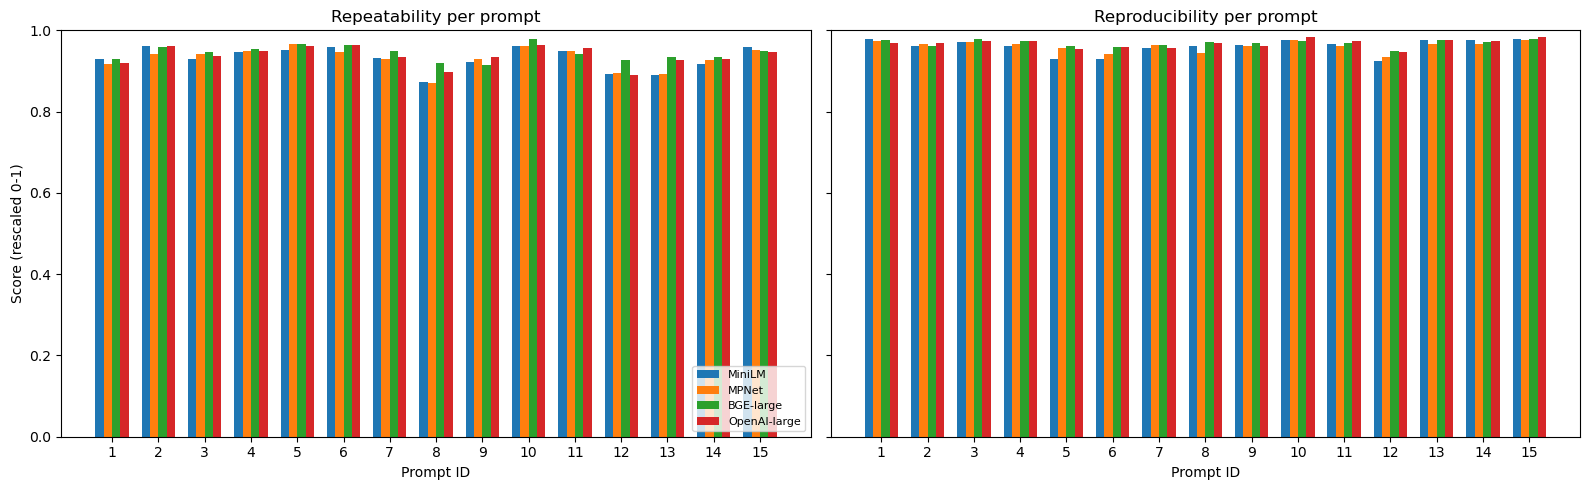

In [13]:
# For figures, I'll use the stopwords-removed [0,1] version of each embedding model
# gives one line per model for a cleaner story
headline_metrics = [
    ('minilm_with_sw_removal_01', 'MiniLM'),
    ('mpnet_with_sw_removal_01', 'MPNet'),
    ('bge-large_with_sw_removal_01', 'BGE-large'),
    ('oai-large_with_sw_removal_01', 'OpenAI-large'),
]

# Fig 1: per-prompt comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

x = np.arange(len(repeat_all))
width = 0.18

ax = axes[0]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, repeat_all[col], width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(repeat_all['prompt_id'])
ax.set_title('Repeatability per prompt')
ax.set_xlabel('Prompt ID')
ax.set_ylabel('Score (rescaled 0-1)')
ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc='lower right')

ax = axes[1]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, repro_all[col], width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(repro_all['prompt_id'])
ax.set_title('Reproducibility per prompt')
ax.set_xlabel('Prompt ID')
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_per_prompt.png', dpi=200)
plt.show()

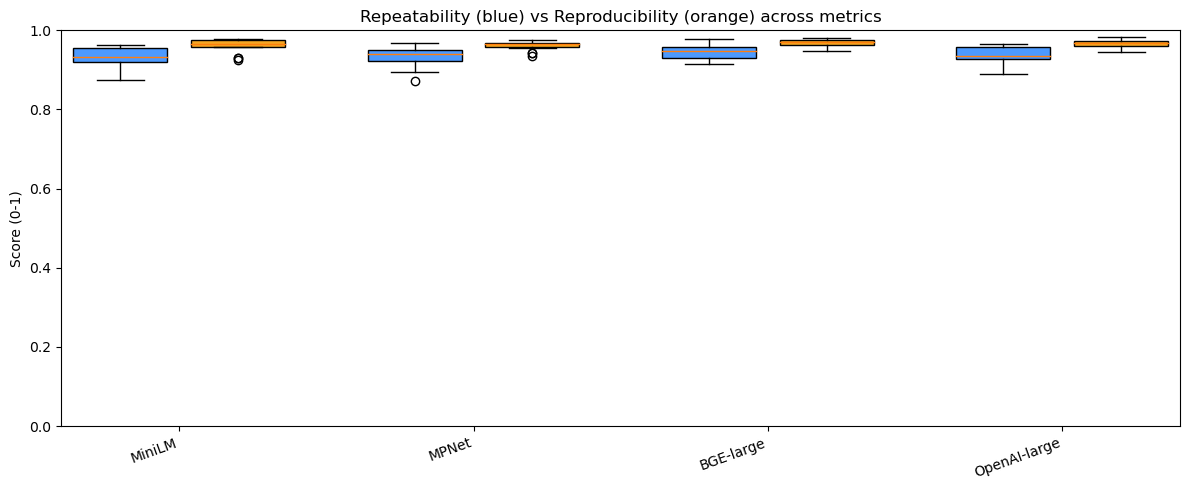

In [25]:
# Fig 2: boxplot of repeat vs repro, per metric
fig, ax = plt.subplots(figsize=(12, 5))

labels = [l for _, l in headline_metrics]
data_repeat = [repeat_all[c].values for c, _ in headline_metrics]
data_repro = [repro_all[c].values for c, _ in headline_metrics]

positions_repeat = np.arange(len(labels)) * 2.5
positions_repro = positions_repeat + 1

bp1 = ax.boxplot(data_repeat, positions=positions_repeat, widths=0.8,
                 patch_artist=True, boxprops=dict(facecolor='#4C9AFF'), labels=labels)
bp2 = ax.boxplot(data_repro, positions=positions_repro, widths=0.8,
                 patch_artist=True, boxprops=dict(facecolor='#F5A623'))

ax.set_xticks(positions_repeat + 0.5)
ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_ylabel('Score (0-1)')
ax.set_title('Repeatability (blue) vs Reproducibility (orange) across metrics')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_repeat_vs_repro.png', dpi=200)
plt.show()

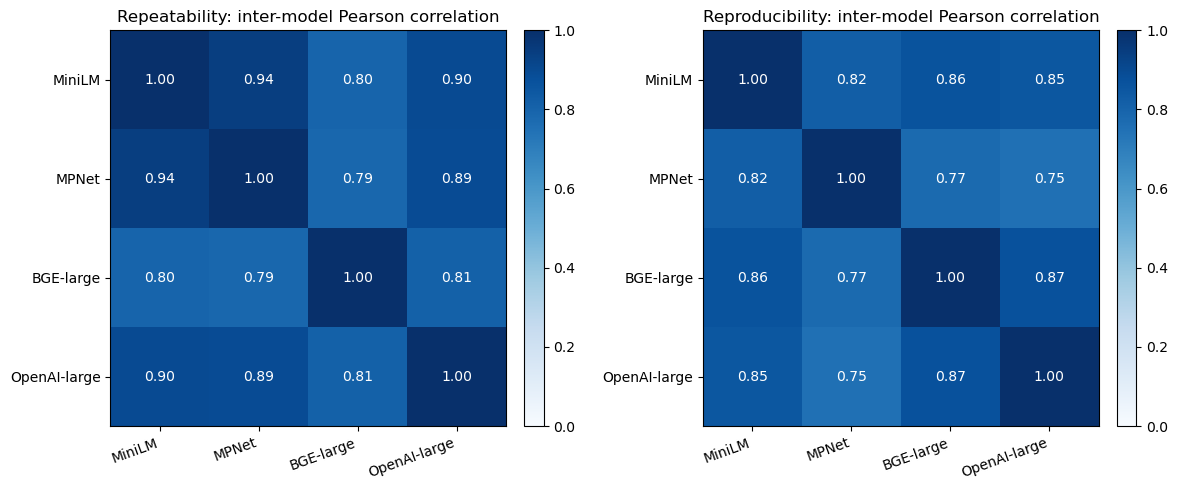


If these correlations are all high (>0.7), it means my four embedding models
tell the same story — strong robustness evidence for the paper.


In [15]:
# Fig 3: inter-model agreement check
# Does each embedding model tell me the same story?
# Pearson correlation between models' per-prompt scores (repeatability)
from scipy.stats import pearsonr

model_cols = {label: col for col, label in headline_metrics}
labels_list = list(model_cols.keys())
n = len(labels_list)

corr_repeat = np.zeros((n, n))
corr_repro = np.zeros((n, n))
for i, lab_i in enumerate(labels_list):
    for j, lab_j in enumerate(labels_list):
        corr_repeat[i, j], _ = pearsonr(repeat_all[model_cols[lab_i]], repeat_all[model_cols[lab_j]])
        corr_repro[i, j], _ = pearsonr(repro_all[model_cols[lab_i]], repro_all[model_cols[lab_j]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, mat, title in zip(axes, [corr_repeat, corr_repro],
                          ['Repeatability: inter-model Pearson correlation',
                           'Reproducibility: inter-model Pearson correlation']):
    im = ax.imshow(mat, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(labels_list, rotation=20, ha='right')
    ax.set_yticks(range(n)); ax.set_yticklabels(labels_list)
    ax.set_title(title)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center',
                    color='white' if mat[i,j]>0.6 else 'black')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_intermodel_agreement.png', dpi=200)
plt.show()

print('\nIf these correlations are all high (>0.7), it means my four embedding models')
print('tell the same story — strong robustness evidence for the paper.')

# PART E: GEMINI 3 FLASH — REPEATABILITY & REPRODUCIBILITY ANALYSIS
This section applies the **exact same analysis pipeline** used for GPT-5 (Parts A–D) to the Gemini 3 Flash Preview data. The embedding models, metrics, and statistical tests are identical — only the input CSV changes.The reason I'm keeping GPT-5 and Gemini sections separate (rather than merging them into one loop) is to make it easy to re-run just one model's analysis if I need to tweak it later.

### E.0 Load Gemini 3 Flash data

In [16]:
gemini_repeat_df = pd.read_csv(PROJECT_DIR / 'Outputs_From_Gemini' / 'repeatability_outputs_gemini.csv')
gemini_repro_df  = pd.read_csv(PROJECT_DIR / 'Outputs_From_Gemini' / 'reproducibility_outputs_gemini.csv')
print(f'Gemini repeatability: {len(gemini_repeat_df)} rows (expected 450)')
print(f'Gemini reproducibility: {len(gemini_repro_df)} rows (expected 2250)')
print(f'Model: {gemini_repeat_df["model"].unique()}')

Gemini repeatability: 450 rows (expected 450)
Gemini reproducibility: 2250 rows (expected 2250)
Model: ['gemini-3-flash-preview']


### E.1 Semantic repeatability — all three local sentence-transformer modelsI need parameterized versions of the helper functions here (the originals I wrote in Part A are hardcoded to use GPT-5's `repeat_df` and `repro_df`). Let me redefine them to take any dataframe.

In [17]:
def compute_repeatability_df(df, model, model_key):
    """Compute semantic repeatability per prompt. Parameterized version."""
    records = []
    for prompt_id, g in df.groupby('prompt_id'):
        texts = g['answer_content'].dropna().tolist()
        texts = [t for t in texts if isinstance(t, str) and t.strip()]

        texts_clean = [remove_stopwords(t) for t in texts]
        emb_clean = model.encode(texts_clean, normalize_embeddings=True, show_progress_bar=False)
        score_clean = average_pairwise_cosine(emb_clean)

        emb_full = model.encode(texts, normalize_embeddings=True, show_progress_bar=False)
        score_full = average_pairwise_cosine(emb_full)

        records.append({
            'prompt_id': int(prompt_id),
            'n_runs': len(texts),
            f'{model_key}_with_sw_removal': score_clean,
            f'{model_key}_no_sw_removal': score_full,
            f'{model_key}_with_sw_removal_01': rescale_cosine_to_01(score_clean),
            f'{model_key}_no_sw_removal_01': rescale_cosine_to_01(score_full),
        })
    return pd.DataFrame(records)

gemini_repeat_local_dfs = {}
for key, model in local_models_loaded.items():
    print(f'Computing Gemini repeatability with {key} ...')
    gemini_repeat_local_dfs[key] = compute_repeatability_df(gemini_repeat_df, model, key)
    print(f'  ✓ {key} done')

# Merge
gemini_repeat_local_all = gemini_repeat_local_dfs['minilm']
for key in ['mpnet', 'bge-large']:
    cols = ['prompt_id'] + [c for c in gemini_repeat_local_dfs[key].columns if c.startswith(key)]
    gemini_repeat_local_all = gemini_repeat_local_all.merge(gemini_repeat_local_dfs[key][cols], on='prompt_id')

gemini_repeat_local_all

Computing Gemini repeatability with minilm ...
  ✓ minilm done
Computing Gemini repeatability with mpnet ...
  ✓ mpnet done
Computing Gemini repeatability with bge-large ...
  ✓ bge-large done


,prompt_id,n_runs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01
0,1,30,0.912296,0.872359,0.956148,0.936179,0.910293,0.916694,0.955147,0.958347,0.906757,0.925409,0.953378,0.962704
1,2,30,0.902210,0.886207,0.951105,0.943103,0.952006,0.949952,0.976003,0.974976,0.929835,0.937638,0.964917,0.968819
2,3,30,0.922259,0.904028,0.961129,0.952014,0.961706,0.965905,0.980853,0.982952,0.947177,0.943988,0.973589,0.971994
3,4,30,0.915988,0.902340,0.957994,0.951170,0.923912,0.940209,0.961956,0.970105,0.932271,0.957328,0.966136,0.978664
4,5,30,0.940094,0.927388,0.970047,0.963694,0.940960,0.962575,0.970480,0.981288,0.926930,0.956593,0.963465,0.978297
5,6,30,0.937323,0.916628,0.968661,0.958314,0.952780,0.966733,0.976390,0.983366,0.945851,0.964602,0.972925,0.982301
6,7,30,0.923060,0.904988,0.961530,0.952494,0.909820,0.924578,0.954910,0.962289,0.923102,0.951877,0.961551,0.975939
7,8,30,0.912163,0.870072,0.956082,0.935036,0.927287,0.921495,0.963643,0.960748,0.919042,0.942285,0.959521,0.971142
8,9,30,0.908224,0.877985,0.954112,0.938993,0.920436,0.927738,0.960218,0.963869,0.910690,0.934562,0.955345,0.967281
9,10,30,0.939743,0.925136,0.969871,0.962568,0.941867,0.969500,0.970934,0.984750,0.940082,0.973983,0.970041,0.986992


### E.2 Semantic repeatability — OpenAI text-embedding-3-large

In [18]:
records_gemini_repeat_oai = []

for prompt_id, g in tqdm(gemini_repeat_df.groupby('prompt_id'), desc='OpenAI large on Gemini repeatability'):
    texts = g['answer_content'].dropna().tolist()
    texts = [t for t in texts if isinstance(t, str) and t.strip()]

    texts_clean = [remove_stopwords(t) for t in texts]
    emb_clean = openai_embed(texts_clean)
    emb_clean = [e / np.linalg.norm(e) for e in emb_clean]
    score_clean = average_pairwise_cosine(emb_clean)

    emb_full = openai_embed(texts)
    emb_full = [e / np.linalg.norm(e) for e in emb_full]
    score_full = average_pairwise_cosine(emb_full)

    records_gemini_repeat_oai.append({
        'prompt_id': int(prompt_id),
        'oai-large_with_sw_removal': score_clean,
        'oai-large_no_sw_removal': score_full,
        'oai-large_with_sw_removal_01': rescale_cosine_to_01(score_clean),
        'oai-large_no_sw_removal_01': rescale_cosine_to_01(score_full),
    })

gemini_repeat_oai_df = pd.DataFrame(records_gemini_repeat_oai)
gemini_repeat_oai_df

OpenAI large on Gemini repeatability: 100%|████| 15/15 [00:23<00:00,  1.58s/it]


,prompt_id,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,0.924270,0.923112,0.962135,0.961556
1,2,0.944674,0.951819,0.972337,0.975910
2,3,0.926382,0.952660,0.963191,0.976330
3,4,0.925329,0.957317,0.962664,0.978659
4,5,0.935894,0.952419,0.967947,0.976210
5,6,0.943599,0.957354,0.971800,0.978677
6,7,0.904673,0.939531,0.952336,0.969766
7,8,0.919340,0.925525,0.959670,0.962763
8,9,0.914738,0.939256,0.957369,0.969628
9,10,0.934744,0.947290,0.967372,0.973645


### E.4 Combine all Gemini repeatability metrics

In [19]:
gemini_repeat_all = (gemini_repeat_local_all
                     .merge(gemini_repeat_oai_df, on='prompt_id'))

(PROJECT_DIR / 'Analysis_Results_centroid').mkdir(exist_ok=True)
gemini_repeat_all.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'repeatability_all_metrics_gemini.csv', index=False)
gemini_repeat_all

,prompt_id,n_runs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,30,0.912296,0.872359,0.956148,0.936179,0.910293,0.916694,0.955147,0.958347,0.906757,0.925409,0.953378,0.962704,0.924270,0.923112,0.962135,0.961556
1,2,30,0.902210,0.886207,0.951105,0.943103,0.952006,0.949952,0.976003,0.974976,0.929835,0.937638,0.964917,0.968819,0.944674,0.951819,0.972337,0.975910
2,3,30,0.922259,0.904028,0.961129,0.952014,0.961706,0.965905,0.980853,0.982952,0.947177,0.943988,0.973589,0.971994,0.926382,0.952660,0.963191,0.976330
3,4,30,0.915988,0.902340,0.957994,0.951170,0.923912,0.940209,0.961956,0.970105,0.932271,0.957328,0.966136,0.978664,0.925329,0.957317,0.962664,0.978659
4,5,30,0.940094,0.927388,0.970047,0.963694,0.940960,0.962575,0.970480,0.981288,0.926930,0.956593,0.963465,0.978297,0.935894,0.952419,0.967947,0.976210
5,6,30,0.937323,0.916628,0.968661,0.958314,0.952780,0.966733,0.976390,0.983366,0.945851,0.964602,0.972925,0.982301,0.943599,0.957354,0.971800,0.978677
6,7,30,0.923060,0.904988,0.961530,0.952494,0.909820,0.924578,0.954910,0.962289,0.923102,0.951877,0.961551,0.975939,0.904673,0.939531,0.952336,0.969766
7,8,30,0.912163,0.870072,0.956082,0.935036,0.927287,0.921495,0.963643,0.960748,0.919042,0.942285,0.959521,0.971142,0.919340,0.925525,0.959670,0.962763
8,9,30,0.908224,0.877985,0.954112,0.938993,0.920436,0.927738,0.960218,0.963869,0.910690,0.934562,0.955345,0.967281,0.914738,0.939256,0.957369,0.969628
9,10,30,0.939743,0.925136,0.969871,0.962568,0.941867,0.969500,0.970934,0.984750,0.940082,0.973983,0.970041,0.986992,0.934744,0.947290,0.967372,0.973645


## PART F: GEMINI 3 FLASH — REPRODUCIBILITY ANALYSIS
Same cross-variant pairing logic as Part B, applied to `gemini_repro_df`.

### F.1 Local sentence-transformer models (reproducibility)

In [20]:
def compute_reproducibility_df(df, model, model_key):
    """Compute semantic reproducibility per prompt. Parameterized version."""
    records = []
    for prompt_id, g in df.groupby('prompt_id'):
        texts_full = g['answer_content'].tolist()
        texts_clean = [remove_stopwords(t) for t in texts_full]

        emb_full = model.encode(texts_full, normalize_embeddings=True, show_progress_bar=False)
        emb_clean = model.encode(texts_clean, normalize_embeddings=True, show_progress_bar=False)

        variants = g['variant_id'].values
        unique_variants = sorted(set(variants))
        centroids_full = np.array([emb_full[variants == v].mean(axis=0) for v in unique_variants])
        centroids_clean = np.array([emb_clean[variants == v].mean(axis=0) for v in unique_variants])
        centroids_full = centroids_full / np.linalg.norm(centroids_full, axis=1, keepdims=True)
        centroids_clean = centroids_clean / np.linalg.norm(centroids_clean, axis=1, keepdims=True)
        sim_full = cos_sim(centroids_full, centroids_full)
        sim_clean = cos_sim(centroids_clean, centroids_clean)
        rows_full, rows_clean = [], []
        for i in range(len(unique_variants)):
            for j in range(i+1, len(unique_variants)):
                rows_full.append(sim_full[i, j])
                rows_clean.append(sim_clean[i, j])

        score_full = float(np.mean(rows_full))
        score_clean = float(np.mean(rows_clean))

        records.append({
            'prompt_id': int(prompt_id),
            'n_cross_variant_pairs': len(rows_full),
            f'{model_key}_with_sw_removal': score_clean,
            f'{model_key}_no_sw_removal': score_full,
            f'{model_key}_with_sw_removal_01': rescale_cosine_to_01(score_clean),
            f'{model_key}_no_sw_removal_01': rescale_cosine_to_01(score_full),
        })
    return pd.DataFrame(records)

gemini_repro_local_dfs = {}
for key, model in local_models_loaded.items():
    print(f'Computing Gemini reproducibility with {key} ...')
    gemini_repro_local_dfs[key] = compute_reproducibility_df(gemini_repro_df, model, key)
    print(f'  ✓ {key} done')

gemini_repro_local_all = gemini_repro_local_dfs['minilm']
for key in ['mpnet', 'bge-large']:
    cols = ['prompt_id'] + [c for c in gemini_repro_local_dfs[key].columns if c.startswith(key)]
    gemini_repro_local_all = gemini_repro_local_all.merge(gemini_repro_local_dfs[key][cols], on='prompt_id')

gemini_repro_local_all

Computing Gemini reproducibility with minilm ...
  ✓ minilm done
Computing Gemini reproducibility with mpnet ...
  ✓ mpnet done
Computing Gemini reproducibility with bge-large ...
  ✓ bge-large done


,prompt_id,n_cross_variant_pairs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01
0,1,10,0.922226,0.858546,0.961113,0.929273,0.932040,0.904401,0.966020,0.952201,0.928751,0.916546,0.964375,0.958273
1,2,10,0.900032,0.837188,0.950016,0.918594,0.931958,0.901201,0.965979,0.950600,0.916823,0.918679,0.958412,0.959340
2,3,10,0.936457,0.905209,0.968229,0.952605,0.937117,0.932783,0.968559,0.966391,0.950778,0.933894,0.975389,0.966947
3,4,10,0.887549,0.805296,0.943774,0.902648,0.919597,0.895828,0.959799,0.947914,0.933890,0.922748,0.966945,0.961374
4,5,10,0.915899,0.866904,0.957949,0.933452,0.938273,0.921587,0.969137,0.960794,0.935803,0.934383,0.967901,0.967192
5,6,10,0.895812,0.815912,0.947906,0.907956,0.928135,0.887286,0.964067,0.943643,0.929954,0.913694,0.964977,0.956847
6,7,10,0.925696,0.910105,0.962848,0.955053,0.913149,0.942101,0.956574,0.971051,0.928685,0.939264,0.964343,0.969632
7,8,10,0.904081,0.806440,0.952040,0.903220,0.907467,0.872830,0.953734,0.936415,0.926519,0.930780,0.963259,0.965390
8,9,10,0.914954,0.873624,0.957477,0.936812,0.907745,0.903645,0.953872,0.951822,0.943861,0.941748,0.971930,0.970874
9,10,10,0.943013,0.887252,0.971506,0.943626,0.934569,0.948663,0.967284,0.974331,0.952706,0.946724,0.976353,0.973362


### F.2 OpenAI text-embedding-3-large (reproducibility)

In [21]:
records_gemini_repro_oai = []

for prompt_id, g in tqdm(gemini_repro_df.groupby('prompt_id'), desc='OpenAI large on Gemini reproducibility'):
    texts_full = g['answer_content'].tolist()
    texts_clean = [remove_stopwords(t) for t in texts_full]

    emb_full = openai_embed(texts_full)
    emb_full = np.array([e / np.linalg.norm(e) for e in emb_full])

    emb_clean = openai_embed(texts_clean)
    emb_clean = np.array([e / np.linalg.norm(e) for e in emb_clean])

    variants = g['variant_id'].values
    unique_variants = sorted(set(variants))
    centroids_full = np.array([emb_full[variants == v].mean(axis=0) for v in unique_variants])
    centroids_clean = np.array([emb_clean[variants == v].mean(axis=0) for v in unique_variants])
    centroids_full = centroids_full / np.linalg.norm(centroids_full, axis=1, keepdims=True)
    centroids_clean = centroids_clean / np.linalg.norm(centroids_clean, axis=1, keepdims=True)
    sim_full = cos_sim(centroids_full, centroids_full)
    sim_clean = cos_sim(centroids_clean, centroids_clean)
    rows_full, rows_clean = [], []
    for i in range(len(unique_variants)):
        for j in range(i+1, len(unique_variants)):
            rows_full.append(sim_full[i, j])
            rows_clean.append(sim_clean[i, j])

    records_gemini_repro_oai.append({
        'prompt_id': int(prompt_id),
        'oai-large_with_sw_removal': float(np.mean(rows_clean)),
        'oai-large_no_sw_removal': float(np.mean(rows_full)),
        'oai-large_with_sw_removal_01': rescale_cosine_to_01(float(np.mean(rows_clean))),
        'oai-large_no_sw_removal_01': rescale_cosine_to_01(float(np.mean(rows_full))),
    })

gemini_repro_oai_df = pd.DataFrame(records_gemini_repro_oai)
gemini_repro_oai_df

OpenAI large on Gemini reproducibility: 100%|██| 15/15 [03:22<00:00, 13.51s/it]


,prompt_id,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,0.914690,0.903062,0.957345,0.951531
1,2,0.927783,0.922741,0.963891,0.961370
2,3,0.951623,0.960413,0.975812,0.980206
3,4,0.948430,0.958409,0.974215,0.979205
4,5,0.945996,0.948570,0.972998,0.974285
5,6,0.939290,0.937840,0.969645,0.968920
6,7,0.933195,0.925840,0.966597,0.962920
7,8,0.929034,0.920619,0.964517,0.960310
8,9,0.944137,0.928570,0.972069,0.964285
9,10,0.950817,0.942502,0.975408,0.971251


### F.4 Combine all Gemini reproducibility metrics

In [22]:
gemini_repro_all = (gemini_repro_local_all
                    .merge(gemini_repro_oai_df, on='prompt_id'))

gemini_repro_all.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'reproducibility_all_metrics_gemini.csv', index=False)
gemini_repro_all

,prompt_id,n_cross_variant_pairs,minilm_with_sw_removal,minilm_no_sw_removal,minilm_with_sw_removal_01,minilm_no_sw_removal_01,mpnet_with_sw_removal,mpnet_no_sw_removal,mpnet_with_sw_removal_01,mpnet_no_sw_removal_01,bge-large_with_sw_removal,bge-large_no_sw_removal,bge-large_with_sw_removal_01,bge-large_no_sw_removal_01,oai-large_with_sw_removal,oai-large_no_sw_removal,oai-large_with_sw_removal_01,oai-large_no_sw_removal_01
0,1,10,0.922226,0.858546,0.961113,0.929273,0.932040,0.904401,0.966020,0.952201,0.928751,0.916546,0.964375,0.958273,0.914690,0.903062,0.957345,0.951531
1,2,10,0.900032,0.837188,0.950016,0.918594,0.931958,0.901201,0.965979,0.950600,0.916823,0.918679,0.958412,0.959340,0.927783,0.922741,0.963891,0.961370
2,3,10,0.936457,0.905209,0.968229,0.952605,0.937117,0.932783,0.968559,0.966391,0.950778,0.933894,0.975389,0.966947,0.951623,0.960413,0.975812,0.980206
3,4,10,0.887549,0.805296,0.943774,0.902648,0.919597,0.895828,0.959799,0.947914,0.933890,0.922748,0.966945,0.961374,0.948430,0.958409,0.974215,0.979205
4,5,10,0.915899,0.866904,0.957949,0.933452,0.938273,0.921587,0.969137,0.960794,0.935803,0.934383,0.967901,0.967192,0.945996,0.948570,0.972998,0.974285
5,6,10,0.895812,0.815912,0.947906,0.907956,0.928135,0.887286,0.964067,0.943643,0.929954,0.913694,0.964977,0.956847,0.939290,0.937840,0.969645,0.968920
6,7,10,0.925696,0.910105,0.962848,0.955053,0.913149,0.942101,0.956574,0.971051,0.928685,0.939264,0.964343,0.969632,0.933195,0.925840,0.966597,0.962920
7,8,10,0.904081,0.806440,0.952040,0.903220,0.907467,0.872830,0.953734,0.936415,0.926519,0.930780,0.963259,0.965390,0.929034,0.920619,0.964517,0.960310
8,9,10,0.914954,0.873624,0.957477,0.936812,0.907745,0.903645,0.953872,0.951822,0.943861,0.941748,0.971930,0.970874,0.944137,0.928570,0.972069,0.964285
9,10,10,0.943013,0.887252,0.971506,0.943626,0.934569,0.948663,0.967284,0.974331,0.952706,0.946724,0.976353,0.973362,0.950817,0.942502,0.975408,0.971251


## PART G: Statistical testing — Gemini 3 FlashSame paired Wilcoxon + bootstrap CIs as Part C, applied to the Gemini metrics.

In [23]:
gemini_results = []
for col, label in embedding_metrics:
    repeat_vals = gemini_repeat_all[col].values
    repro_vals = gemini_repro_all[col].values
    r_mean, r_lo, r_hi = bootstrap_ci(repeat_vals)
    p_mean, p_lo, p_hi = bootstrap_ci(repro_vals)
    stat, pval = wilcoxon(repeat_vals, repro_vals)
    gemini_results.append({
        'metric': label,
        'repeat_mean': r_mean, 'repeat_95CI': f'[{r_lo:.3f}, {r_hi:.3f}]',
        'repro_mean': p_mean, 'repro_95CI': f'[{p_lo:.3f}, {p_hi:.3f}]',
        'wilcoxon_stat': stat, 'wilcoxon_p': pval,
    })

gemini_summary = pd.DataFrame(gemini_results)
gemini_summary.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'summary_statistics_gemini.csv', index=False)
gemini_summary

,metric,repeat_mean,repeat_95CI,repro_mean,repro_95CI,wilcoxon_stat,wilcoxon_p
0,MiniLM-L6-v2 (stopwords removed),0.961905,"[0.959, 0.965]",0.961362,"[0.955, 0.968]",55.0,0.803955
1,MiniLM-L6-v2 (full text),0.949701,"[0.944, 0.955]",0.933577,"[0.924, 0.943]",19.0,0.018066
2,MPNet-base-v2 (stopwords removed),0.967482,"[0.964, 0.971]",0.965655,"[0.961, 0.970]",42.0,0.330261
3,MPNet-base-v2 (full text),0.971920,"[0.967, 0.976]",0.958420,"[0.952, 0.965]",13.0,0.005371
4,BGE-large-en-v1.5 (stopwords removed),0.964527,"[0.961, 0.968]",0.968710,"[0.965, 0.972]",31.0,0.106995
5,BGE-large-en-v1.5 (full text),0.972685,"[0.968, 0.977]",0.967042,"[0.962, 0.972]",30.0,0.094604
6,OpenAI text-embedding-3-large (stopwords removed),0.964051,"[0.961, 0.967]",0.970495,"[0.966, 0.974]",15.0,0.008362
7,OpenAI text-embedding-3-large (full text),0.972560,"[0.970, 0.975]",0.969141,"[0.964, 0.974]",31.0,0.106995


## PART H: Figures — Gemini 3 FlashSame three figures as Part D, but for Gemini.

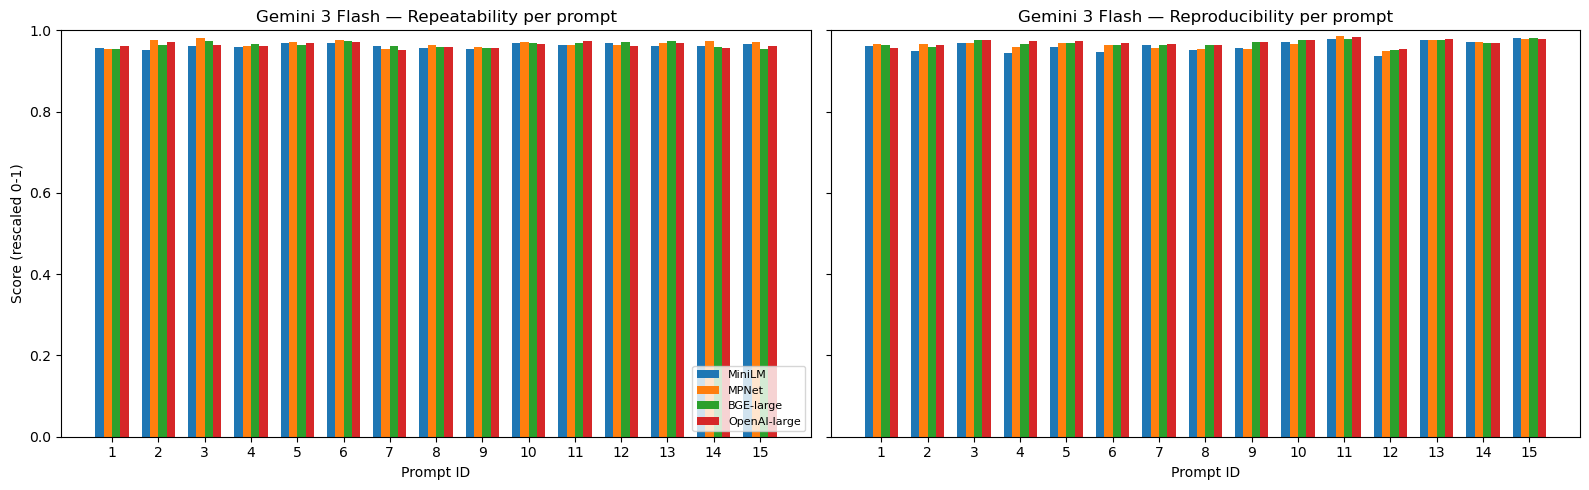

In [24]:
# Fig 1 (Gemini): per-prompt comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
x = np.arange(len(gemini_repeat_all))
width = 0.18

ax = axes[0]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, gemini_repeat_all[col], width, label=label)
ax.set_xticks(x); ax.set_xticklabels(gemini_repeat_all['prompt_id'])
ax.set_title('Gemini 3 Flash — Repeatability per prompt')
ax.set_xlabel('Prompt ID'); ax.set_ylabel('Score (rescaled 0-1)')
ax.set_ylim(0, 1); ax.legend(fontsize=8, loc='lower right')

ax = axes[1]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, gemini_repro_all[col], width, label=label)
ax.set_xticks(x); ax.set_xticklabels(gemini_repro_all['prompt_id'])
ax.set_title('Gemini 3 Flash — Reproducibility per prompt')
ax.set_xlabel('Prompt ID'); ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_per_prompt_gemini.png', dpi=200)
plt.show()

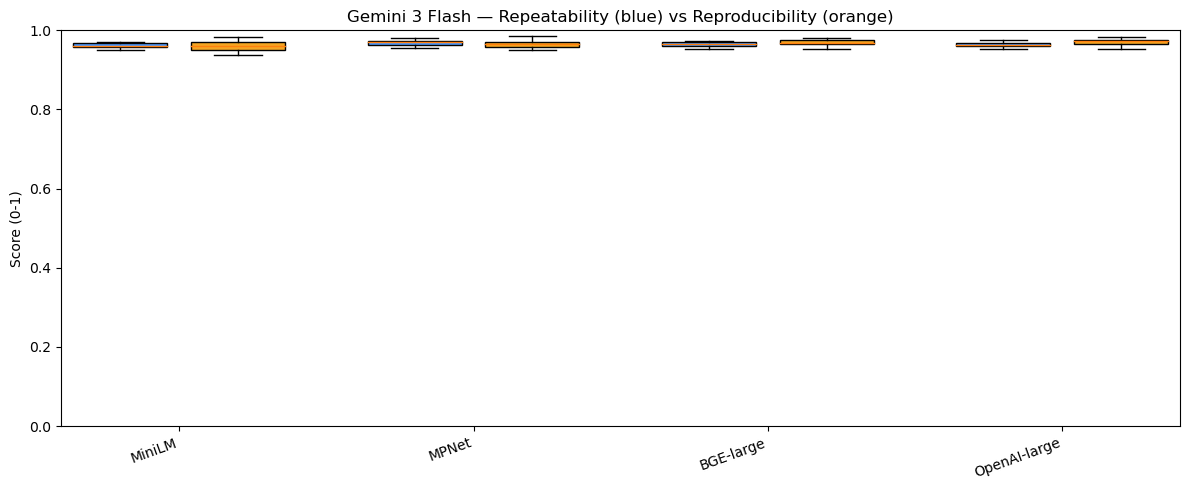

In [25]:
# Fig 2 (Gemini): boxplot of repeat vs repro
fig, ax = plt.subplots(figsize=(12, 5))

labels = [l for _, l in headline_metrics]
data_repeat = [gemini_repeat_all[c].values for c, _ in headline_metrics]
data_repro = [gemini_repro_all[c].values for c, _ in headline_metrics]

positions_repeat = np.arange(len(labels)) * 2.5
positions_repro = positions_repeat + 1

bp1 = ax.boxplot(data_repeat, positions=positions_repeat, widths=0.8,
                 patch_artist=True, boxprops=dict(facecolor='#4C9AFF'))
bp2 = ax.boxplot(data_repro, positions=positions_repro, widths=0.8,
                 patch_artist=True, boxprops=dict(facecolor='#F5A623'))

ax.set_xticks(positions_repeat + 0.5); ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_ylabel('Score (0-1)')
ax.set_title('Gemini 3 Flash — Repeatability (blue) vs Reproducibility (orange)')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_repeat_vs_repro_gemini.png', dpi=200)
plt.show()

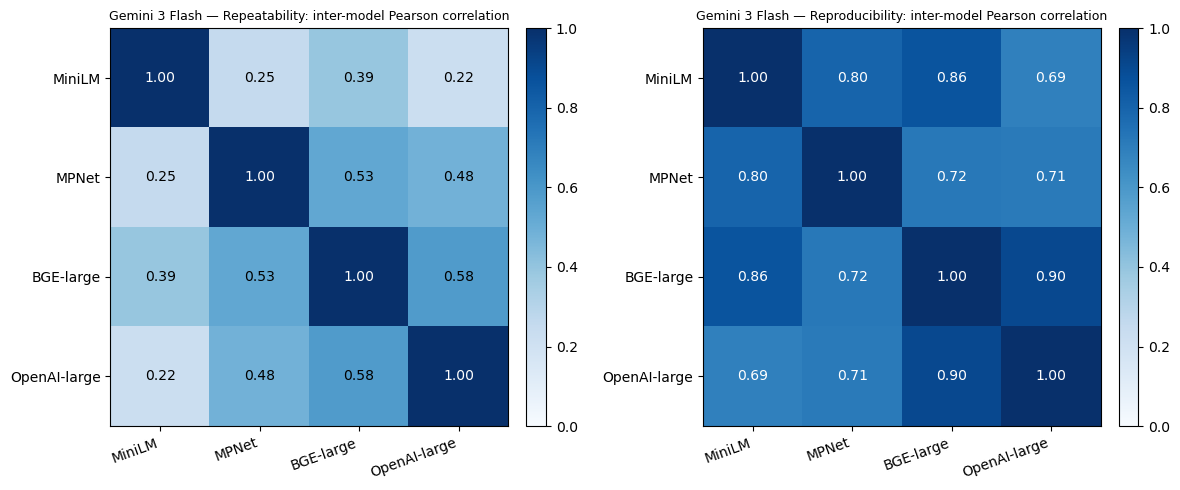

In [26]:
# Fig 3 (Gemini): inter-model agreement check
model_cols = {label: col for col, label in headline_metrics}
labels_list = list(model_cols.keys())
n = len(labels_list)

corr_repeat_gem = np.zeros((n, n))
corr_repro_gem  = np.zeros((n, n))
for i, lab_i in enumerate(labels_list):
    for j, lab_j in enumerate(labels_list):
        corr_repeat_gem[i, j], _ = pearsonr(gemini_repeat_all[model_cols[lab_i]], gemini_repeat_all[model_cols[lab_j]])
        corr_repro_gem[i, j], _  = pearsonr(gemini_repro_all[model_cols[lab_i]], gemini_repro_all[model_cols[lab_j]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, mat, title in zip(axes, [corr_repeat_gem, corr_repro_gem],
                          ['Gemini 3 Flash — Repeatability: inter-model Pearson correlation',
                           'Gemini 3 Flash — Reproducibility: inter-model Pearson correlation']):
    im = ax.imshow(mat, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(labels_list, rotation=20, ha='right')
    ax.set_yticks(range(n)); ax.set_yticklabels(labels_list)
    ax.set_title(title, fontsize=9)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center',
                    color='white' if mat[i,j]>0.6 else 'black')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_intermodel_agreement_gemini.png', dpi=200)
plt.show()

Done — All Gemini results savedGemini-specific files in `Analysis_Results/`:
- `repeatability_all_metrics_gemini.csv`
- `reproducibility_all_metrics_gemini.csv`
- `summary_statistics_gemini.csv`
- `fig_per_prompt_gemini.png`
- `fig_repeat_vs_repro_gemini.png`
- `fig_intermodel_agreement_gemini.png`

GPT-5 results from Parts A–D remain untouched in the same folder (without the `_gemini` suffix).

# PART I: Per-variant reproducibility breakdown (GPT-5 + Gemini)
I want to check if any of the 5 prompt variants (v1–v5) produces systematically different responses from the others. If one variant is way off, its mean cross-variant similarity will be lower than the others.
**For each (prompt, variant) group:** mean cosine similarity between that variant's 30 outputs and all other variants' outputs (120 responses from the other 4 variants).
- **Low score** = this variant's outputs disagree with the other variants' outputs → distinctive phrasing effect
- **High score** = this variant's outputs match the other variants' outputs → the variant is interchangeableI'll use the paper's main transformer (`all-mpnet-base-v2`, medium tier) for this analysis — matching the choice we made for all main-paper figures.

### I.1 Helper function — per-variant cross-variant similarity

In [1]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path('/Users/luizzadallapria/Documents/GPT5_Study')

# Shortcut: if the per-variant CSVs already exist (previous run), load them.
# Otherwise skip — the compute cells below (I.2, I.3) will populate the variables.
_pv_gpt5 = PROJECT_DIR / 'Analysis_Results_centroid' / 'per_variant_repro_gpt5.csv'
_pv_gem  = PROJECT_DIR / 'Analysis_Results_centroid' / 'per_variant_repro_gemini.csv'
if _pv_gpt5.exists() and _pv_gem.exists():
    gpt5_per_variant   = pd.read_csv(_pv_gpt5)
    gemini_per_variant = pd.read_csv(_pv_gem)
    print('Loaded gpt5_per_variant:', gpt5_per_variant.shape)
    print('Loaded gemini_per_variant:', gemini_per_variant.shape)
else:
    print('Per-variant CSVs not yet written — I.2 and I.3 will compute them.')

Per-variant CSVs not yet written — I.2 and I.3 will compute them.


In [2]:
def compute_per_variant_repro(df, model, with_sw_removal=True):
    """For each (prompt, variant), compute mean cross-variant cosine similarity
    between that variant's 30 responses and the other 4 variants' 120 responses.

    Returns: DataFrame with columns [prompt_id, variant_id, mean_sim, mean_sim_01, n_pairs]
    """
    records = []
    for prompt_id, g in df.groupby('prompt_id'):
        texts_raw = g['answer_content'].astype(str).tolist()
        if with_sw_removal:
            texts = [remove_stopwords(t) for t in texts_raw]
        else:
            texts = texts_raw

        embs = model.encode(texts, normalize_embeddings=True, show_progress_bar=False)
        sim = cos_sim(embs, embs)

        variants = g['variant_id'].values
        unique_variants = sorted(set(variants))
        centroids = np.array([embs[variants == v].mean(axis=0) for v in unique_variants])
        centroids = centroids / np.linalg.norm(centroids, axis=1, keepdims=True)
        centroid_sim = cos_sim(centroids, centroids)

        for vi, v in enumerate(unique_variants):
            sims = [centroid_sim[vi, vj] for vj in range(len(unique_variants)) if vj != vi]
            mean_sim = float(np.mean(sims))
            records.append({
                'prompt_id': int(prompt_id),
                'variant_id': v,
                'mean_sim_raw': mean_sim,
                'mean_sim_01': rescale_cosine_to_01(mean_sim),
                'n_pairs': len(sims),
            })
    return pd.DataFrame(records)


def compute_per_variant_repro_from_cache(cache_path):
    """Centroid-based per-variant reproducibility using cached MPNet embeddings.
    Loads a Part-J .npz (embeddings + prompt_ids + variant_ids + run_ids) and
    returns a DataFrame equivalent to compute_per_variant_repro's output."""
    cache = np.load(cache_path, allow_pickle=True)
    embs_all = cache['embeddings']
    pids = cache['prompt_ids']
    vids = cache['variant_ids']
    records = []
    for prompt_id in sorted(set(pids.tolist())):
        mask = pids == prompt_id
        embs = embs_all[mask]
        variants = vids[mask]
        unique_variants = sorted(set(variants.tolist()))
        centroids = np.array([embs[variants == v].mean(axis=0) for v in unique_variants])
        centroids = centroids / np.linalg.norm(centroids, axis=1, keepdims=True)
        centroid_sim = cos_sim(centroids, centroids)
        for vi, v in enumerate(unique_variants):
            sims = [centroid_sim[vi, vj] for vj in range(len(unique_variants)) if vj != vi]
            mean_sim = float(np.mean(sims))
            records.append({
                'prompt_id': int(prompt_id),
                'variant_id': v,
                'mean_sim_raw': mean_sim,
                'mean_sim_01': rescale_cosine_to_01(mean_sim),
                'n_pairs': len(sims),
            })
    return pd.DataFrame(records)

print('Helper defined ✓')

Helper defined ✓


### I.2 Compute per-variant reproducibility — GPT-5

In [8]:
import numpy as np
from sentence_transformers.util import cos_sim
def rescale_cosine_to_01(x): return (x + 1) / 2

gpt5_per_variant = compute_per_variant_repro_from_cache(
    PROJECT_DIR / 'Embeddings_Cache' / 'mpnet_gpt5_repro_with_sw.npz'
)
gpt5_per_variant['model'] = 'GPT-5'
gpt5_per_variant.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'per_variant_repro_gpt5.csv', index=False)
gpt5_per_variant.head(10)

,prompt_id,variant_id,mean_sim_raw,mean_sim_01,n_pairs,model
0,1,1,0.925596,0.962798,4,GPT-5
1,1,2,0.961298,0.980649,4,GPT-5
2,1,3,0.950616,0.975308,4,GPT-5
3,1,4,0.957433,0.978716,4,GPT-5
4,1,5,0.940100,0.970050,4,GPT-5
5,2,1,0.923656,0.961828,4,GPT-5
6,2,2,0.949444,0.974722,4,GPT-5
7,2,3,0.940817,0.970408,4,GPT-5
8,2,4,0.919188,0.959594,4,GPT-5
9,2,5,0.928646,0.964323,4,GPT-5


### I.3 Compute per-variant reproducibility — Gemini 3 Flash

In [9]:
gemini_per_variant = compute_per_variant_repro_from_cache(
    PROJECT_DIR / 'Embeddings_Cache' / 'mpnet_gemini_repro_with_sw.npz'
)
gemini_per_variant['model'] = 'Gemini 3 Flash'
gemini_per_variant.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'per_variant_repro_gemini.csv', index=False)
gemini_per_variant.head(10)

,prompt_id,variant_id,mean_sim_raw,mean_sim_01,n_pairs,model
0,1,v1,0.929986,0.964993,4,Gemini 3 Flash
1,1,v2,0.948604,0.974302,4,Gemini 3 Flash
2,1,v3,0.917652,0.958826,4,Gemini 3 Flash
3,1,v4,0.947844,0.973922,4,Gemini 3 Flash
4,1,v5,0.922989,0.961495,4,Gemini 3 Flash
5,2,v1,0.944281,0.972141,4,Gemini 3 Flash
6,2,v2,0.938867,0.969434,4,Gemini 3 Flash
7,2,v3,0.923068,0.961534,4,Gemini 3 Flash
8,2,v4,0.927995,0.963998,4,Gemini 3 Flash
9,2,v5,0.930033,0.965016,4,Gemini 3 Flash


### I.4 Summary statistics — mean per variant across all 15 prompts

In [10]:
summary_per_variant = (
    pd.concat([gpt5_per_variant, gemini_per_variant])
      .groupby(['model', 'variant_id'])['mean_sim_01']
      .agg(['mean', 'std', 'min', 'max'])
      .reset_index()
)
summary_per_variant.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'per_variant_repro_summary.csv', index=False)
summary_per_variant

,model,variant_id,mean,std,min,max
0,GPT-5,1,0.954600,0.015185,0.920739,0.976134
1,GPT-5,2,0.964245,0.016710,0.921649,0.982153
2,GPT-5,3,0.965659,0.011909,0.942741,0.980037
3,GPT-5,4,0.957281,0.018989,0.909655,0.979128
4,GPT-5,5,0.962021,0.010551,0.941452,0.974504
5,Gemini 3 Flash,v1,0.968647,0.009640,0.945324,0.989347
6,Gemini 3 Flash,v2,0.970231,0.010988,0.941701,0.985820
7,Gemini 3 Flash,v3,0.960920,0.015152,0.923409,0.981697
8,Gemini 3 Flash,v4,0.964423,0.014499,0.935368,0.987149
9,Gemini 3 Flash,v5,0.964853,0.008821,0.950122,0.984000


### I.5 Statistical test — is there a significant difference across variants? 
Friedman test: repeated-measures non-parametric test for whether 5 variants produce different repro scores across the 15 prompts. Null hypothesis: all 5 variants have the same distribution.

In [11]:
from scipy.stats import friedmanchisquare

for model_name, df_m in [('GPT-5', gpt5_per_variant), ('Gemini 3 Flash', gemini_per_variant)]:
    # Pivot to wide format: rows = prompt_id, cols = variant_id, values = mean_sim_01
    wide = df_m.pivot(index='prompt_id', columns='variant_id', values='mean_sim_01')
    # Friedman expects columns as separate groups
    arrays = [wide[v].values for v in sorted(wide.columns)]
    stat, pval = friedmanchisquare(*arrays)
    print(f'{model_name}: Friedman χ² = {stat:.3f}, p = {pval:.4f}')
    if pval < 0.05:
        print(f'  → Statistically significant difference across variants')
    else:
        print(f'  → No statistically significant difference across variants')

GPT-5: Friedman χ² = 19.040, p = 0.0008
  → Statistically significant difference across variants
Gemini 3 Flash: Friedman χ² = 15.573, p = 0.0036
  → Statistically significant difference across variants


### I.5b Post-hoc pairwise comparisons — which CoT variant pairs differ?

The Friedman test above indicates that *at least one* CoT variant differs significantly from the others, but does not identify *which* pair(s). To localize the effect, we run pairwise Wilcoxon signed-rank tests on all $\binom{5}{2} = 10$ unordered variant pairs, per model, with Holm–Bonferroni correction to control the family-wise error rate across the 10 comparisons.

In [12]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import pandas as pd

posthoc_rows = []
for model_name, df_m in [('GPT-5', gpt5_per_variant), ('Gemini 3 Flash', gemini_per_variant)]:
    wide = df_m.pivot(index='prompt_id', columns='variant_id', values='mean_sim_01')
    variants = sorted(wide.columns)
    pvals_raw = []
    stats_raw = []
    pair_labels = []
    for a, b in combinations(variants, 2):
        res = wilcoxon(wide[a].values, wide[b].values)
        pvals_raw.append(res.pvalue)
        stats_raw.append(res.statistic)
        pair_labels.append(f'{a} vs {b}')
    reject, pvals_holm, _, _ = multipletests(pvals_raw, alpha=0.05, method='holm')
    for pair, w, p_raw, p_adj, rej in zip(pair_labels, stats_raw, pvals_raw, pvals_holm, reject):
        posthoc_rows.append({
            'model': model_name,
            'pair': pair,
            'W': w,
            'p_raw': p_raw,
            'p_holm': p_adj,
            'significant_at_0.05_after_Holm': bool(rej),
        })

posthoc_df = pd.DataFrame(posthoc_rows)
print(posthoc_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Save for the paper's supplementary materials
posthoc_df.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'posthoc_cot_variant_wilcoxon_holm.csv', index=False)
print('\nSaved: Analysis_Results_centroid/posthoc_cot_variant_wilcoxon_holm.csv')

         model     pair       W  p_raw  p_holm  significant_at_0.05_after_Holm
         GPT-5   1 vs 2  4.0000 0.0004  0.0043                            True
         GPT-5   1 vs 3  7.0000 0.0012  0.0104                            True
         GPT-5   1 vs 4 46.0000 0.4543  1.0000                           False
         GPT-5   1 vs 5 12.0000 0.0043  0.0342                            True
         GPT-5   2 vs 3 55.0000 0.8040  1.0000                           False
         GPT-5   2 vs 4 35.0000 0.1688  0.6753                           False
         GPT-5   2 vs 5 30.0000 0.0946  0.4730                           False
         GPT-5   3 vs 4 23.0000 0.0353  0.2474                           False
         GPT-5   3 vs 5 25.0000 0.0479  0.2875                           False
         GPT-5   4 vs 5 44.0000 0.3894  1.0000                           False
Gemini 3 Flash v1 vs v2 50.0000 0.5995  1.0000                           False
Gemini 3 Flash v1 vs v3 18.0000 0.0151  0.1206      

### I.6 Figures

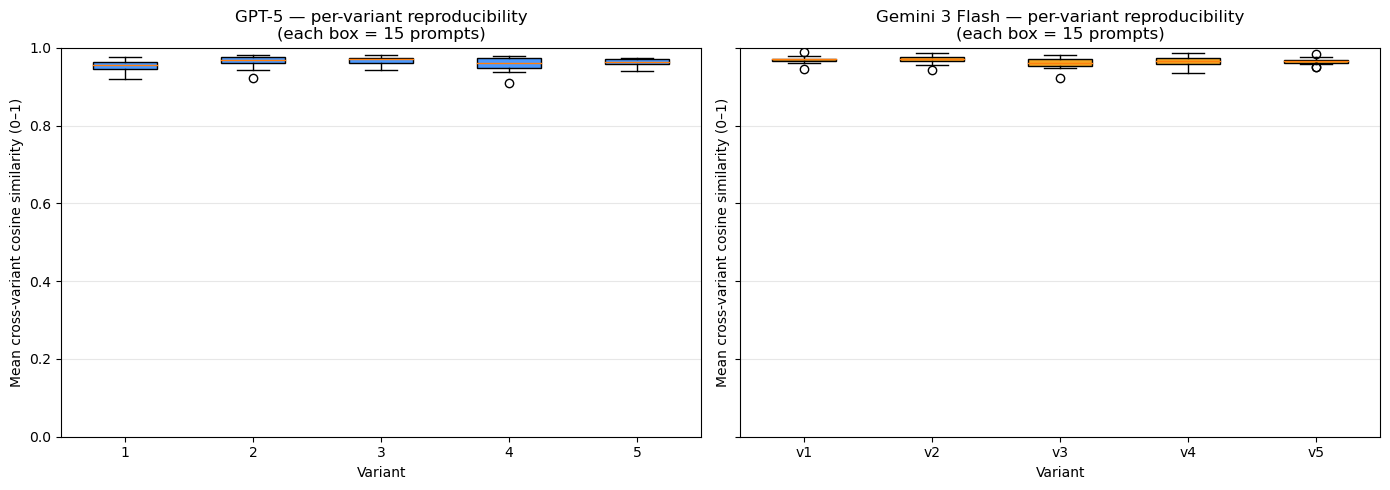

In [13]:
# Fig 1: Boxplots — per-variant scores aggregated across 15 prompts, side by side (GPT-5 vs Gemini)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (model_name, df_m, color) in zip(axes,
                                          [('GPT-5', gpt5_per_variant, '#4C9AFF'),
                                           ('Gemini 3 Flash', gemini_per_variant, '#F5A623')]):
    data = [df_m[df_m['variant_id'] == v]['mean_sim_01'].values
            for v in sorted(df_m['variant_id'].unique())]
    bp = ax.boxplot(data, patch_artist=True)
    for box in bp['boxes']:
        box.set_facecolor(color)
    ax.set_xticks(range(1, 6))
    ax.set_xticklabels(sorted(df_m['variant_id'].unique()))
    ax.set_xlabel('Variant')
    ax.set_ylabel('Mean cross-variant cosine similarity (0–1)')
    ax.set_title(f'{model_name} — per-variant reproducibility\n(each box = 15 prompts)')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_per_variant_boxplot.png', dpi=200)
plt.show()

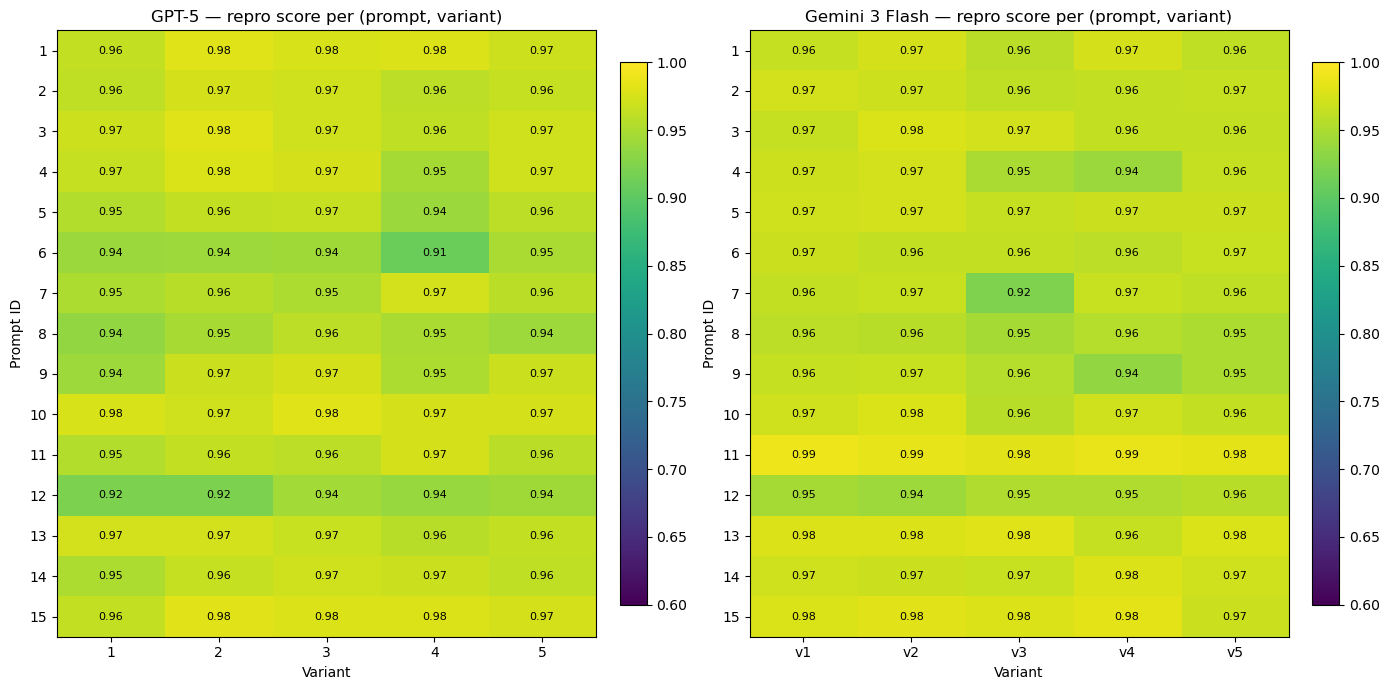

In [14]:
# Fig 2: Heatmap — rows = prompts, cols = variants, color = repro score. One subplot per model.
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (model_name, df_m) in zip(axes,
                                   [('GPT-5', gpt5_per_variant),
                                    ('Gemini 3 Flash', gemini_per_variant)]):
    heat = df_m.pivot(index='prompt_id', columns='variant_id', values='mean_sim_01')
    im = ax.imshow(heat.values, cmap='viridis', aspect='auto', vmin=0.6, vmax=1.0)
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)
    ax.set_xlabel('Variant')
    ax.set_ylabel('Prompt ID')
    ax.set_title(f'{model_name} — repro score per (prompt, variant)')
    for i in range(len(heat.index)):
        for j in range(len(heat.columns)):
            ax.text(j, i, f'{heat.values[i,j]:.2f}', ha='center', va='center',
                    color='white' if heat.values[i,j] < 0.8 else 'black', fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_per_variant_heatmap.png', dpi=200)
plt.show()

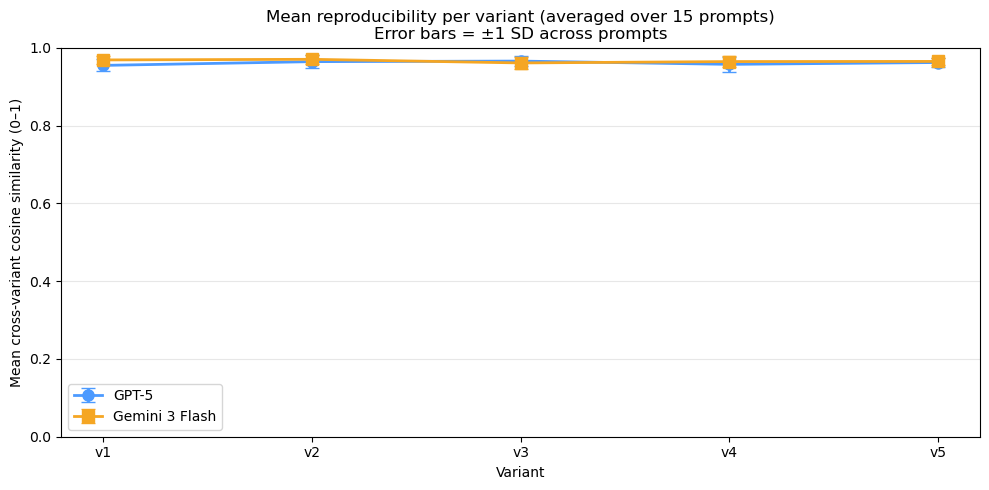

In [15]:
# Fig 3: Line chart — mean per variant across all prompts, GPT-5 vs Gemini overlaid
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, df_m, color, marker in [
    ('GPT-5', gpt5_per_variant, '#4C9AFF', 'o'),
    ('Gemini 3 Flash', gemini_per_variant, '#F5A623', 's'),
]:
    means = df_m.groupby('variant_id')['mean_sim_01'].mean()
    stds = df_m.groupby('variant_id')['mean_sim_01'].std()
    ax.errorbar(range(len(means)), means.values, yerr=stds.values,
                marker=marker, color=color, label=model_name, capsize=5, linewidth=2, markersize=8)

ax.set_xticks(range(5))
ax.set_xticklabels([f'v{i+1}' for i in range(5)])
ax.set_xlabel('Variant')
ax.set_ylabel('Mean cross-variant cosine similarity (0–1)')
ax.set_title('Mean reproducibility per variant (averaged over 15 prompts)\nError bars = ±1 SD across prompts')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_per_variant_mean_comparison.png', dpi=200)
plt.show()

Notes on Part I
**New files in `Analysis_Results/`:
- `per_variant_repro_gpt5.csv` — per-variant scores for GPT-5
- `per_variant_repro_gemini.csv` — per-variant scores for Gemini
- `per_variant_repro_summary.csv` — mean/std summary across prompts
**Figures:**
- `fig_per_variant_boxplot.png` — side-by-side boxplots per model
- `fig_per_variant_heatmap.png` — per-(prompt, variant) detail heatmap
- `fig_per_variant_mean_comparison.png` — line chart overlaying both models' per-variant means
**How to interpret:**
- If one variant (say v3) shows consistently lower scores across most prompts, that variant's phrasing elicits semantically different responses from the model
- If the Friedman test is significant for a model, at least one variant is systematically different for that model
- Cross-model comparison: if GPT-5 and Gemini show the same variant as "odd one out," the variant itself is distinctive. If they disagree, the effect is model-specific.

# PART J: Embedding cache — save and reuse embeddings for future analyses
Every time I want to make a new graph using embeddings (per-variant, per-topic, whatever), I don't want to re-encode all 2,700 responses with each transformer. Each full run takes ~5–10 minutes per transformer, which adds up.
**Solution:** encode everything once, save the raw embeddings to disk, then load from disk on future runs. I'll save embeddings as `.npz` (NumPy's compressed format) in a new `Embeddings_Cache/` folder. Each file stores:
- The embedding array `(n_responses, embedding_dim)`
- The metadata linking row indices to `(prompt_id, variant_id, run_id)`

File naming convention: `{model_key}_{dataset_key}_{preprocessing}.npz` — e.g., `mpnet_gpt5_repeat_with_sw.npz`

### J.1 Helper functions — save and load embeddings

In [16]:
CACHE_DIR = PROJECT_DIR / 'Embeddings_Cache'
CACHE_DIR.mkdir(exist_ok=True)

def embedding_cache_path(model_key, dataset_key, preprocessing):
    """Return the path for a specific cached embedding file.
    model_key: 'minilm', 'mpnet', 'bge-large', 'oai-large'
    dataset_key: 'gpt5_repeat', 'gpt5_repro', 'gemini_repeat', 'gemini_repro'
    preprocessing: 'with_sw' or 'no_sw'
    """
    return CACHE_DIR / f'{model_key}_{dataset_key}_{preprocessing}.npz'

def save_embeddings(embeddings, df, model_key, dataset_key, preprocessing):
    """Save embeddings + metadata (prompt_id, variant_id if present, run_id) to .npz."""
    path = embedding_cache_path(model_key, dataset_key, preprocessing)
    kwargs = {
        'embeddings': np.asarray(embeddings, dtype=np.float32),
        'prompt_ids': df['prompt_id'].values,
        'run_ids': df['run_id'].values,
    }
    if 'variant_id' in df.columns:
        kwargs['variant_ids'] = df['variant_id'].values
    np.savez_compressed(path, **kwargs)
    print(f'  Saved {len(embeddings):>5} embeddings → {path.name}')

def load_embeddings(model_key, dataset_key, preprocessing):
    """Load cached embeddings + metadata. Returns (embeddings, metadata_dict) or (None, None) if missing."""
    path = embedding_cache_path(model_key, dataset_key, preprocessing)
    if not path.exists():
        return None, None
    data = np.load(path, allow_pickle=True)
    meta = {k: data[k] for k in data.files if k != 'embeddings'}
    return data['embeddings'], meta

print('Cache helpers defined ✓')
print(f'Cache folder: {CACHE_DIR}')

Cache helpers defined ✓
Cache folder: /Users/luizzadallapria/Documents/GPT5_Study/Embeddings_Cache


### J.2 Encode and save all embeddings (one-time run)
This cell:
1. For each (model, dataset, preprocessing) combination, checks if the cache file exists
2. If missing → encode and save3. If present → skip (reuses the cached version)So re-running this cell is cheap: if everything is cached, it finishes in ~2 seconds. If I add new data later, only the new combinations get encoded.

**Total runtime first time:** ~15–20 min on Apple Silicon.

In [17]:
def encode_and_cache_all():
    """Encode every (model, dataset, preprocessing) combination and save to disk."""
    datasets = {
        'gpt5_repeat':   repeat_df,
        'gpt5_repro':    repro_df,
        'gemini_repeat': gemini_repeat_df,
        'gemini_repro':  gemini_repro_df,
    }

    for model_key, model in local_models_loaded.items():
        for ds_key, df in datasets.items():
            for prep_key, apply_sw in [('with_sw', True), ('no_sw', False)]:
                path = embedding_cache_path(model_key, ds_key, prep_key)
                if path.exists():
                    print(f'  Cached (skip): {path.name}')
                    continue
                texts = df['answer_content'].astype(str).tolist()
                if apply_sw:
                    texts = [remove_stopwords(t) for t in texts]
                print(f'  Encoding {model_key} on {ds_key} ({prep_key}) ...')
                embs = model.encode(texts, normalize_embeddings=True, show_progress_bar=False)
                save_embeddings(embs, df, model_key, ds_key, prep_key)

    # Also cache OpenAI embeddings (API calls, so cost ~$0.20 total if first time)
    for ds_key, df in datasets.items():
        for prep_key, apply_sw in [('with_sw', True), ('no_sw', False)]:
            path = embedding_cache_path('oai-large', ds_key, prep_key)
            if path.exists():
                print(f'  Cached (skip): {path.name}')
                continue
            texts = df['answer_content'].astype(str).tolist()
            if apply_sw:
                texts = [remove_stopwords(t) for t in texts]
            print(f'  Encoding oai-large on {ds_key} ({prep_key}) via API ...')
            embs = openai_embed(texts)
            embs = np.array([e / np.linalg.norm(e) for e in embs])
            save_embeddings(embs, df, 'oai-large', ds_key, prep_key)

encode_and_cache_all()
print('\n✅ Encoding complete. Future analyses can load embeddings directly.')

NameError: name 'repeat_df' is not defined

### J.3 Example — how to use cached embeddings in a future analysis
Any new metric or graph can start with these two lines instead of re-encoding:

In [ ]:
# Example: load MPNet embeddings for GPT-5 reproducibility (with stopword removal)
embs, meta = load_embeddings('mpnet', 'gpt5_repro', 'with_sw')
if embs is not None:
    print(f'Loaded embeddings shape: {embs.shape}')
    print(f'Metadata keys: {list(meta.keys())}')
    print(f'First 3 prompt_ids: {meta["prompt_ids"][:3]}')
else:
    print('Cache not found — run J.2 first.')

# PART K: Statistical test for inter-transformer agreement (ICC)
To formally test whether the 4 transformers give consistent scores. If they do, I can defensibly report main results using just MPNet (medium tier) in the paper and put the full 4-transformer comparison in supplementary. The right statistic for this is **Intraclass Correlation Coefficient (ICC)** — specifically ICC(2,k) with "consistency" definition — which measures agreement across multiple raters (here: transformers) rating the same subjects (here: prompts).

Interpretation:
- **ICC > 0.90** = excellent agreement
- **ICC 0.75–0.90** = good agreement
- **ICC 0.50–0.75** = moderate agreement
- **ICC < 0.50** = poor agreement

For completeness, I'll also compute **Cronbach's alpha** (reliability measure, similar interpretation).

### K.1 Install pingouin (ICC library)

In [21]:
!pip install -q "pingouin<0.5.5"

### K.2 Compute ICC for repeatability (GPT-5 and Gemini)

In [26]:
import pingouin as pg

# Four embedding-model columns used as 'raters' in the ICC analysis.
# These correspond to the four transformers compared in Methods §2.5.
transformer_cols = [
    'minilm_with_sw_removal_01',
    'mpnet_with_sw_removal_01',
    'bge-large_with_sw_removal_01',
    'oai-large_with_sw_removal_01',
]


def _ci_column_name(icc_df):
    """Pingouin renamed the CI column across versions. Return whichever exists."""
    for candidate in ['CI95%', 'CI95', 'ci95', 'CI_95', 'ci_95%']:
        if candidate in icc_df.columns:
            return candidate
    if 'CI_lower' in icc_df.columns and 'CI_upper' in icc_df.columns:
        return ('CI_lower', 'CI_upper')
    raise KeyError(f'No CI column found. Available columns: {list(icc_df.columns)}')

def _icc2k_row(icc_df):
    """Find the 'ICC(2,k) — average random raters, consistency' row.
    Pingouin has used different Type labels across versions."""
    # Try common Type values across versions
    for candidate in ['ICC2k', 'ICC(2,k)', 'ICC2(k)', 'icc2k', 'ICC2_k']:
        matched = icc_df[icc_df['Type'] == candidate]
        if len(matched) > 0:
            return matched.iloc[0]
    # Try case-insensitive and substring match
    for idx, row in icc_df.iterrows():
        t = str(row['Type']).lower().replace(' ', '').replace(',', '').replace('(', '').replace(')', '')
        if 'icc2k' in t:
            return row
    # Last resort: use the 5th row (ICC2k is traditionally the 5th in pingouin's output: 1, 2, 3, 1k, 2k, 3k)
    if len(icc_df) >= 5:
        return icc_df.iloc[4]
    raise KeyError(f'ICC2k not found. Available Type values: {list(icc_df["Type"].unique())}')

def compute_icc(scores_df, metric_cols, label):
    """Compute ICC(2,k) consistency on a (prompts × transformers) score matrix."""
    long = []
    for col in metric_cols:
        for pid, score in zip(scores_df['prompt_id'], scores_df[col]):
            long.append({'target': pid, 'rater': col, 'rating': score})
    long_df = pd.DataFrame(long)
    icc = pg.intraclass_corr(data=long_df, targets='target', raters='rater', ratings='rating')

    ci_col = _ci_column_name(icc)

    base_cols = ['Type', 'ICC', 'F', 'df1', 'df2', 'pval']
    if isinstance(ci_col, tuple):
        display_cols = base_cols + list(ci_col)
    else:
        display_cols = base_cols + [ci_col]

    print(f'\n=== {label} ===')
    print(icc[display_cols].to_string(index=False))

    icc_2k = _icc2k_row(icc)
    if isinstance(ci_col, tuple):
        ci = [float(icc_2k[ci_col[0]]), float(icc_2k[ci_col[1]])]
    else:
        ci = icc_2k[ci_col]
        if isinstance(ci, str):
            ci = [float(x.strip('[]')) for x in ci.split(',')]
    return float(icc_2k['ICC']), ci

icc_results = {}

# Repeatability — GPT-5
icc_val, ci = compute_icc(repeat_all, transformer_cols, 'GPT-5 — repeatability')
icc_results['gpt5_repeat'] = (icc_val, ci)

# Repeatability — Gemini
icc_val, ci = compute_icc(gemini_repeat_all, transformer_cols, 'Gemini 3 Flash — repeatability')
icc_results['gemini_repeat'] = (icc_val, ci)


=== GPT-5 — repeatability ===
 Type      ICC         F  df1  df2         pval                                    CI95%
 ICC1 0.794625 16.476553   14   45 2.970908e-13 [0.6220813067628509, 0.9144124006205304]
 ICC2 0.797008 21.359950   14   42 1.109218e-14 [0.6051550054319181, 0.9177132977137649]
 ICC3 0.835796 21.359950   14   42 1.109218e-14 [0.6857504091275426, 0.9332672448799433]
ICC1k 0.939308 16.476553   14   45 2.970908e-13 [0.8681484536043593, 0.9771354058628972]
ICC2k 0.940138 21.359950   14   42 1.109218e-14  [0.8597585151004394, 0.978075237100378]
ICC3k 0.953183 21.359950   14   42 1.109218e-14 [0.8972117214124099, 0.9824378323448547]

=== Gemini 3 Flash — repeatability ===
 Type      ICC        F  df1  df2     pval                                     CI95%
 ICC1 0.373574 3.385431   14   45 0.000934 [0.12248771873057158, 0.6662875475060775]
 ICC2 0.384421 3.814621   14   42 0.000377 [0.14118042896796448, 0.6702391211396582]
 ICC3 0.413027 3.814621   14   42 0.000377  [0.1556

### K.3 Compute ICC for reproducibility

In [27]:
# Reproducibility — GPT-5
icc_val, ci = compute_icc(repro_all, transformer_cols, 'GPT-5 — reproducibility')
icc_results['gpt5_repro'] = (icc_val, ci)

# Reproducibility — Gemini
icc_val, ci = compute_icc(gemini_repro_all, transformer_cols, 'Gemini 3 Flash — reproducibility')
icc_results['gemini_repro'] = (icc_val, ci)


=== GPT-5 — reproducibility ===
 Type      ICC         F  df1  df2         pval                                    CI95%
 ICC1 0.674033  9.271179   14   45 4.275722e-09 [0.4496117282821161, 0.8551230190967808]
 ICC2 0.680583 12.388808   14   42 1.056191e-10  [0.436423747157406, 0.8615060803760751]
 ICC3 0.740071 12.388808   14   42 1.056191e-10 [0.5371807867410296, 0.8889679511508781]
ICC1k 0.892139  9.271179   14   45 4.275722e-09  [0.7656760783946243, 0.959365502259302]
ICC2k 0.894989 12.388808   14   42 1.056191e-10 [0.7559506034971881, 0.9613633101277415]
ICC3k 0.919282 12.388808   14   42 1.056191e-10 [0.8227793581646387, 0.9697204908319105]

=== Gemini 3 Flash — reproducibility ===
 Type      ICC         F  df1  df2         pval                                    CI95%
 ICC1 0.627638  7.742221   14   45 6.113778e-08 [0.3905974336297182, 0.8301567814414489]
 ICC2 0.638987 11.690034   14   42 2.625202e-10 [0.3649037239769119, 0.8424631609158078]
 ICC3 0.727707 11.690034   14   42 

### K.4 Cronbach's alpha (complementary reliability metric)

In [28]:
def cronbach_alpha(df, cols):
    """Cronbach's alpha across k measurements. Returns alpha + 95% CI."""
    data = df[cols].values
    k = data.shape[1]
    item_vars = data.var(axis=0, ddof=1)
    total_var = data.sum(axis=1).var(ddof=1)
    alpha = (k / (k - 1)) * (1 - item_vars.sum() / total_var)
    return alpha

alpha_results = {}
print('Cronbach\'s alpha (closer to 1 = better reliability):')
for label, df in [
    ('GPT-5 — repeatability', repeat_all),
    ('GPT-5 — reproducibility', repro_all),
    ('Gemini — repeatability', gemini_repeat_all),
    ('Gemini — reproducibility', gemini_repro_all),
]:
    a = cronbach_alpha(df, transformer_cols)
    alpha_results[label] = a
    quality = 'excellent' if a > 0.9 else 'good' if a > 0.8 else 'acceptable' if a > 0.7 else 'questionable'
    print(f'  {label}: α = {a:.3f} ({quality})')

Cronbach's alpha (closer to 1 = better reliability):
  GPT-5 — repeatability: α = 0.953 (excellent)
  GPT-5 — reproducibility: α = 0.919 (excellent)
  Gemini — repeatability: α = 0.738 (acceptable)
  Gemini — reproducibility: α = 0.914 (excellent)


### K.5 Final summary table — ready for supplementary section

In [29]:
summary_rows = []
for key, (icc, ci) in icc_results.items():
    model = 'GPT-5' if 'gpt5' in key else 'Gemini 3 Flash'
    metric = 'Repeatability' if 'repeat' in key else 'Reproducibility'
    # alpha_results keys use lowercase metric and 'Gemini' (not 'Gemini 3 Flash')
    alpha_key = f"{model.replace('Gemini 3 Flash', 'Gemini')} — {metric.lower()}"
    alpha = alpha_results[alpha_key]
    summary_rows.append({
        'Model': model,
        'Metric': metric,
        'ICC(2,k)': f'{icc:.3f}',
        'ICC 95% CI': f'[{ci[0]:.3f}, {ci[1]:.3f}]',
        'Cronbach α': f'{alpha:.3f}',
        'Interpretation': 'Excellent agreement' if icc > 0.9 else
                           'Good agreement'      if icc > 0.75 else
                           'Moderate agreement'  if icc > 0.50 else
                           'Poor agreement',
    })

icc_summary = pd.DataFrame(summary_rows)
icc_summary.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'icc_inter_transformer_agreement.csv', index=False)
icc_summary

,Model,Metric,"ICC(2,k)",ICC 95% CI,Cronbach α,Interpretation
0,GPT-5,Repeatability,0.940,"[0.860, 0.978]",0.953,Excellent agreement
1,Gemini 3 Flash,Repeatability,0.714,"[0.397, 0.890]",0.738,Moderate agreement
2,GPT-5,Reproducibility,0.895,"[0.756, 0.961]",0.919,Good agreement
3,Gemini 3 Flash,Reproducibility,0.876,"[0.697, 0.955]",0.914,Good agreement


# PART L: Combined bar chart — reproducibility per prompt style, GPT-5 vs GeminiA bar chart that shows the mean reproducibility score per variant (v1–v5) with both models side-by-side. 

Easier to see at a glance than the three Part I figures.

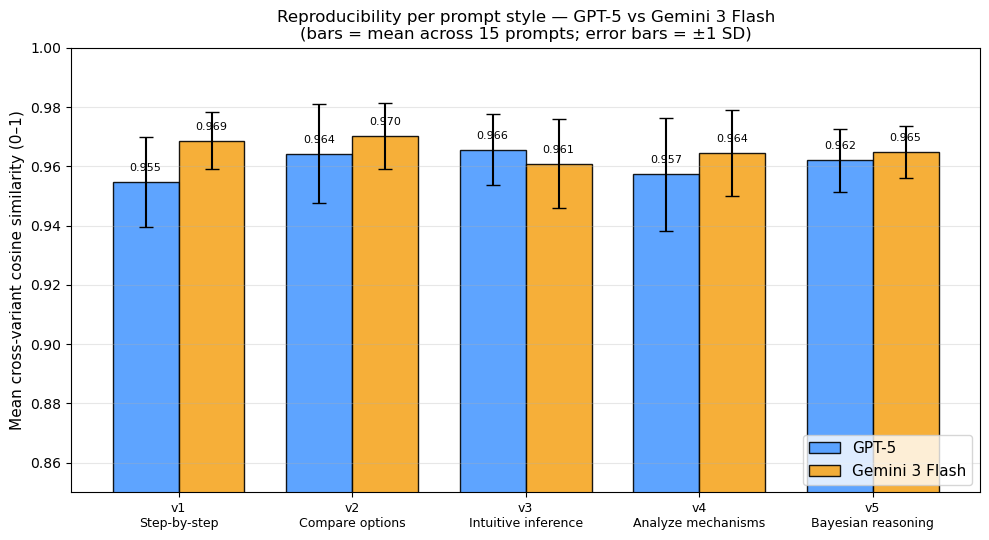

In [30]:
import matplotlib.pyplot as plt

# Normalize variant labels (GPT-5 uses int, Gemini uses 'v1'..'v5' strings)
def normalize_variant_label(v):
    s = str(v)
    if s.startswith('v'):
        return s
    return f'v{s}'

gpt5_pv = gpt5_per_variant.copy()
gpt5_pv['variant_label'] = gpt5_pv['variant_id'].apply(normalize_variant_label)
gemini_pv = gemini_per_variant.copy()
gemini_pv['variant_label'] = gemini_pv['variant_id'].apply(normalize_variant_label)

# Aggregate mean + SD per variant
gpt5_agg = gpt5_pv.groupby('variant_label')['mean_sim_01'].agg(['mean', 'std']).reset_index().sort_values('variant_label')
gemini_agg = gemini_pv.groupby('variant_label')['mean_sim_01'].agg(['mean', 'std']).reset_index().sort_values('variant_label')

variants = gpt5_agg['variant_label'].tolist()
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5.5))
bars_g = ax.bar(x - width/2, gpt5_agg['mean'], width,
                yerr=gpt5_agg['std'], label='GPT-5',
                color='#4C9AFF', edgecolor='black', capsize=5, alpha=0.9)
bars_m = ax.bar(x + width/2, gemini_agg['mean'], width,
                yerr=gemini_agg['std'], label='Gemini 3 Flash',
                color='#F5A623', edgecolor='black', capsize=5, alpha=0.9)

# Variant style labels (friendly names based on the prompt variants)
variant_descriptions = {
    'v1': 'v1\nStep-by-step',
    'v2': 'v2\nCompare options',
    'v3': 'v3\nIntuitive inference',
    'v4': 'v4\nAnalyze mechanisms',
    'v5': 'v5\nBayesian reasoning',
}

ax.set_xticks(x)
ax.set_xticklabels([variant_descriptions.get(v, v) for v in variants], fontsize=9)
ax.set_ylabel('Mean cross-variant cosine similarity (0–1)', fontsize=11)
ax.set_title('Reproducibility per prompt style — GPT-5 vs Gemini 3 Flash\n(bars = mean across 15 prompts; error bars = ±1 SD)', fontsize=12)
ax.set_ylim(0.85, 1.0)   # zoomed in since all values are high
ax.legend(fontsize=11, loc='lower right')
ax.grid(axis='y', alpha=0.3)

# Add value labels on top of each bar
for bars, agg in [(bars_g, gpt5_agg), (bars_m, gemini_agg)]:
    for bar, val in zip(bars, agg['mean']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_reproducibility_per_prompt_style.png', dpi=200)
plt.show()

# PART M: Main-paper bar graphs (MPNet only)
Clean per-prompt bar graphs using **only MPNet** (the main-paper transformer). I'll produce:
1. **Four individual graphs** — one per (model, method) combination
2. **Grouped by model** — GPT-5 panel + Gemini panel (each shows Repeat and Repro bars)
3. **Grouped by method** — Repeatability panel + Reproducibility panel (each shows both models)

All graphs use the MPNet `with_sw_removal_01` scores (rescaled 0–1).

### M.1 — Four individual graphs (one per model × method)

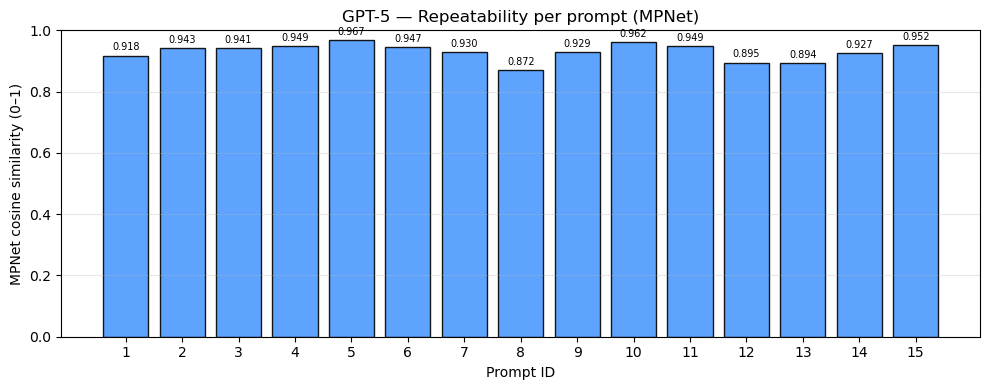

  saved → fig_mpnet_gpt5_repeatability.png


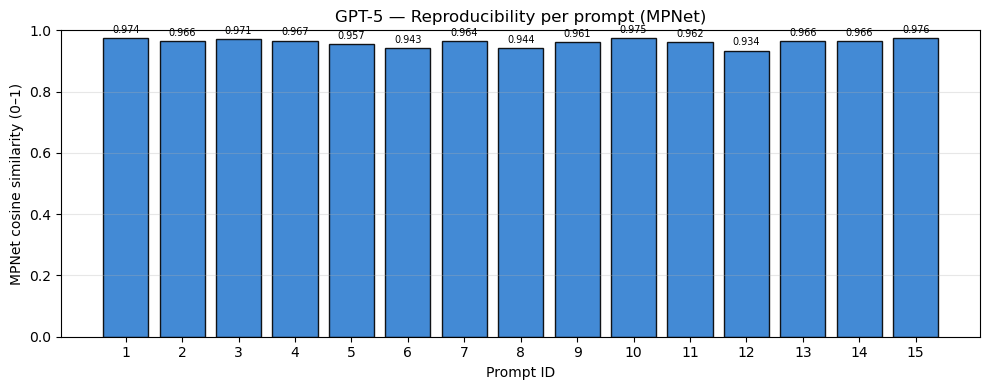

  saved → fig_mpnet_gpt5_reproducibility.png


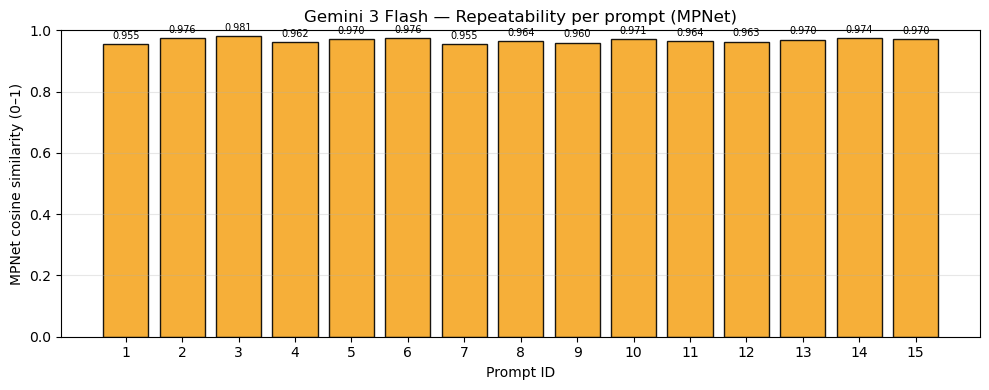

  saved → fig_mpnet_gemini_flash_repeatability.png


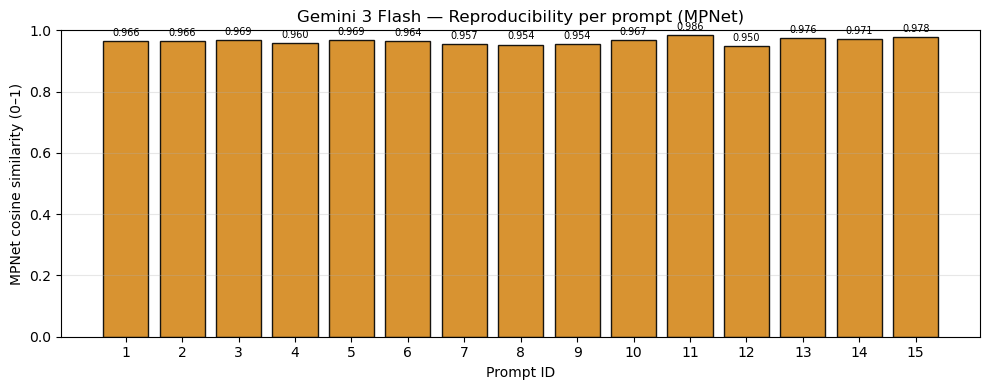

  saved → fig_mpnet_gemini_flash_reproducibility.png


In [31]:
import matplotlib.pyplot as plt
import numpy as np

MPNET_COL = 'mpnet_with_sw_removal_01'

# Build the four individual bar graphs
plots = [
    ('GPT-5',          'Repeatability',    repeat_all,       '#4C9AFF'),
    ('GPT-5',          'Reproducibility',  repro_all,        '#2E7DD1'),
    ('Gemini 3 Flash', 'Repeatability',    gemini_repeat_all,'#F5A623'),
    ('Gemini 3 Flash', 'Reproducibility',  gemini_repro_all, '#D4871A'),
]

for model_name, metric_name, df, color in plots:
    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(df))
    ax.bar(x, df[MPNET_COL], color=color, edgecolor='black', alpha=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(df['prompt_id'])
    ax.set_xlabel('Prompt ID')
    ax.set_ylabel('MPNet cosine similarity (0–1)')
    ax.set_title(f'{model_name} — {metric_name} per prompt (MPNet)')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
    # Value labels on top
    for xi, v in zip(x, df[MPNET_COL]):
        ax.text(xi, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=7)
    plt.tight_layout()
    safe_metric = metric_name.lower()
    safe_model = model_name.lower().replace(' ', '_').replace('-', '').replace('3_flash', 'flash')
    out = PROJECT_DIR / 'Analysis_Results_centroid' / f'fig_mpnet_{safe_model}_{safe_metric}.png'
    plt.savefig(out, dpi=200)
    plt.show()
    print(f'  saved → {out.name}')

### M.2 — Grouped by model (GPT-5 left, Gemini right)

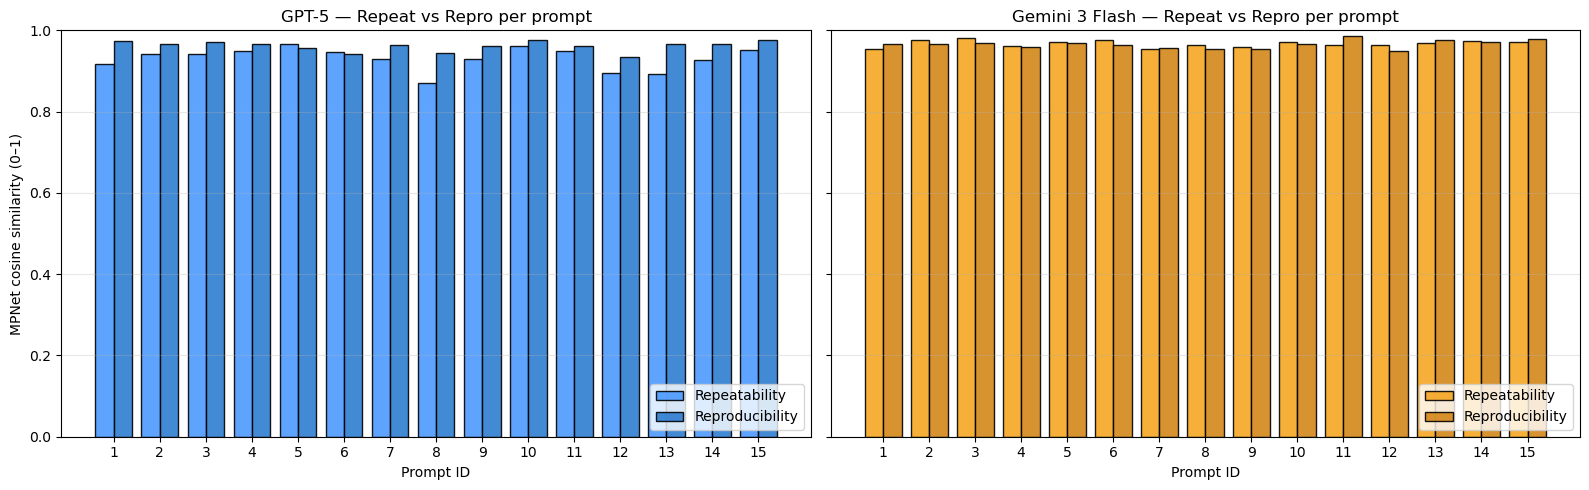

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
x = np.arange(len(repeat_all))
width = 0.4

# Left: GPT-5 (Repeat + Repro)
ax = axes[0]
ax.bar(x - width/2, repeat_all[MPNET_COL], width, label='Repeatability',
       color='#4C9AFF', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, repro_all[MPNET_COL], width, label='Reproducibility',
       color='#2E7DD1', edgecolor='black', alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID'); ax.set_ylabel('MPNet cosine similarity (0–1)')
ax.set_title('GPT-5 — Repeat vs Repro per prompt')
ax.set_ylim(0, 1); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

# Right: Gemini 3 Flash (Repeat + Repro)
ax = axes[1]
ax.bar(x - width/2, gemini_repeat_all[MPNET_COL], width, label='Repeatability',
       color='#F5A623', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repro_all[MPNET_COL], width, label='Reproducibility',
       color='#D4871A', edgecolor='black', alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(gemini_repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID')
ax.set_title('Gemini 3 Flash — Repeat vs Repro per prompt')
ax.set_ylim(0, 1); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_mpnet_grouped_by_model.png', dpi=200)
plt.show()

### M.3 — Grouped by method (Repeatability left, Reproducibility right)

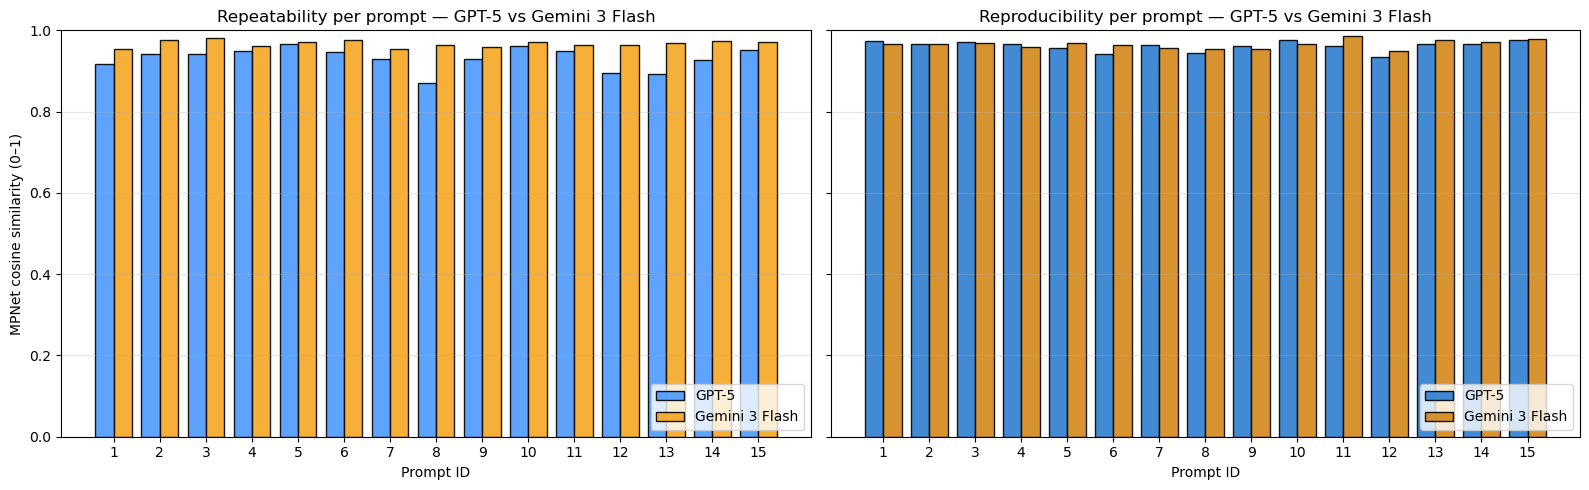

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
x = np.arange(len(repeat_all))
width = 0.4

# Left: Repeatability (GPT-5 + Gemini)
ax = axes[0]
ax.bar(x - width/2, repeat_all[MPNET_COL], width, label='GPT-5',
       color='#4C9AFF', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repeat_all[MPNET_COL], width, label='Gemini 3 Flash',
       color='#F5A623', edgecolor='black', alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID'); ax.set_ylabel('MPNet cosine similarity (0–1)')
ax.set_title('Repeatability per prompt — GPT-5 vs Gemini 3 Flash')
ax.set_ylim(0, 1); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

# Right: Reproducibility (GPT-5 + Gemini)
ax = axes[1]
ax.bar(x - width/2, repro_all[MPNET_COL], width, label='GPT-5',
       color='#2E7DD1', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repro_all[MPNET_COL], width, label='Gemini 3 Flash',
       color='#D4871A', edgecolor='black', alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(gemini_repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID')
ax.set_title('Reproducibility per prompt — GPT-5 vs Gemini 3 Flash')
ax.set_ylim(0, 1); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_mpnet_grouped_by_method.png', dpi=200)
plt.show()

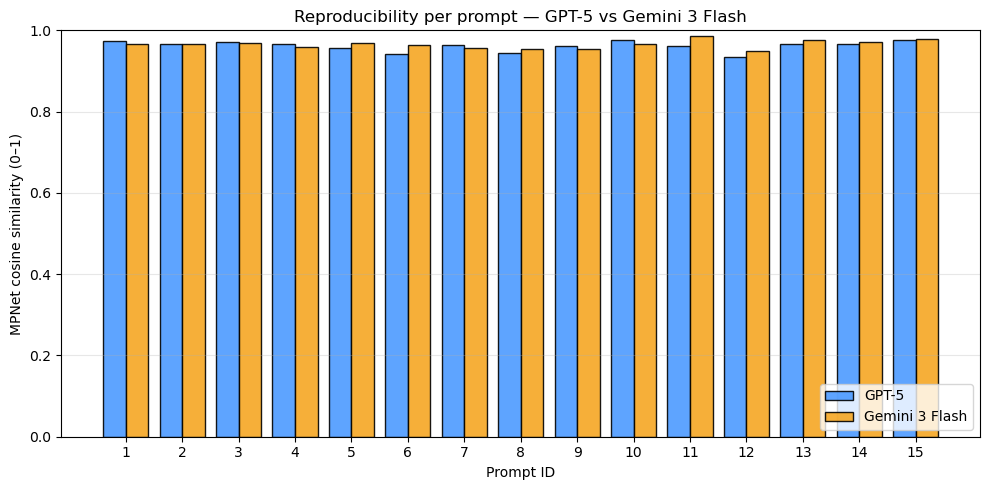

In [37]:
# Standalone reproducibility figure (same color palette as the repeatability panel)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(repro_all))
width = 0.4

ax.bar(x - width/2, repro_all[MPNET_COL], width, label='GPT-5',
       color='#4C9AFF', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repro_all[MPNET_COL], width, label='Gemini 3 Flash',
       color='#F5A623', edgecolor='black', alpha=0.9)

ax.set_xticks(x); ax.set_xticklabels(repro_all['prompt_id'])
ax.set_xlabel('Prompt ID'); ax.set_ylabel('MPNet cosine similarity (0–1)')
ax.set_title('Reproducibility per prompt — GPT-5 vs Gemini 3 Flash')
ax.set_ylim(0, 1); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_mpnet_reproducibility_only.png', dpi=200)
plt.show()

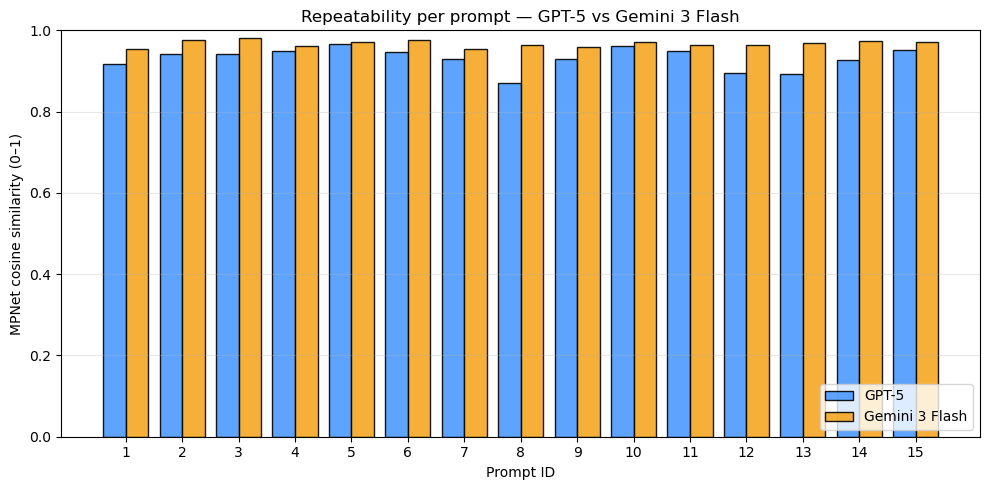

In [38]:
# Standalone repeatability figure (same color palette as the reproducibility panel)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(repeat_all))
width = 0.4

ax.bar(x - width/2, repeat_all[MPNET_COL], width, label='GPT-5',
       color='#4C9AFF', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repeat_all[MPNET_COL], width, label='Gemini 3 Flash',
       color='#F5A623', edgecolor='black', alpha=0.9)

ax.set_xticks(x); ax.set_xticklabels(repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID'); ax.set_ylabel('MPNet cosine similarity (0–1)')
ax.set_title('Repeatability per prompt — GPT-5 vs Gemini 3 Flash')
ax.set_ylim(0, 1); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_mpnet_repeatability_only.png', dpi=200)
plt.show()

New files from Part M (all saved in `Analysis_Results/`)
Individual:
- `fig_mpnet_gpt5_repeatability.png`
- `fig_mpnet_gpt5_reproducibility.png`
- `fig_mpnet_gemini_flash_repeatability.png`
- `fig_mpnet_gemini_flash_reproducibility.png`

Grouped:
- `fig_mpnet_grouped_by_model.png` — GPT-5 panel + Gemini panel
- `fig_mpnet_grouped_by_method.png` — Repeatability panel + Reproducibility panel

# PART N: Supplementary — stopword removal effect across transformers
This part answers the supplementary question: *does stopword removal change the semantic consistency scores, and does the effect depend on which transformer is used?* 
Both preprocessing options were already computed for all 4 transformers in Parts A, B, E, and F — the data is already in `repeat_all`, `repro_all`, `gemini_repeat_all`, and `gemini_repro_all`. This section just visualizes them side-by-side.**Produces:**
- One summary CSV showing the mean difference per (transformer, model, metric) — `stopword_effect_summary.csv`
- One 2×2 figure (GPT-5 Repeat, GPT-5 Repro, Gemini Repeat, Gemini Repro), each panel showing 4 transformers with both preprocessing versions — `fig_stopword_effect_supplementary.png`

### N.1 Build the summary comparison table

In [34]:
transformers_for_plot = [
    ('minilm',    'MiniLM-L6-v2'),
    ('mpnet',     'MPNet-base-v2'),
    ('bge-large', 'BGE-large-en-v1.5'),
    ('oai-large', 'OpenAI text-embedding-3-large'),
]

rows = []
for model_label, repeat_df_, repro_df_ in [
    ('GPT-5', repeat_all, repro_all),
    ('Gemini 3 Flash', gemini_repeat_all, gemini_repro_all),
]:
    for metric_label, df_ in [('Repeatability', repeat_df_), ('Reproducibility', repro_df_)]:
        for tkey, tname in transformers_for_plot:
            with_sw = df_[f'{tkey}_with_sw_removal_01']
            no_sw   = df_[f'{tkey}_no_sw_removal_01']
            rows.append({
                'Model': model_label,
                'Metric': metric_label,
                'Transformer': tname,
                'Mean (with SW removal)': with_sw.mean(),
                'Mean (no SW removal)':   no_sw.mean(),
                'Mean difference':        no_sw.mean() - with_sw.mean(),
                'SD across prompts (with SW)': with_sw.std(),
                'SD across prompts (no SW)':   no_sw.std(),
            })

stopword_summary = pd.DataFrame(rows)
stopword_summary.to_csv(PROJECT_DIR / 'Analysis_Results_centroid' / 'stopword_effect_summary.csv', index=False)

# Formatted display
import pandas as pd
pd.set_option('display.float_format', '{:.4f}'.format)
stopword_summary

,Model,Metric,Transformer,Mean (with SW removal),Mean (no SW removal),Mean difference,SD across prompts (with SW),SD across prompts (no SW)
0,GPT-5,Repeatability,MiniLM-L6-v2,0.9320,0.9321,0.0001,0.0283,0.0212
1,GPT-5,Repeatability,MPNet-base-v2,0.9316,0.9542,0.0226,0.0271,0.0196
2,GPT-5,Repeatability,BGE-large-en-v1.5,0.9443,0.9598,0.0155,0.0180,0.0155
3,GPT-5,Repeatability,OpenAI text-embedding-3-large,0.9380,0.9540,0.0160,0.0232,0.0180
4,GPT-5,Reproducibility,MiniLM-L6-v2,0.9607,0.9347,-0.0260,0.0184,0.0226
5,GPT-5,Reproducibility,MPNet-base-v2,0.9616,0.9599,-0.0017,0.0125,0.0121
6,GPT-5,Reproducibility,BGE-large-en-v1.5,0.9690,0.9704,0.0015,0.0087,0.0080
7,GPT-5,Reproducibility,OpenAI text-embedding-3-large,0.9678,0.9632,-0.0047,0.0107,0.0113
8,Gemini 3 Flash,Repeatability,MiniLM-L6-v2,0.9619,0.9497,-0.0122,0.0060,0.0109
9,Gemini 3 Flash,Repeatability,MPNet-base-v2,0.9675,0.9719,0.0044,0.0077,0.0094


### N.2 Grouped bar chart — 2×2 panel (model × metric), 4 transformers × 2 preprocessing

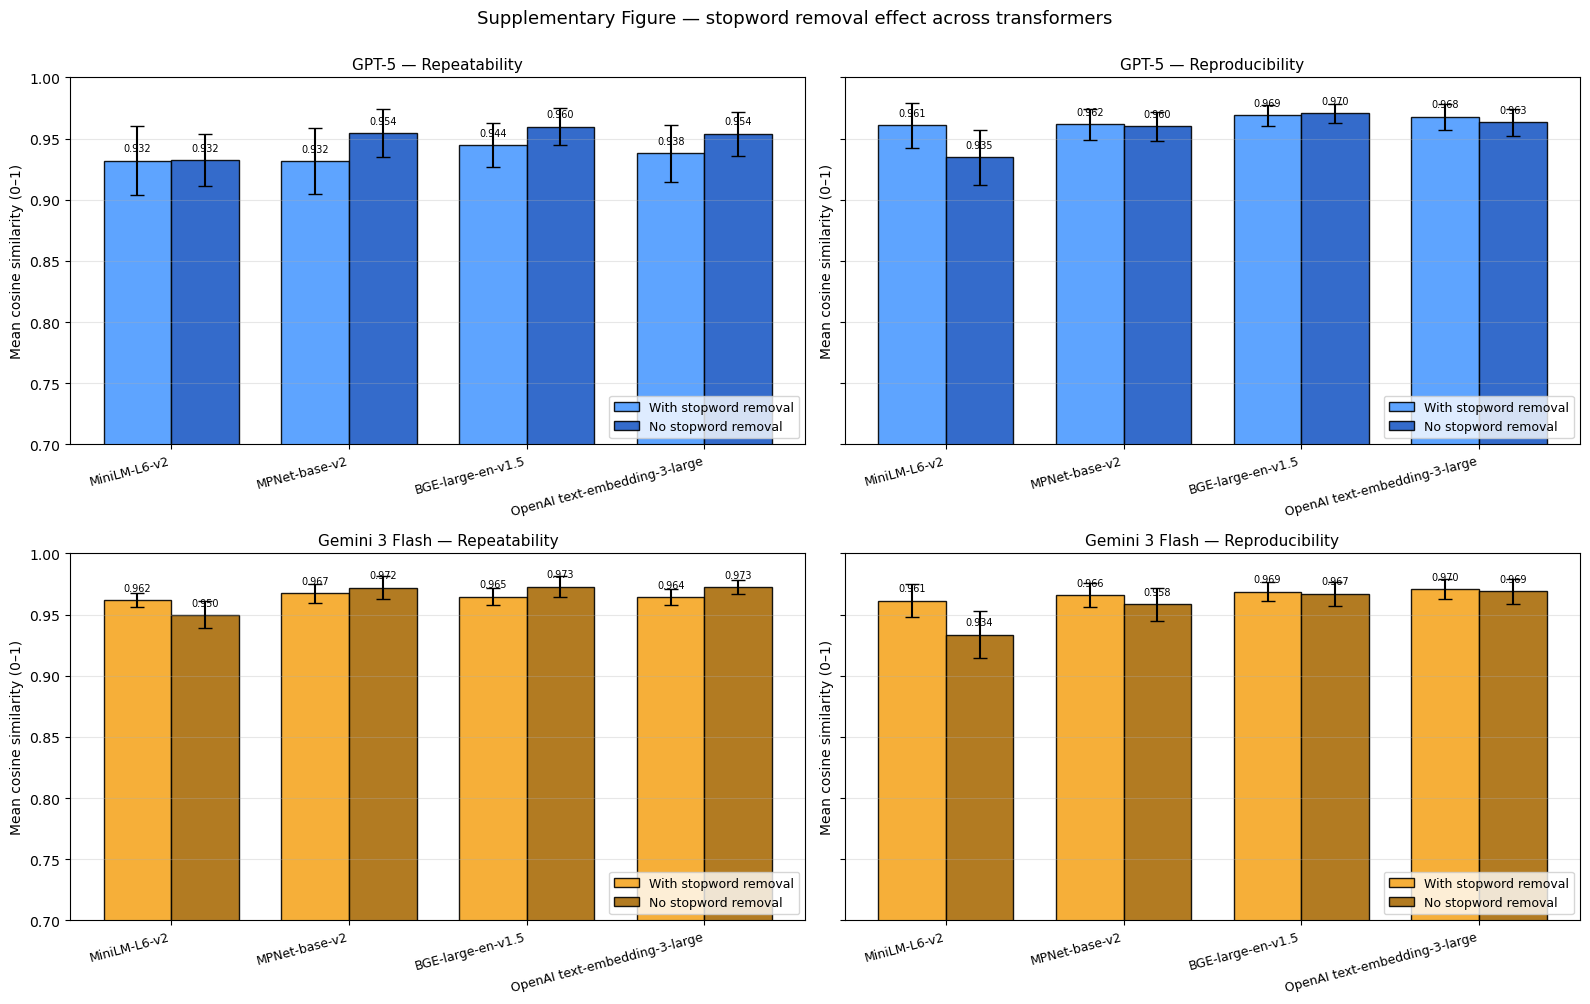

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
width = 0.38
x = np.arange(len(transformers_for_plot))
tnames = [t[1] for t in transformers_for_plot]

cells = [
    (axes[0, 0], 'GPT-5 — Repeatability',           repeat_all,          '#4C9AFF', '#1E5BC6'),
    (axes[0, 1], 'GPT-5 — Reproducibility',         repro_all,           '#4C9AFF', '#1E5BC6'),
    (axes[1, 0], 'Gemini 3 Flash — Repeatability',  gemini_repeat_all,   '#F5A623', '#AA6D0A'),
    (axes[1, 1], 'Gemini 3 Flash — Reproducibility',gemini_repro_all,    '#F5A623', '#AA6D0A'),
]

for ax, title, df_, color_with, color_no in cells:
    with_sw_means = [df_[f'{tkey}_with_sw_removal_01'].mean() for tkey, _ in transformers_for_plot]
    no_sw_means   = [df_[f'{tkey}_no_sw_removal_01'].mean()   for tkey, _ in transformers_for_plot]
    with_sw_sds   = [df_[f'{tkey}_with_sw_removal_01'].std()  for tkey, _ in transformers_for_plot]
    no_sw_sds     = [df_[f'{tkey}_no_sw_removal_01'].std()    for tkey, _ in transformers_for_plot]

    b1 = ax.bar(x - width/2, with_sw_means, width, yerr=with_sw_sds,
                label='With stopword removal', color=color_with, edgecolor='black', capsize=5, alpha=0.9)
    b2 = ax.bar(x + width/2, no_sw_means, width, yerr=no_sw_sds,
                label='No stopword removal', color=color_no, edgecolor='black', capsize=5, alpha=0.9)

    ax.set_xticks(x)
    ax.set_xticklabels(tnames, rotation=15, ha='right', fontsize=9)
    ax.set_ylabel('Mean cosine similarity (0–1)', fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0.7, 1.0)
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(axis='y', alpha=0.3)

    # Value labels above each bar
    for bars, means in [(b1, with_sw_means), (b2, no_sw_means)]:
        for bar, v in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.006,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=7)

fig.suptitle('Supplementary Figure — stopword removal effect across transformers',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig(PROJECT_DIR / 'Analysis_Results_centroid' / 'fig_stopword_effect_supplementary.png', dpi=200, bbox_inches='tight')
plt.show()

### N.3 Quick interpretation helper — biggest shifts

In [36]:
biggest = stopword_summary.copy()
biggest['Abs difference'] = biggest['Mean difference'].abs()
biggest = biggest.sort_values('Abs difference', ascending=False)
print('Largest absolute shifts from stopword removal (positive = no-SW is higher):')
print(biggest[['Model', 'Metric', 'Transformer', 'Mean (with SW removal)',
               'Mean (no SW removal)', 'Mean difference']].head(10).to_string(index=False))

Largest absolute shifts from stopword removal (positive = no-SW is higher):
         Model          Metric                   Transformer  Mean (with SW removal)  Mean (no SW removal)  Mean difference
Gemini 3 Flash Reproducibility                  MiniLM-L6-v2                  0.9614                0.9336          -0.0278
         GPT-5 Reproducibility                  MiniLM-L6-v2                  0.9607                0.9347          -0.0260
         GPT-5   Repeatability                 MPNet-base-v2                  0.9316                0.9542           0.0226
         GPT-5   Repeatability OpenAI text-embedding-3-large                  0.9380                0.9540           0.0160
         GPT-5   Repeatability             BGE-large-en-v1.5                  0.9443                0.9598           0.0155
Gemini 3 Flash   Repeatability                  MiniLM-L6-v2                  0.9619                0.9497          -0.0122
Gemini 3 Flash   Repeatability OpenAI text-embedding-3-l

---
# PART O: Figures for Paper

This section contains the final, publication-ready figures for the manuscript.
Each figure here supersedes any earlier draft version in Parts D, H, I.6, M, N, etc.
All cells are self-contained: they re-import libraries and reload data from the saved
CSV outputs so this section can be run independently of the preceding analysis cells.

### O.0 — Imports and data loading

This first cell loads every library and every intermediate dataset needed to produce
the figures in Part O. It reads from the already-saved CSVs in `Analysis_Results_centroid/`
(produced by Parts I.2, I.3, and K) so no re-computation is required.

**Variables made available after running this cell:**
- `gpt5_per_variant`, `gemini_per_variant` — per-prompt, per-variant reproducibility scores (centroid-based)
- `PROJECT_DIR`, `FIG_DIR` — path shortcuts for saving figures

In [1]:
# === Part O setup: imports + load all datasets needed by the figures ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path('/Users/luizzadallapria/Documents/GPT5_Study')
RESULTS_DIR = PROJECT_DIR / 'Analysis_Results_centroid'
FIG_DIR     = PROJECT_DIR / 'Figures_For_Paper'
FIG_DIR.mkdir(exist_ok=True)

# --- Per-variant reproducibility (centroid-based, MPNet) — used by O.1 ---
gpt5_per_variant   = pd.read_csv(RESULTS_DIR / 'per_variant_repro_gpt5.csv')
gemini_per_variant = pd.read_csv(RESULTS_DIR / 'per_variant_repro_gemini.csv')

# --- Per-prompt repeatability and reproducibility (all transformers) — used by O.2 ---
repeat_all        = pd.read_csv(RESULTS_DIR / 'repeatability_all_metrics.csv')
repro_all         = pd.read_csv(RESULTS_DIR / 'reproducibility_all_metrics.csv')
gemini_repeat_all = pd.read_csv(RESULTS_DIR / 'repeatability_all_metrics_gemini.csv')
gemini_repro_all  = pd.read_csv(RESULTS_DIR / 'reproducibility_all_metrics_gemini.csv')

# Main-paper transformer column (MPNet with stop-word removal, rescaled 0–1)
MPNET_COL = 'mpnet_with_sw_removal_01'

print('Per-variant:')
print('  gpt5_per_variant   :', gpt5_per_variant.shape)
print('  gemini_per_variant :', gemini_per_variant.shape)
print('Per-prompt:')
print('  repeat_all         :', repeat_all.shape)
print('  repro_all          :', repro_all.shape)
print('  gemini_repeat_all  :', gemini_repeat_all.shape)
print('  gemini_repro_all   :', gemini_repro_all.shape)
print('Figures will be saved to :', FIG_DIR)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/luizzadallapria/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/luizzadallapria/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/luizzadallapria/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loo

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/luizzadallapria/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/luizzadallapria/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/luizzadallapria/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loo

AttributeError: _ARRAY_API not found

Per-variant:
  gpt5_per_variant   : (75, 6)
  gemini_per_variant : (75, 6)
Per-prompt:
  repeat_all         : (15, 18)
  repro_all          : (15, 18)
  gemini_repeat_all  : (15, 18)
  gemini_repro_all   : (15, 18)
Figures will be saved to : /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper


### O.1 — Figure 2: Mean reproducibility per CoT variant (truncated y-axis)

Line chart overlaying GPT-5 and Gemini 3 Flash, with mean reproducibility per variant
(averaged over the 15 prompts) and error bars = ±1 SD across prompts.

**Change vs. earlier draft (Part I.6, Fig 3):** the y-axis is truncated to **[0.85, 1.0]**
so the standard-deviation bars are visually distinguishable. All scores lie within this
range in both models, so no data is clipped. The caption notes the truncation.

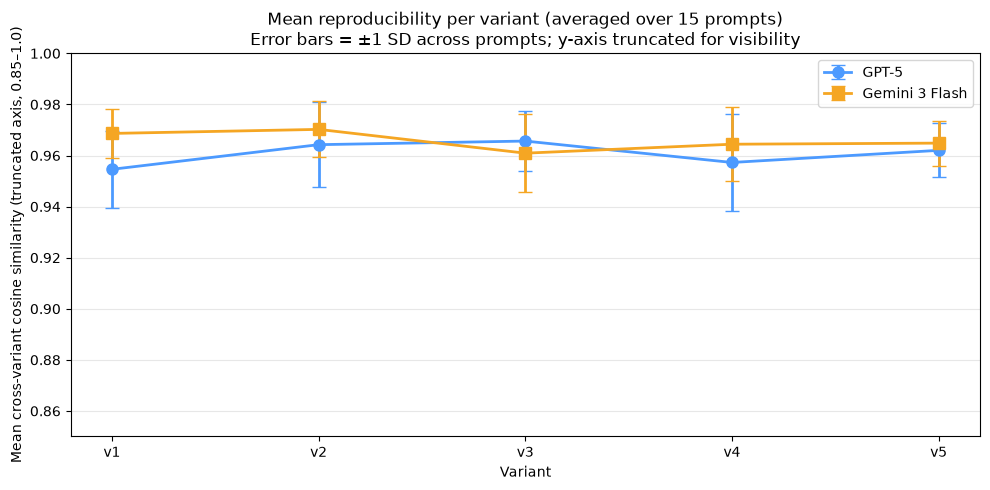

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/Fig2_mean_reproducibility_per_variant.png


In [2]:
import matplotlib.pyplot as plt
# Figure 2 (paper) — mean reproducibility per CoT variant, truncated y-axis
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, df_m, color, marker in [
    ('GPT-5',          gpt5_per_variant,   '#4C9AFF', 'o'),
    ('Gemini 3 Flash', gemini_per_variant, '#F5A623', 's'),
]:
    means = df_m.groupby('variant_id')['mean_sim_01'].mean()
    stds  = df_m.groupby('variant_id')['mean_sim_01'].std()
    ax.errorbar(range(len(means)), means.values, yerr=stds.values,
                marker=marker, color=color, label=model_name,
                capsize=5, linewidth=2, markersize=8)

ax.set_xticks(range(5))
ax.set_xticklabels([f'v{i+1}' for i in range(5)])
ax.set_xlabel('Variant')
ax.set_ylabel('Mean cross-variant cosine similarity (truncated axis, 0.85–1.0)')
ax.set_title('Mean reproducibility per variant (averaged over 15 prompts)\n'
             'Error bars = ±1 SD across prompts; y-axis truncated for visibility')
ax.set_ylim(0.85, 1.0)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
out_path = FIG_DIR / 'Fig2_mean_reproducibility_per_variant.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.2 — Figure 1: Per-prompt Repeat vs Repro, grouped by model (truncated y-axis)

Side-by-side panels — GPT-5 (left) and Gemini 3 Flash (right) — each showing
repeatability and reproducibility bars for all 15 prompts, using the MPNet
transformer with stop-word removal (`mpnet_with_sw_removal_01`).

**Change vs. earlier draft (Part M.2):**
- The y-axis is truncated to **[0.85, 1.0]** so that the per-prompt differences
  between repeatability and reproducibility are visually distinguishable
  (all values fall in a narrow high band of the full [0, 1] scale).
- Saved at 300 dpi to `Figures_For_Paper/` as a publication-ready file.
- Caption should note the truncation to avoid misreading the visual spread as full scale.

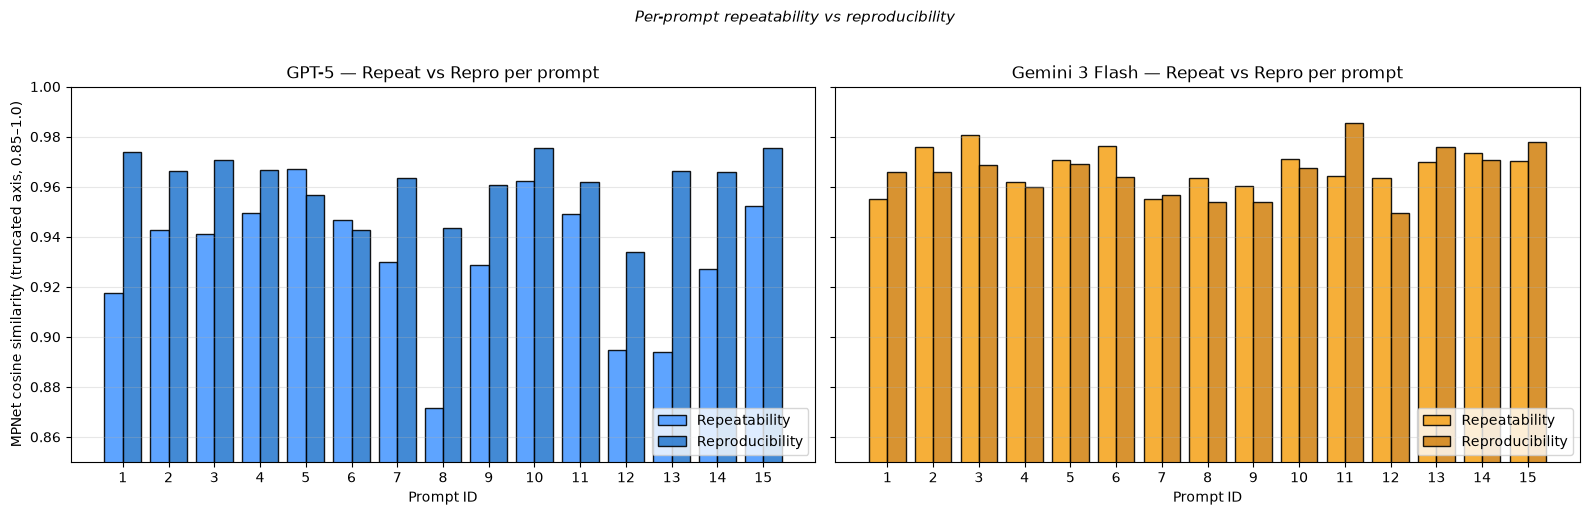

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/Fig1_repeat_vs_repro_per_prompt.png


In [3]:
# Figure 1 (paper) — Repeat vs Repro per prompt, GPT-5 left, Gemini right (truncated y-axis)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
x = np.arange(len(repeat_all))
width = 0.4

# Left: GPT-5 (Repeat + Repro)
ax = axes[0]
ax.bar(x - width/2, repeat_all[MPNET_COL], width, label='Repeatability',
       color='#4C9AFF', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, repro_all[MPNET_COL],  width, label='Reproducibility',
       color='#2E7DD1', edgecolor='black', alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID')
ax.set_ylabel('MPNet cosine similarity (truncated axis, 0.85–1.0)')
ax.set_title('GPT-5 — Repeat vs Repro per prompt')
ax.set_ylim(0.85, 1.0); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

# Right: Gemini 3 Flash (Repeat + Repro)
ax = axes[1]
ax.bar(x - width/2, gemini_repeat_all[MPNET_COL], width, label='Repeatability',
       color='#F5A623', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repro_all[MPNET_COL],  width, label='Reproducibility',
       color='#D4871A', edgecolor='black', alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(gemini_repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID')
ax.set_title('Gemini 3 Flash — Repeat vs Repro per prompt')
ax.set_ylim(0.85, 1.0); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.suptitle('Per-prompt repeatability vs reproducibility',
             y=1.02, fontsize=11, style='italic')
plt.tight_layout()
out_path = FIG_DIR / 'Fig1_repeat_vs_repro_per_prompt.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.3 — Figure 3: Repeatability per prompt — GPT-5 vs Gemini 3 Flash (truncated y-axis)

Standalone bar chart showing per-prompt **repeatability** scores for GPT-5 and
Gemini 3 Flash side by side, using the MPNet transformer with stop-word removal.

**Change vs. earlier draft (Part M, standalone repeatability):**
- Y-axis truncated to **[0.85, 1.0]** so between-model and between-prompt differences are visible.
- Saved at 300 dpi to `Figures_For_Paper/` as a publication-ready file.

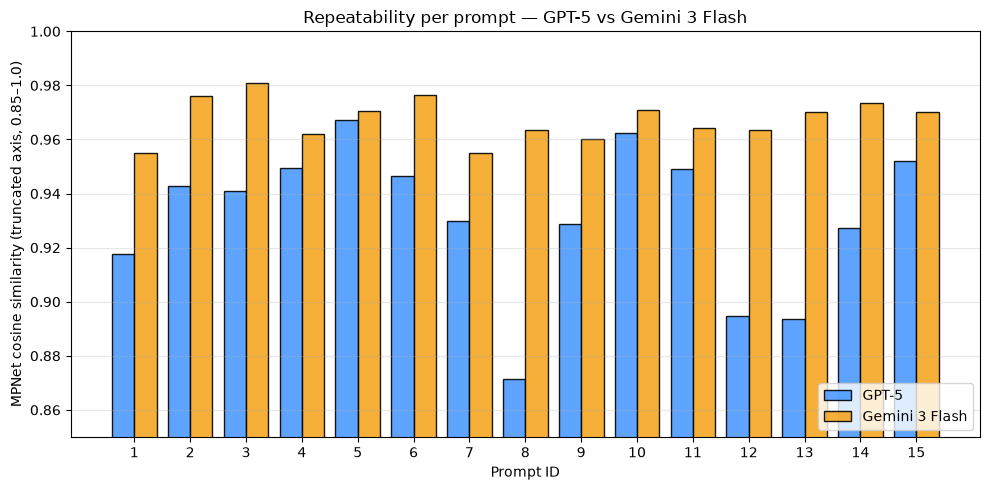

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/Fig3_repeatability_per_prompt.png


In [2]:
# Figure 3 (paper) — Repeatability per prompt, GPT-5 vs Gemini (truncated y-axis)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(repeat_all))
width = 0.4

ax.bar(x - width/2, repeat_all[MPNET_COL], width, label='GPT-5',
       color='#4C9AFF', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repeat_all[MPNET_COL], width, label='Gemini 3 Flash',
       color='#F5A623', edgecolor='black', alpha=0.9)

ax.set_xticks(x); ax.set_xticklabels(repeat_all['prompt_id'])
ax.set_xlabel('Prompt ID')
ax.set_ylabel('MPNet cosine similarity (truncated axis, 0.85–1.0)')
ax.set_title('Repeatability per prompt — GPT-5 vs Gemini 3 Flash')
ax.set_ylim(0.85, 1.0); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
out_path = FIG_DIR / 'Fig3_repeatability_per_prompt.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.4 — Figure 4: Reproducibility per prompt — GPT-5 vs Gemini 3 Flash (truncated y-axis)

Standalone bar chart showing per-prompt **reproducibility** scores for GPT-5 and
Gemini 3 Flash side by side, using the MPNet transformer with stop-word removal.

**Change vs. earlier draft (Part M, standalone reproducibility):**
- Y-axis truncated to **[0.85, 1.0]** so between-model and between-prompt differences are visible.
- Saved at 300 dpi to `Figures_For_Paper/` as a publication-ready file.

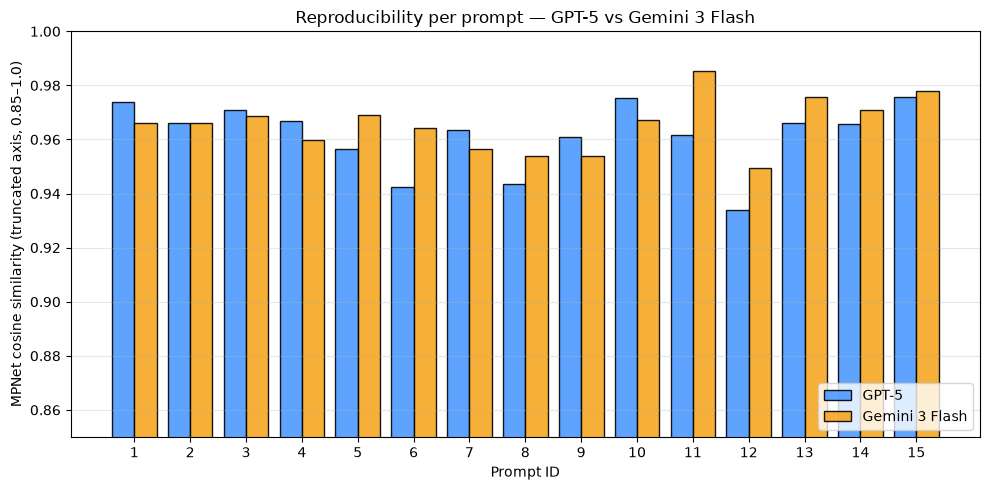

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/Fig4_reproducibility_per_prompt.png


In [5]:
# Figure 4 (paper) — Reproducibility per prompt, GPT-5 vs Gemini (truncated y-axis)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(repro_all))
width = 0.4

ax.bar(x - width/2, repro_all[MPNET_COL], width, label='GPT-5',
       color='#4C9AFF', edgecolor='black', alpha=0.9)
ax.bar(x + width/2, gemini_repro_all[MPNET_COL], width, label='Gemini 3 Flash',
       color='#F5A623', edgecolor='black', alpha=0.9)

ax.set_xticks(x); ax.set_xticklabels(repro_all['prompt_id'])
ax.set_xlabel('Prompt ID')
ax.set_ylabel('MPNet cosine similarity (truncated axis, 0.85–1.0)')
ax.set_title('Reproducibility per prompt — GPT-5 vs Gemini 3 Flash')
ax.set_ylim(0.85, 1.0); ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
out_path = FIG_DIR / 'Fig4_reproducibility_per_prompt.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.5 — Figure S2 (candidate): GPT-5 per-prompt Repeat & Repro across all four embedding models (truncated y-axis)

Side-by-side panels showing per-prompt repeatability (left) and reproducibility (right)
for GPT-5, with four bars per prompt — one for each sentence-transformer
(MiniLM-L6-v2, MPNet-base-v2, BGE-large-en-v1.5, OpenAI text-embedding-3-large).
Scores are the stop-word-removed, rescaled [0, 1] versions.

**Change vs. earlier draft (Part D, Fig 1):**
- Y-axis truncated to **[0.85, 1.0]** so between-transformer and between-prompt differences become visible.
- Saved at 300 dpi to `Figures_For_Paper/`.

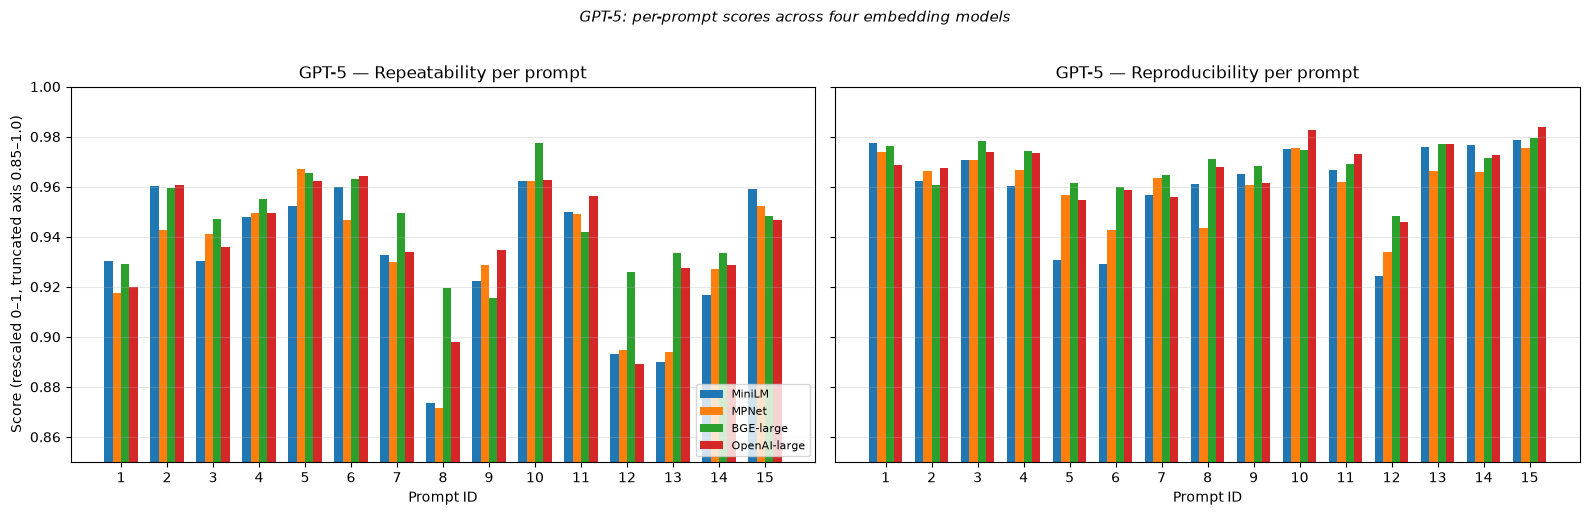

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/FigS2_gpt5_per_prompt_all_transformers.png


In [6]:
# Figure S2 (candidate) — GPT-5 per-prompt Repeat & Repro, 4 embedding models (truncated y-axis)
headline_metrics = [
    ('minilm_with_sw_removal_01',   'MiniLM'),
    ('mpnet_with_sw_removal_01',    'MPNet'),
    ('bge-large_with_sw_removal_01','BGE-large'),
    ('oai-large_with_sw_removal_01','OpenAI-large'),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
x = np.arange(len(repeat_all))
width = 0.18

ax = axes[0]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, repeat_all[col], width, label=label)
ax.set_xticks(x); ax.set_xticklabels(repeat_all['prompt_id'])
ax.set_title('GPT-5 — Repeatability per prompt')
ax.set_xlabel('Prompt ID')
ax.set_ylabel('Score (rescaled 0–1, truncated axis 0.85–1.0)')
ax.set_ylim(0.85, 1.0); ax.legend(fontsize=8, loc='lower right')
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, repro_all[col], width, label=label)
ax.set_xticks(x); ax.set_xticklabels(repro_all['prompt_id'])
ax.set_title('GPT-5 — Reproducibility per prompt')
ax.set_xlabel('Prompt ID')
ax.set_ylim(0.85, 1.0)
ax.grid(axis='y', alpha=0.3)

plt.suptitle('GPT-5: per-prompt scores across four embedding models',
             y=1.02, fontsize=11, style='italic')
plt.tight_layout()
out_path = FIG_DIR / 'FigS2_gpt5_per_prompt_all_transformers.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.6 — Figure S3 (candidate): Gemini 3 Flash per-prompt Repeat & Repro across all four embedding models (truncated y-axis)

Same layout as O.5, but for Gemini 3 Flash.

**Change vs. earlier draft (Part H, Fig 1 Gemini):**
- Y-axis truncated to **[0.85, 1.0]** so between-transformer and between-prompt differences become visible.
- Saved at 300 dpi to `Figures_For_Paper/`.

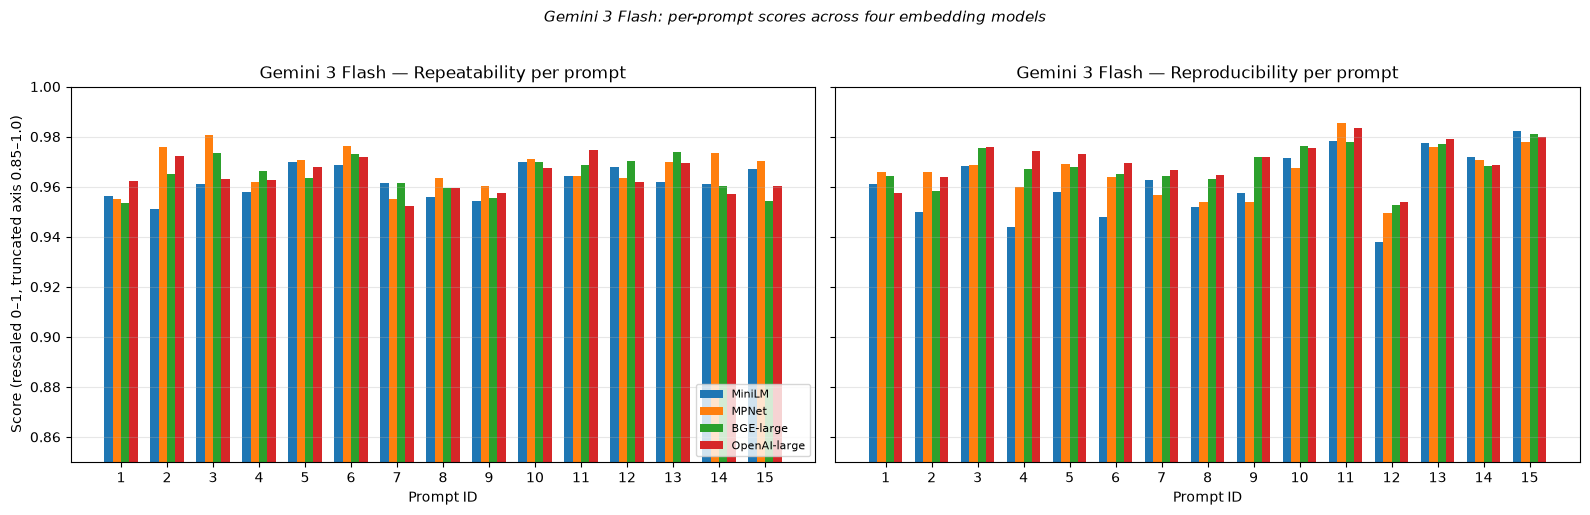

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/FigS3_gemini_per_prompt_all_transformers.png


In [7]:
# Figure S3 (candidate) — Gemini 3 Flash per-prompt Repeat & Repro, 4 embedding models (truncated y-axis)
headline_metrics = [
    ('minilm_with_sw_removal_01',   'MiniLM'),
    ('mpnet_with_sw_removal_01',    'MPNet'),
    ('bge-large_with_sw_removal_01','BGE-large'),
    ('oai-large_with_sw_removal_01','OpenAI-large'),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
x = np.arange(len(gemini_repeat_all))
width = 0.18

ax = axes[0]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, gemini_repeat_all[col], width, label=label)
ax.set_xticks(x); ax.set_xticklabels(gemini_repeat_all['prompt_id'])
ax.set_title('Gemini 3 Flash — Repeatability per prompt')
ax.set_xlabel('Prompt ID')
ax.set_ylabel('Score (rescaled 0–1, truncated axis 0.85–1.0)')
ax.set_ylim(0.85, 1.0); ax.legend(fontsize=8, loc='lower right')
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
for i, (col, label) in enumerate(headline_metrics):
    ax.bar(x + i*width - 1.5*width, gemini_repro_all[col], width, label=label)
ax.set_xticks(x); ax.set_xticklabels(gemini_repro_all['prompt_id'])
ax.set_title('Gemini 3 Flash — Reproducibility per prompt')
ax.set_xlabel('Prompt ID')
ax.set_ylim(0.85, 1.0)
ax.grid(axis='y', alpha=0.3)

plt.suptitle('Gemini 3 Flash: per-prompt scores across four embedding models',
             y=1.02, fontsize=11, style='italic')
plt.tight_layout()
out_path = FIG_DIR / 'FigS3_gemini_per_prompt_all_transformers.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.7 — Figure 2 (replacement): Boxplot of per-variant reproducibility, GPT-5 vs Gemini 3 Flash (truncated y-axis)

Replaces the earlier line-chart version of Figure 2 (cell O.1). Side-by-side boxplots
show the distribution of the 15 per-prompt reproducibility scores for each CoT variant,
with GPT-5 (blue) and Gemini 3 Flash (orange) grouped per variant. Individual per-prompt
points are jittered on top of each box.

**Why boxplot instead of mean ± SD line chart (per professor’s suggestion):**
- Aligns with the non-parametric Friedman + Wilcoxon tests used in §3.5 (medians/ranks vs. means/SDs).
- Shows the full distribution shape — median, IQR, whiskers, outliers — not just center and spread.
- Lets readers visually eyeball the significant pairwise differences flagged in Table 6.
- More honest small-n picture (n = 15 per variant) with individual points overlaid.

**Output:** `Figures_For_Paper/Fig2_reproducibility_per_variant_boxplot.png` at 300 dpi.
Y-axis truncated to [0.85, 1.0] to match the other paper figures and let the boxes breathe.

Data check (should be 15 points per box):
  v1: GPT-5 n=15 median=0.9546  |  Gemini n=15 median=0.9701
  v2: GPT-5 n=15 median=0.9682  |  Gemini n=15 median=0.9723
  v3: GPT-5 n=15 median=0.9704  |  Gemini n=15 median=0.9615
  v4: GPT-5 n=15 median=0.9596  |  Gemini n=15 median=0.9647
  v5: GPT-5 n=15 median=0.9634  |  Gemini n=15 median=0.9649


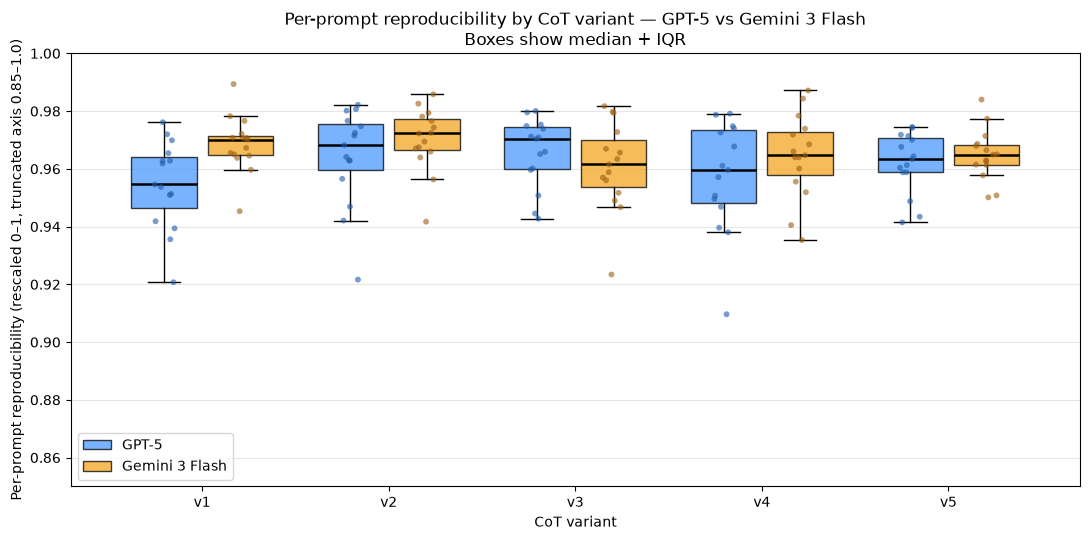

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/Fig2_reproducibility_per_variant_boxplot.png


In [4]:
# Figure 2 replacement — grouped boxplot: per-variant reproducibility, GPT-5 vs Gemini (truncated)
import matplotlib.pyplot as plt
import numpy as np
import re

# --- Normalize variant IDs: GPT-5 stores int (1..5), Gemini stores strings ('v1'..'v5') ---
def _to_int_variant(v):
    s = str(v).strip()
    m = re.search(r'\d+', s)
    return int(m.group()) if m else None

gpt5_df   = gpt5_per_variant.copy()
gemini_df = gemini_per_variant.copy()
gpt5_df['variant_num']   = gpt5_df['variant_id'].apply(_to_int_variant)
gemini_df['variant_num'] = gemini_df['variant_id'].apply(_to_int_variant)

variants = sorted(v for v in set(gpt5_df['variant_num']).union(gemini_df['variant_num']) if v is not None)
n_v = len(variants)

fig, ax = plt.subplots(figsize=(11, 5.5))
box_width = 0.35
positions_gpt5   = np.arange(n_v) - box_width/2 - 0.03
positions_gemini = np.arange(n_v) + box_width/2 + 0.03

gpt5_data   = [gpt5_df.loc[gpt5_df['variant_num']   == v, 'mean_sim_01'].values for v in variants]
gemini_data = [gemini_df.loc[gemini_df['variant_num'] == v, 'mean_sim_01'].values for v in variants]

print('Data check (should be 15 points per box):')
for v, g, m in zip(variants, gpt5_data, gemini_data):
    print(f'  v{v}: GPT-5 n={len(g)} median={np.median(g):.4f}  |  Gemini n={len(m)} median={np.median(m):.4f}')

bp1 = ax.boxplot(gpt5_data,   positions=positions_gpt5,   widths=box_width,
                 patch_artist=True, medianprops=dict(color='black', linewidth=1.8),
                 boxprops=dict(facecolor='#4C9AFF', edgecolor='black', alpha=0.75),
                 whiskerprops=dict(color='black'), capprops=dict(color='black'),
                 flierprops=dict(marker='o', markerfacecolor='#4C9AFF', markeredgecolor='black', markersize=5),
                 showfliers=False)

bp2 = ax.boxplot(gemini_data, positions=positions_gemini, widths=box_width,
                 patch_artist=True, medianprops=dict(color='black', linewidth=1.8),
                 boxprops=dict(facecolor='#F5A623', edgecolor='black', alpha=0.75),
                 whiskerprops=dict(color='black'), capprops=dict(color='black'),
                 flierprops=dict(marker='s', markerfacecolor='#F5A623', markeredgecolor='black', markersize=5),
                 showfliers=False)

# Overlay individual jittered points
rng = np.random.default_rng(42)
for i, (d_g, d_m) in enumerate(zip(gpt5_data, gemini_data)):
    jitter_g = rng.uniform(-0.06, 0.06, size=len(d_g))
    jitter_m = rng.uniform(-0.06, 0.06, size=len(d_m))
    ax.scatter(positions_gpt5[i]   + jitter_g, d_g, color='#1F5BA8', s=18, alpha=0.6, zorder=3, edgecolors='none')
    ax.scatter(positions_gemini[i] + jitter_m, d_m, color='#9A5E13', s=18, alpha=0.6, zorder=3, edgecolors='none')


ax.set_xticks(range(n_v))
ax.set_xticklabels([f'v{v}' for v in variants])
ax.set_xlabel('CoT variant')
ax.set_ylabel('Per-prompt reproducibility (rescaled 0–1, truncated axis 0.85–1.0)')
ax.set_ylim(0.85, 1.0)
ax.grid(axis='y', alpha=0.3)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor='#4C9AFF', edgecolor='black', alpha=0.75, label='GPT-5'),
    Patch(facecolor='#F5A623', edgecolor='black', alpha=0.75, label='Gemini 3 Flash'),
]
ax.legend(handles=legend_handles, loc='lower left')

ax.set_title('Per-prompt reproducibility by CoT variant — GPT-5 vs Gemini 3 Flash\n'
             'Boxes show median + IQR')

plt.tight_layout()
out_path = FIG_DIR / 'Fig2_reproducibility_per_variant_boxplot.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.8 — Supplementary boxplot: Per-prompt repeatability distributions, GPT-5 vs Gemini 3 Flash

Companion to main-text Figure 3 (bar chart from cell O.3), prepared for the **Supplementary Materials**.
The main-text bar chart stays as Figure 3; this boxplot adds the within-prompt distribution information, without replacing the simpler main-text visual.

Each box summarizes the **435 pairwise cosine similarities** among the 30 LLM responses to
one prompt. Side-by-side groupings (GPT-5 blue, Gemini orange) let readers see, prompt by prompt,
whether a given model’s per-prompt repeatability score is backed by a tight distribution of
within-prompt similarities or a wide one.

Inputs: cached MPNet embeddings with stop-word removal (`mpnet_<model>_repeat_with_sw.npz`),
rescaled from raw cosine to [0, 1] via (cos+1)/2 before plotting.

Output: `Figures_For_Paper/FigS_repeatability_per_prompt_boxplot.png` at 300 dpi
(number as S# to match your supplementary sequence when you finalize it).

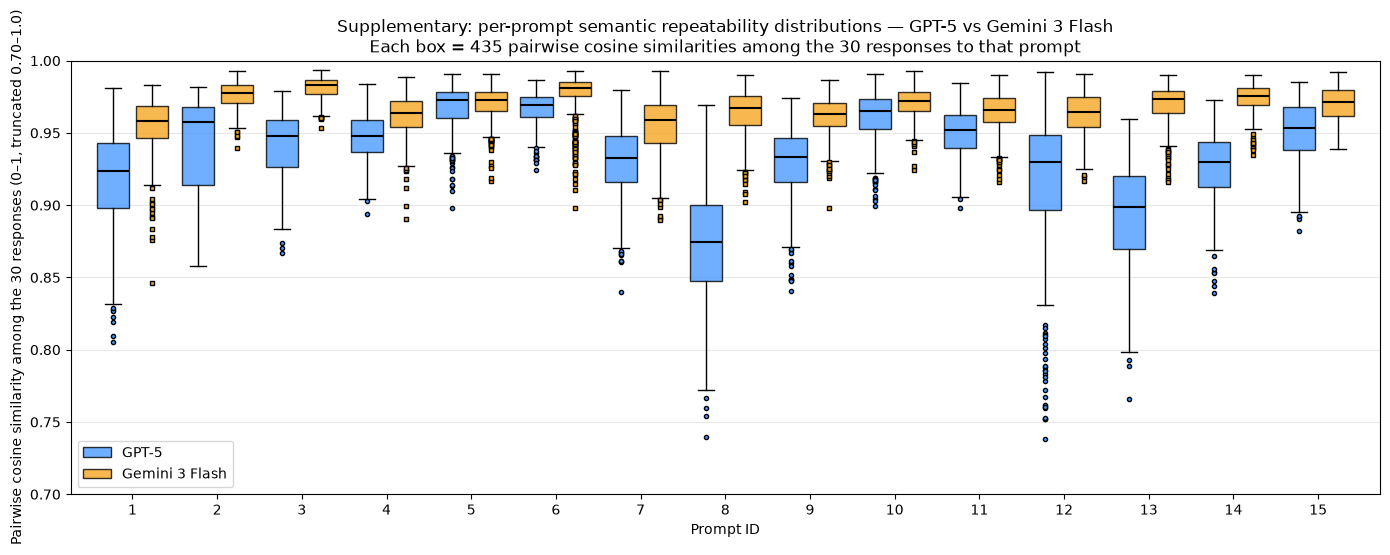

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/FigS_repeatability_per_prompt_boxplot.png
Sanity check (should all be 435): {1: 435, 2: 435, 3: 435}


In [9]:
# Supplementary boxplot — per-prompt repeatability distributions (truncated y-axis)
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

CACHE_DIR = PROJECT_DIR / 'Embeddings_Cache'

def pairwise_cosines_per_prompt_repeat(cache_file):
    """Return {prompt_id: array of 435 pairwise cosine similarities (rescaled 0-1)}."""
    c = np.load(cache_file, allow_pickle=True)
    embs, pids = c['embeddings'], c['prompt_ids']
    embs_n = embs / np.linalg.norm(embs, axis=1, keepdims=True)
    out = {}
    for pid in sorted(set(pids.tolist())):
        mask = pids == pid
        e = embs_n[mask]
        sim = e @ e.T
        iu = np.triu_indices(sim.shape[0], k=1)
        out[int(pid)] = (sim[iu] + 1.0) / 2.0
    return out

gpt5_repeat_box   = pairwise_cosines_per_prompt_repeat(CACHE_DIR / 'mpnet_gpt5_repeat_with_sw.npz')
gemini_repeat_box = pairwise_cosines_per_prompt_repeat(CACHE_DIR / 'mpnet_gemini_repeat_with_sw.npz')

prompts = sorted(gpt5_repeat_box.keys())
n_p = len(prompts)

fig, ax = plt.subplots(figsize=(14, 5.5))
box_width = 0.38
pos_g = np.arange(n_p) - box_width/2 - 0.04
pos_m = np.arange(n_p) + box_width/2 + 0.04

ax.boxplot([gpt5_repeat_box[p]   for p in prompts], positions=pos_g, widths=box_width,
           patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
           boxprops=dict(facecolor='#4C9AFF', edgecolor='black', alpha=0.80),
           whiskerprops=dict(color='black'), capprops=dict(color='black'),
           flierprops=dict(marker='o', markerfacecolor='#4C9AFF', markeredgecolor='black', markersize=3))
ax.boxplot([gemini_repeat_box[p] for p in prompts], positions=pos_m, widths=box_width,
           patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
           boxprops=dict(facecolor='#F5A623', edgecolor='black', alpha=0.80),
           whiskerprops=dict(color='black'), capprops=dict(color='black'),
           flierprops=dict(marker='s', markerfacecolor='#F5A623', markeredgecolor='black', markersize=3))

ax.set_xticks(range(n_p))
ax.set_xticklabels([str(p) for p in prompts])
ax.set_xlabel('Prompt ID')
ax.set_ylabel('Pairwise cosine similarity among the 30 responses (0–1, truncated 0.70–1.0)')
ax.set_ylim(0.70, 1.0)
ax.grid(axis='y', alpha=0.3)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#4C9AFF', edgecolor='black', alpha=0.80, label='GPT-5'),
                   Patch(facecolor='#F5A623', edgecolor='black', alpha=0.80, label='Gemini 3 Flash')],
          loc='lower left')
ax.set_title('Supplementary: per-prompt semantic repeatability distributions — GPT-5 vs Gemini 3 Flash\n'
             'Each box = 435 pairwise cosine similarities among the 30 responses to that prompt')

plt.tight_layout()
out_path = FIG_DIR / 'FigS_repeatability_per_prompt_boxplot.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)
print('Sanity check (should all be 435):', {p: len(gpt5_repeat_box[p]) for p in prompts[:3]})

### O.9 — Supplementary boxplot: Per-prompt reproducibility distributions, GPT-5 vs Gemini 3 Flash

Companion to main-text Figure 4 (bar chart from cell O.4), prepared for the **Supplementary Materials**.
The main-text bar chart stays as Figure 4; this boxplot adds the within-prompt distribution information, without replacing the simpler main-text visual.

Each box summarizes the **10 pairwise cosine similarities** among the 5 CoT-variant centroids
for one prompt (i.e., the raw inputs that are averaged to give the prompt’s reproducibility
score). With only 10 values per box, readers can see the full within-prompt spread — and
appreciate why single-prompt reproducibility estimates are inherently less precise than the
repeatability estimates in the companion supplementary figure (435 values per box).

Inputs: cached MPNet embeddings with stop-word removal (`mpnet_<model>_repro_with_sw.npz`),
rescaled from raw cosine to [0, 1] via (cos+1)/2 before plotting.

Output: `Figures_For_Paper/FigS_reproducibility_per_prompt_boxplot.png` at 300 dpi.

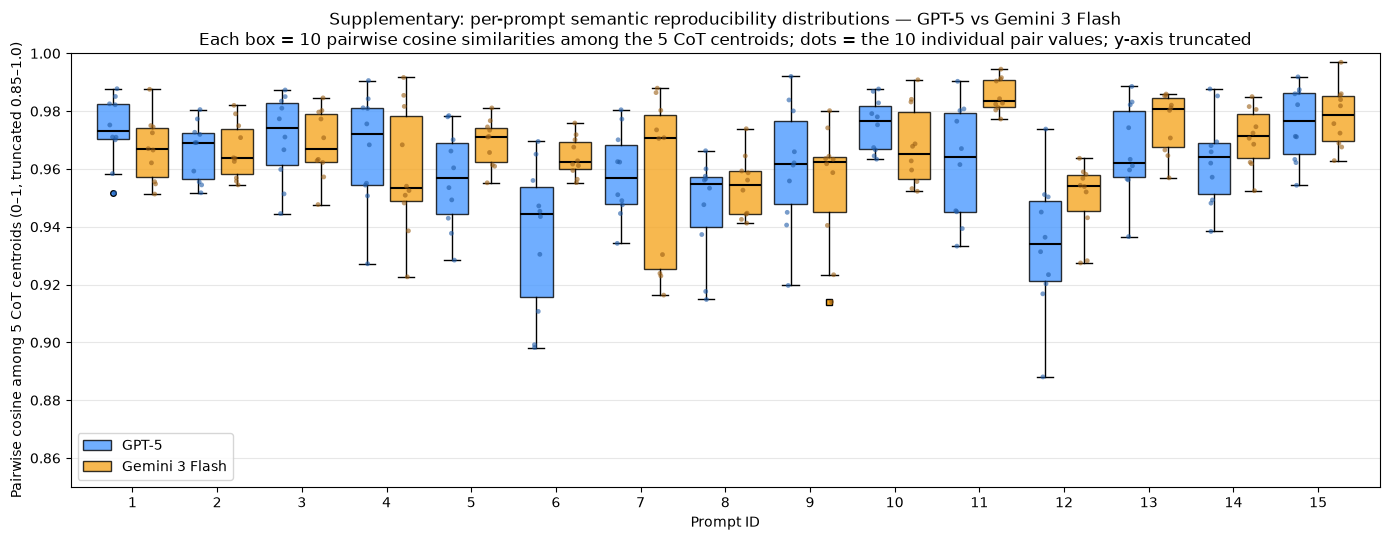

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/FigS_reproducibility_per_prompt_boxplot.png
Sanity check (should all be 10): {1: 10, 2: 10, 3: 10}


In [10]:
# Supplementary boxplot — per-prompt reproducibility distributions (truncated y-axis)
import matplotlib.pyplot as plt
import numpy as np
import re
from pathlib import Path

CACHE_DIR = PROJECT_DIR / 'Embeddings_Cache'

def _vint(v):
    s = str(v).strip()
    m = re.search(r'\d+', s)
    return int(m.group()) if m else None

def centroid_pair_cosines_per_prompt(cache_file):
    """Return {prompt_id: array of 10 pairwise cosine similarities among the 5 CoT centroids (rescaled 0-1)}."""
    c = np.load(cache_file, allow_pickle=True)
    embs, pids, vids = c['embeddings'], c['prompt_ids'], c['variant_ids']
    vnums = np.array([_vint(v) for v in vids.tolist()])
    out = {}
    for pid in sorted(set(pids.tolist())):
        mask = pids == pid
        e = embs[mask]
        v = vnums[mask]
        centroids = []
        for vu in sorted(set(v.tolist())):
            c_vec = e[v == vu].mean(axis=0)
            centroids.append(c_vec / np.linalg.norm(c_vec))
        centroids = np.vstack(centroids)
        sim = centroids @ centroids.T
        iu = np.triu_indices(sim.shape[0], k=1)
        out[int(pid)] = (sim[iu] + 1.0) / 2.0
    return out

gpt5_repro_box   = centroid_pair_cosines_per_prompt(CACHE_DIR / 'mpnet_gpt5_repro_with_sw.npz')
gemini_repro_box = centroid_pair_cosines_per_prompt(CACHE_DIR / 'mpnet_gemini_repro_with_sw.npz')

prompts = sorted(gpt5_repro_box.keys())
n_p = len(prompts)

fig, ax = plt.subplots(figsize=(14, 5.5))
box_width = 0.38
pos_g = np.arange(n_p) - box_width/2 - 0.04
pos_m = np.arange(n_p) + box_width/2 + 0.04

ax.boxplot([gpt5_repro_box[p]   for p in prompts], positions=pos_g, widths=box_width,
           patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
           boxprops=dict(facecolor='#4C9AFF', edgecolor='black', alpha=0.80),
           whiskerprops=dict(color='black'), capprops=dict(color='black'),
           flierprops=dict(marker='o', markerfacecolor='#4C9AFF', markeredgecolor='black', markersize=4))
ax.boxplot([gemini_repro_box[p] for p in prompts], positions=pos_m, widths=box_width,
           patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
           boxprops=dict(facecolor='#F5A623', edgecolor='black', alpha=0.80),
           whiskerprops=dict(color='black'), capprops=dict(color='black'),
           flierprops=dict(marker='s', markerfacecolor='#F5A623', markeredgecolor='black', markersize=4))

rng = np.random.default_rng(42)
for i, p in enumerate(prompts):
    jg = rng.uniform(-0.05, 0.05, size=len(gpt5_repro_box[p]))
    jm = rng.uniform(-0.05, 0.05, size=len(gemini_repro_box[p]))
    ax.scatter(pos_g[i] + jg, gpt5_repro_box[p],   color='#1F5BA8', s=12, alpha=0.6, zorder=3, edgecolors='none')
    ax.scatter(pos_m[i] + jm, gemini_repro_box[p], color='#9A5E13', s=12, alpha=0.6, zorder=3, edgecolors='none')

ax.set_xticks(range(n_p))
ax.set_xticklabels([str(p) for p in prompts])
ax.set_xlabel('Prompt ID')
ax.set_ylabel('Pairwise cosine among 5 CoT centroids (0–1, truncated 0.85–1.0)')
ax.set_ylim(0.85, 1.0)
ax.grid(axis='y', alpha=0.3)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#4C9AFF', edgecolor='black', alpha=0.80, label='GPT-5'),
                   Patch(facecolor='#F5A623', edgecolor='black', alpha=0.80, label='Gemini 3 Flash')],
          loc='lower left')
ax.set_title('Supplementary: per-prompt semantic reproducibility distributions — GPT-5 vs Gemini 3 Flash\n'
             'Each box = 10 pairwise cosine similarities among the 5 CoT centroids; dots = the 10 individual pair values; y-axis truncated')

plt.tight_layout()
out_path = FIG_DIR / 'FigS_reproducibility_per_prompt_boxplot.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)
print('Sanity check (should all be 10):', {p: len(gpt5_repro_box[p]) for p in prompts[:3]})

### O.10 — Supplementary boxplot: Per-prompt Repeat vs Repro, grouped by model

Companion to main-text Figure 1 (bar chart from cell O.2), prepared for the **Supplementary Materials**.
The main-text bar chart stays as Figure 1; this boxplot provides a combined cross-view that
shows, side by side within each model panel, the within-prompt spread of both metrics.

Two panels — GPT-5 (left) and Gemini 3 Flash (right). For each of the 15 prompts there are two
boxes: the **repeatability box** (lighter shade) summarizing the 435 pairwise cosine similarities
among the 30 responses to that prompt, and the **reproducibility box** (darker shade) summarizing
the 10 pairwise cosine similarities among the 5 CoT-variant centroids for that prompt.

**Important caveat (note in caption):** the two boxes per prompt summarize distributions of very
different sizes (n = 435 for repeatability vs. n = 10 for reproducibility). The 10-value boxes
will appear noisier and may show wider whiskers relative to their IQRs — a direct reflection of
the smaller underlying sample, not a property of reproducibility itself.

Output: `Figures_For_Paper/FigS_repeat_vs_repro_per_prompt_boxplot.png` at 300 dpi.

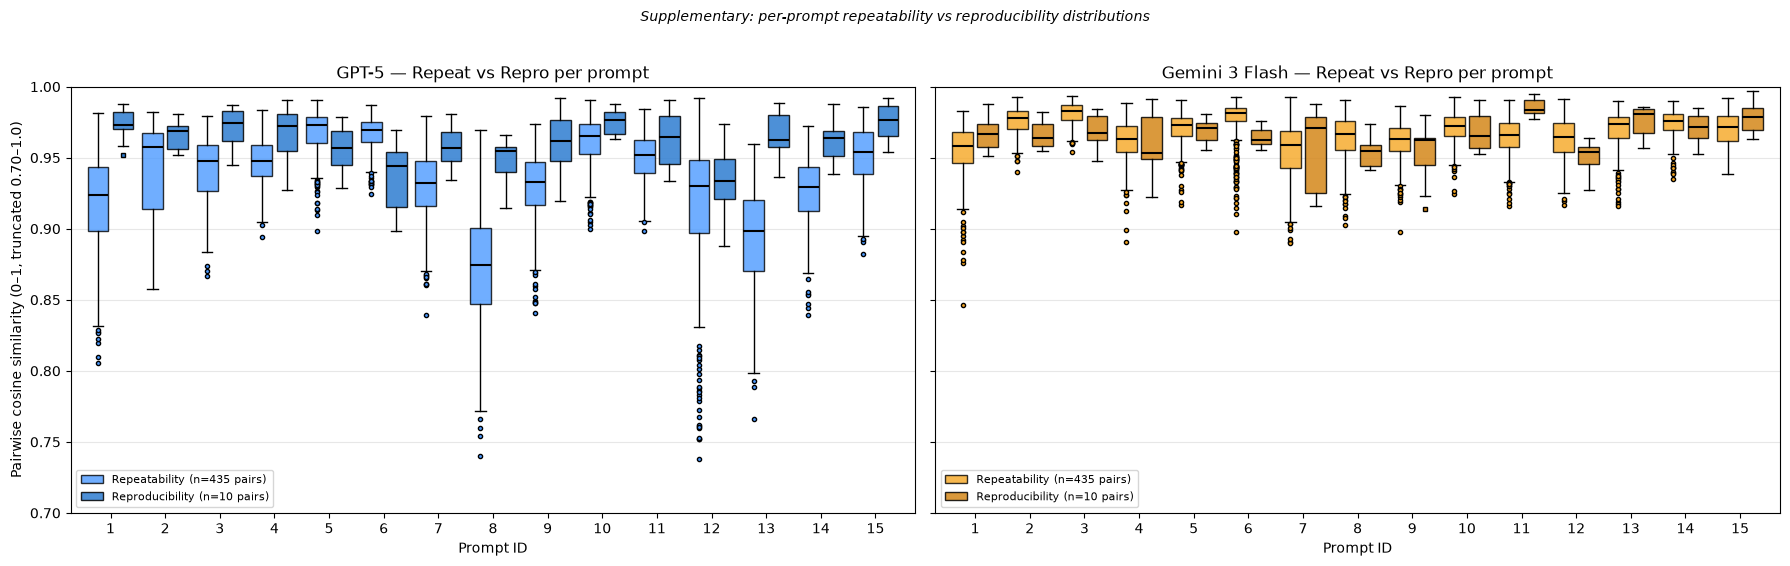

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/FigS_repeat_vs_repro_per_prompt_boxplot.png
Sanity check (first 3 prompts):
  Prompt 1: GPT-5 repeat n=435, repro n=10 | Gemini repeat n=435, repro n=10
  Prompt 2: GPT-5 repeat n=435, repro n=10 | Gemini repeat n=435, repro n=10
  Prompt 3: GPT-5 repeat n=435, repro n=10 | Gemini repeat n=435, repro n=10


In [2]:
# Supplementary boxplot — Repeat vs Repro per prompt, two panels (GPT-5 | Gemini)
import matplotlib.pyplot as plt
import numpy as np
import re
from pathlib import Path

CACHE_DIR = PROJECT_DIR / 'Embeddings_Cache'

def _vint(v):
    s = str(v).strip()
    m = re.search(r'\d+', s)
    return int(m.group()) if m else None

def pairwise_cosines_repeat(cache_file):
    """Return {prompt_id: array of 435 pairwise cosine similarities (rescaled 0-1)}."""
    c = np.load(cache_file, allow_pickle=True)
    embs, pids = c['embeddings'], c['prompt_ids']
    embs_n = embs / np.linalg.norm(embs, axis=1, keepdims=True)
    out = {}
    for pid in sorted(set(pids.tolist())):
        e = embs_n[pids == pid]
        sim = e @ e.T
        iu = np.triu_indices(sim.shape[0], k=1)
        out[int(pid)] = (sim[iu] + 1.0) / 2.0
    return out

def centroid_pair_cosines_repro(cache_file):
    """Return {prompt_id: array of 10 pairwise cosine similarities (rescaled 0-1)}."""
    c = np.load(cache_file, allow_pickle=True)
    embs, pids, vids = c['embeddings'], c['prompt_ids'], c['variant_ids']
    vnums = np.array([_vint(v) for v in vids.tolist()])
    out = {}
    for pid in sorted(set(pids.tolist())):
        mask = pids == pid
        e, v = embs[mask], vnums[mask]
        centroids = []
        for vu in sorted(set(v.tolist())):
            c_vec = e[v == vu].mean(axis=0)
            centroids.append(c_vec / np.linalg.norm(c_vec))
        centroids = np.vstack(centroids)
        sim = centroids @ centroids.T
        iu = np.triu_indices(sim.shape[0], k=1)
        out[int(pid)] = (sim[iu] + 1.0) / 2.0
    return out

gpt5_repeat   = pairwise_cosines_repeat(CACHE_DIR / 'mpnet_gpt5_repeat_with_sw.npz')
gpt5_repro    = centroid_pair_cosines_repro(CACHE_DIR / 'mpnet_gpt5_repro_with_sw.npz')
gemini_repeat = pairwise_cosines_repeat(CACHE_DIR / 'mpnet_gemini_repeat_with_sw.npz')
gemini_repro  = centroid_pair_cosines_repro(CACHE_DIR / 'mpnet_gemini_repro_with_sw.npz')

prompts = sorted(gpt5_repeat.keys())
n_p = len(prompts)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), sharey=True)
box_width = 0.38

def _draw(ax, data_repeat, data_repro, color_repeat, color_repro, title):
    pos_a = np.arange(n_p) - box_width/2 - 0.04
    pos_b = np.arange(n_p) + box_width/2 + 0.04
    ax.boxplot([data_repeat[p] for p in prompts], positions=pos_a, widths=box_width,
               patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
               boxprops=dict(facecolor=color_repeat, edgecolor='black', alpha=0.80),
               whiskerprops=dict(color='black'), capprops=dict(color='black'),
               flierprops=dict(marker='o', markerfacecolor=color_repeat, markeredgecolor='black', markersize=3))
    ax.boxplot([data_repro[p]  for p in prompts], positions=pos_b, widths=box_width,
               patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
               boxprops=dict(facecolor=color_repro, edgecolor='black', alpha=0.85),
               whiskerprops=dict(color='black'), capprops=dict(color='black'),
               flierprops=dict(marker='s', markerfacecolor=color_repro, markeredgecolor='black', markersize=3))
    ax.set_xticks(range(n_p))
    ax.set_xticklabels([str(p) for p in prompts])
    ax.set_xlabel('Prompt ID')
    ax.set_title(title)
    ax.set_ylim(0.70, 1.0)
    ax.grid(axis='y', alpha=0.3)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor=color_repeat, edgecolor='black', alpha=0.80, label='Repeatability (n=435 pairs)'),
                       Patch(facecolor=color_repro,  edgecolor='black', alpha=0.85, label='Reproducibility (n=10 pairs)')],
              loc='lower left', fontsize=8)

_draw(axes[0], gpt5_repeat, gpt5_repro, '#4C9AFF', '#2E7DD1', 'GPT-5 — Repeat vs Repro per prompt')
_draw(axes[1], gemini_repeat, gemini_repro, '#F5A623', '#D4871A', 'Gemini 3 Flash — Repeat vs Repro per prompt')
axes[0].set_ylabel('Pairwise cosine similarity (0–1, truncated 0.70–1.0)')

plt.suptitle('Supplementary: per-prompt repeatability vs reproducibility distributions',
             y=1.02, fontsize=10, style='italic')
plt.tight_layout()
out_path = FIG_DIR / 'FigS_repeat_vs_repro_per_prompt_boxplot.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)
print('Sanity check (first 3 prompts):')
for p in prompts[:3]:
    print(f'  Prompt {p}: GPT-5 repeat n={len(gpt5_repeat[p])}, repro n={len(gpt5_repro[p])} | '
          f'Gemini repeat n={len(gemini_repeat[p])}, repro n={len(gemini_repro[p])}')

### O.11 — Supplementary figure: Stop-word removal effect across embedding models (whiskers = min–max)

2×2 panel — GPT-5 (top row) and Gemini 3 Flash (bottom row), Repeatability (left) and Reproducibility (right).
Within each panel: four embedding-model pairs of bars, each pair showing *With stopword removal* (lighter) vs. *No stopword removal* (darker).

- **Error bars** show the **min–max range** across the 15 per-prompt scores (asymmetric).
- Y-axis truncated to **[0.80, 1.00]** for visibility of small between-condition differences.
- Output: `Figures_For_Paper/FigS_stopword_effect_minmax.png` at 300 dpi.

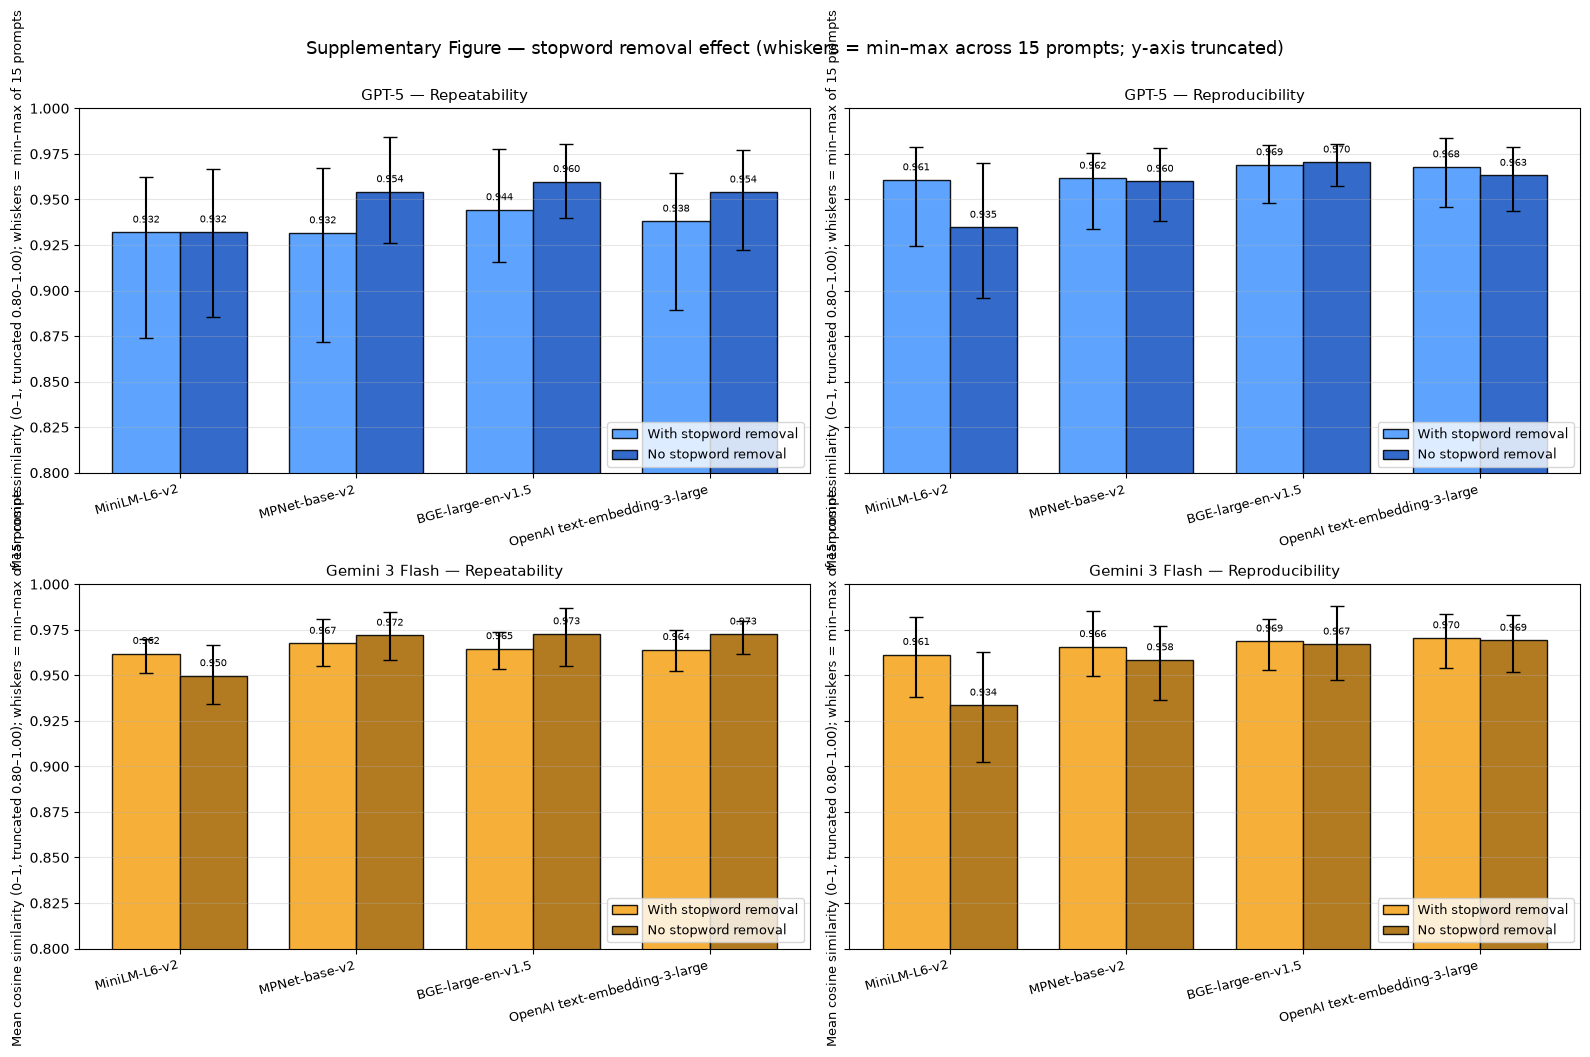

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/FigS_stopword_effect_minmax.png


In [3]:
# Supplementary figure (paper) — stopword removal effect, whiskers = MIN–MAX of 15 per-prompt scores
import matplotlib.pyplot as plt
import numpy as np

transformers_for_plot = [
    ('minilm',    'MiniLM-L6-v2'),
    ('mpnet',     'MPNet-base-v2'),
    ('bge-large', 'BGE-large-en-v1.5'),
    ('oai-large', 'OpenAI text-embedding-3-large'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
width = 0.38
x = np.arange(len(transformers_for_plot))
tnames = [t[1] for t in transformers_for_plot]

cells = [
    (axes[0, 0], 'GPT-5 — Repeatability',           repeat_all,          '#4C9AFF', '#1E5BC6'),
    (axes[0, 1], 'GPT-5 — Reproducibility',         repro_all,           '#4C9AFF', '#1E5BC6'),
    (axes[1, 0], 'Gemini 3 Flash — Repeatability',  gemini_repeat_all,   '#F5A623', '#AA6D0A'),
    (axes[1, 1], 'Gemini 3 Flash — Reproducibility',gemini_repro_all,    '#F5A623', '#AA6D0A'),
]

def _mean_minmax_err(series):
    m = series.mean()
    lo, hi = series.min(), series.max()
    return m, m - lo, hi - m

for ax, title, df_, color_with, color_no in cells:
    with_vals = [_mean_minmax_err(df_[f'{tkey}_with_sw_removal_01']) for tkey, _ in transformers_for_plot]
    no_vals   = [_mean_minmax_err(df_[f'{tkey}_no_sw_removal_01'])   for tkey, _ in transformers_for_plot]
    with_means = [v[0] for v in with_vals]; no_means = [v[0] for v in no_vals]
    with_err = np.array([[v[1] for v in with_vals], [v[2] for v in with_vals]])
    no_err   = np.array([[v[1] for v in no_vals],   [v[2] for v in no_vals]])

    b1 = ax.bar(x - width/2, with_means, width, yerr=with_err,
                label='With stopword removal', color=color_with, edgecolor='black', capsize=5, alpha=0.9)
    b2 = ax.bar(x + width/2, no_means,   width, yerr=no_err,
                label='No stopword removal',   color=color_no,   edgecolor='black', capsize=5, alpha=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(tnames, rotation=15, ha='right', fontsize=9)
    ax.set_ylabel('Mean cosine similarity (0–1, truncated 0.80–1.00); whiskers = min–max of 15 prompts', fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0.80, 1.00)
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(axis='y', alpha=0.3)
    for bars, means in [(b1, with_means), (b2, no_means)]:
        for bar, v in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=7)

fig.suptitle('Supplementary Figure — stopword removal effect (whiskers = min–max across 15 prompts; y-axis truncated)',
             fontsize=13, y=1.00)
plt.tight_layout()
out_path = FIG_DIR / 'FigS_stopword_effect_minmax.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.12 — Supplementary figure: Stop-word removal effect across embedding models (whiskers = ±1 SD)

Same 2×2 layout as O.11, with the same data; only the whisker convention changes.

- **Error bars** show **±1 SD across the 15 per-prompt scores** (symmetric).
- Y-axis truncated to **[0.85, 1.00]** for visibility.
- Output: `Figures_For_Paper/FigS_stopword_effect_sd.png` at 300 dpi.

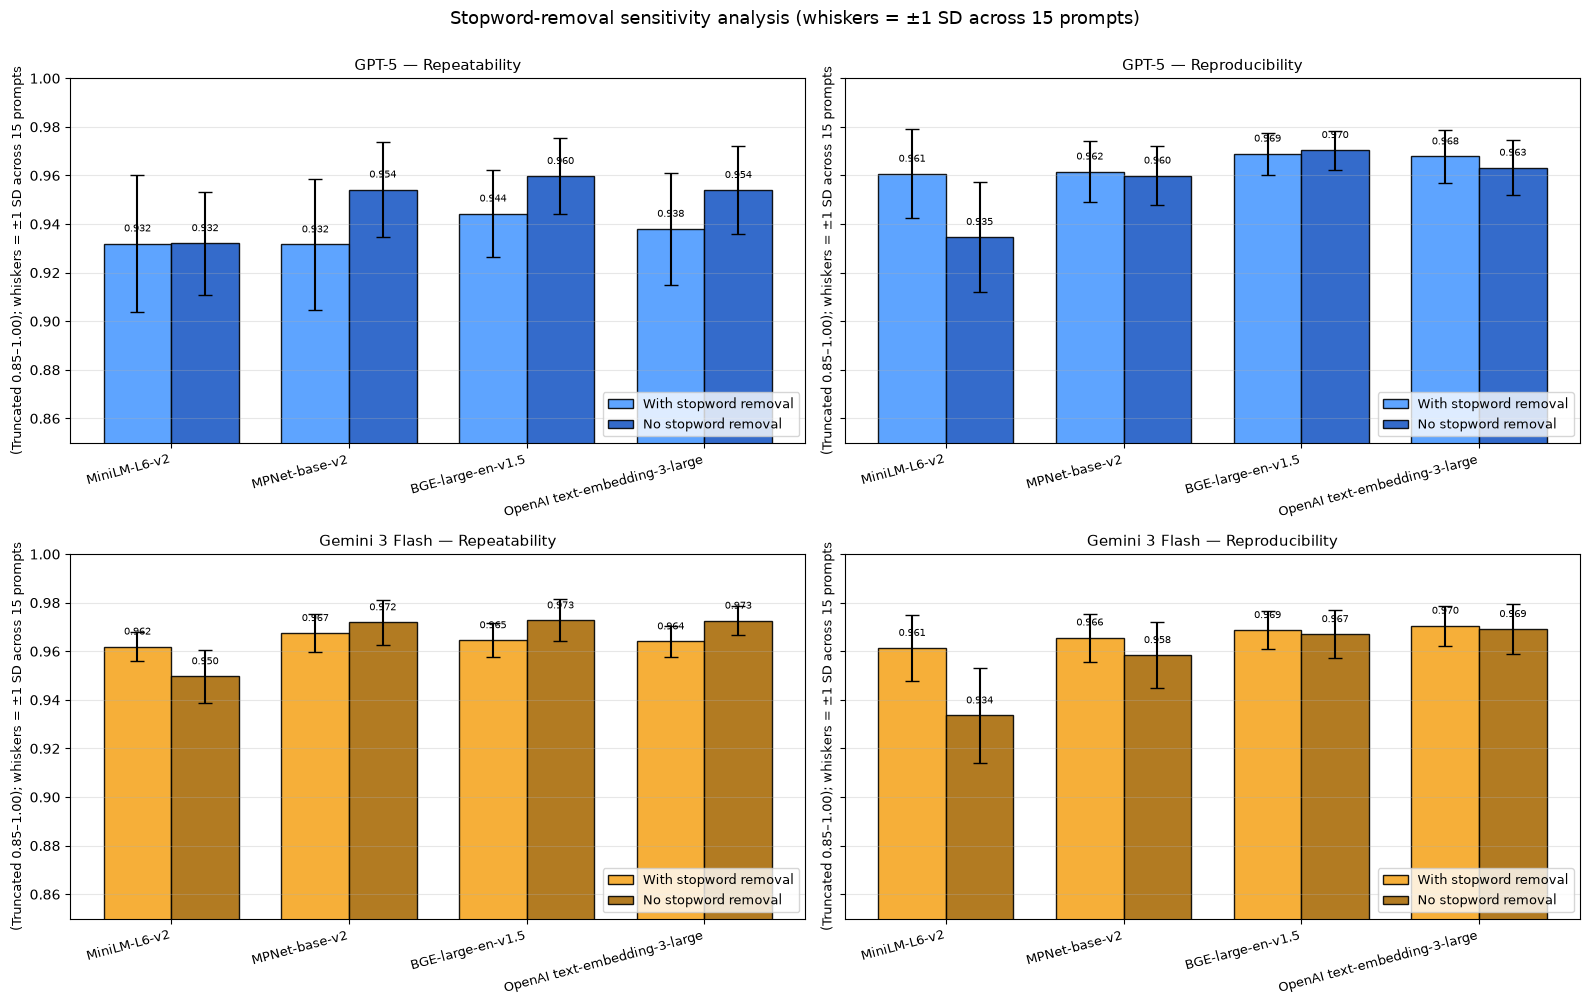

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/FigS_stopword_effect_sd.png


In [6]:
# Supplementary figure (paper) — stopword removal effect, whiskers = ±1 SD across 15 per-prompt scores
import matplotlib.pyplot as plt
import numpy as np

transformers_for_plot = [
    ('minilm',    'MiniLM-L6-v2'),
    ('mpnet',     'MPNet-base-v2'),
    ('bge-large', 'BGE-large-en-v1.5'),
    ('oai-large', 'OpenAI text-embedding-3-large'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
width = 0.38
x = np.arange(len(transformers_for_plot))
tnames = [t[1] for t in transformers_for_plot]

cells = [
    (axes[0, 0], 'GPT-5 — Repeatability',           repeat_all,          '#4C9AFF', '#1E5BC6'),
    (axes[0, 1], 'GPT-5 — Reproducibility',         repro_all,           '#4C9AFF', '#1E5BC6'),
    (axes[1, 0], 'Gemini 3 Flash — Repeatability',  gemini_repeat_all,   '#F5A623', '#AA6D0A'),
    (axes[1, 1], 'Gemini 3 Flash — Reproducibility',gemini_repro_all,    '#F5A623', '#AA6D0A'),
]

for ax, title, df_, color_with, color_no in cells:
    with_sw_means = [df_[f'{tkey}_with_sw_removal_01'].mean() for tkey, _ in transformers_for_plot]
    no_sw_means   = [df_[f'{tkey}_no_sw_removal_01'].mean()   for tkey, _ in transformers_for_plot]
    with_sw_sds   = [df_[f'{tkey}_with_sw_removal_01'].std()  for tkey, _ in transformers_for_plot]
    no_sw_sds     = [df_[f'{tkey}_no_sw_removal_01'].std()    for tkey, _ in transformers_for_plot]

    b1 = ax.bar(x - width/2, with_sw_means, width, yerr=with_sw_sds,
                label='With stopword removal', color=color_with, edgecolor='black', capsize=5, alpha=0.9)
    b2 = ax.bar(x + width/2, no_sw_means,   width, yerr=no_sw_sds,
                label='No stopword removal',   color=color_no,   edgecolor='black', capsize=5, alpha=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(tnames, rotation=15, ha='right', fontsize=9)
    ax.set_ylabel('(Truncated 0.85–1.00); whiskers = ±1 SD across 15 prompts', fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0.85, 1.00)
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(axis='y', alpha=0.3)
    for bars, means in [(b1, with_sw_means), (b2, no_sw_means)]:
        for bar, v in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=7)

fig.suptitle('Stopword-removal sensitivity analysis (whiskers = ±1 SD across 15 prompts)',
             fontsize=13, y=1.00)
plt.tight_layout()
out_path = FIG_DIR / 'FigS_stopword_effect_sd.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved →', out_path)

### O.13 — Per-variant reproducibility: mean + IQR table (Table 6 replacement)

To solve a comment that Table 6 should include a spread measure alongside the mean so cross-variant comparison isn’t biased by hidden skew.

**Output table (Option B layout):**

| CoT variant | GPT-5 mean | GPT-5 IQR | Gemini mean | Gemini IQR |

- **Mean** = mean of the 15 per-prompt reproducibility scores for that variant
- **IQR** = interquartile range (Q3 − Q1) of the 15 per-prompt scores, shown as `[Q1, Q3]` for transparency

Inputs: `gpt5_per_variant` and `gemini_per_variant` (loaded by O.0).
Output: CSV `Figures_For_Paper/Table6_per_variant_mean_iqr.csv` and a printed markdown table ready to paste into the paper.

In [2]:
# Per-variant reproducibility table — mean + IQR (Option B layout)
import re
import numpy as np
import pandas as pd

def _vint(v):
    s = str(v).strip()
    m = re.search(r'\d+', s)
    return int(m.group()) if m else None

gpt5_df   = gpt5_per_variant.copy()
gemini_df = gemini_per_variant.copy()
gpt5_df['variant_num']   = gpt5_df['variant_id'].apply(_vint)
gemini_df['variant_num'] = gemini_df['variant_id'].apply(_vint)

variant_labels = {
    1: 'v1 — Traditional CoT',
    2: 'v2 — Differential Diagnosis CoT',
    3: 'v3 — Intuitive Reasoning CoT',
    4: 'v4 — Analytic Reasoning CoT',
    5: 'v5 — Bayesian Reasoning CoT',
}

rows = []
for v in sorted(variant_labels.keys()):
    g = gpt5_df.loc[gpt5_df['variant_num']   == v, 'mean_sim_01'].values
    m = gemini_df.loc[gemini_df['variant_num'] == v, 'mean_sim_01'].values
    g_q1, g_q3 = np.percentile(g, [25, 75]); g_iqr = g_q3 - g_q1
    m_q1, m_q3 = np.percentile(m, [25, 75]); m_iqr = m_q3 - m_q1
    rows.append({
        'CoT variant': variant_labels[v],
        'GPT-5 mean':  round(float(g.mean()), 4),
        'GPT-5 IQR':   f'{g_iqr:.4f} [{g_q1:.4f}, {g_q3:.4f}]',
        'Gemini mean': round(float(m.mean()), 4),
        'Gemini IQR':  f'{m_iqr:.4f} [{m_q1:.4f}, {m_q3:.4f}]',
    })

tbl = pd.DataFrame(rows)

# Save CSV
csv_path = FIG_DIR / 'Table6_per_variant_mean_iqr.csv'
tbl.to_csv(csv_path, index=False)

# Markdown rendering for easy pasting into the paper
print('=== Table 6 replacement — mean + IQR (Option B) ===\n')
hdr = '| ' + ' | '.join(tbl.columns) + ' |'
sep = '|' + '|'.join(['---'] * len(tbl.columns)) + '|'
print(hdr)
print(sep)
for _, r in tbl.iterrows():
    print('| ' + ' | '.join(f'{v:.4f}' if isinstance(v, float) else str(v) for v in r.values) + ' |')
print()
print(f'Saved → {csv_path}')

tbl

=== Table 6 replacement — mean + IQR (Option B) ===

| CoT variant | GPT-5 mean | GPT-5 IQR | Gemini mean | Gemini IQR |
|---|---|---|---|---|
| v1 — Traditional CoT | 0.9546 | 0.0177 [0.9464, 0.9641] | 0.9686 | 0.0067 [0.9648, 0.9715] |
| v2 — Differential Diagnosis CoT | 0.9642 | 0.0160 [0.9597, 0.9757] | 0.9702 | 0.0108 [0.9665, 0.9773] |
| v3 — Intuitive Reasoning CoT | 0.9657 | 0.0145 [0.9599, 0.9743] | 0.9609 | 0.0160 [0.9539, 0.9699] |
| v4 — Analytic Reasoning CoT | 0.9573 | 0.0251 [0.9482, 0.9733] | 0.9644 | 0.0150 [0.9578, 0.9729] |
| v5 — Bayesian Reasoning CoT | 0.9620 | 0.0119 [0.9588, 0.9707] | 0.9649 | 0.0069 [0.9614, 0.9683] |

Saved → /Users/luizzadallapria/Documents/GPT5_Study/Figures_For_Paper/Table6_per_variant_mean_iqr.csv


,CoT variant,GPT-5 mean,GPT-5 IQR,Gemini mean,Gemini IQR
0,v1 — Traditional CoT,0.9546,"0.0177 [0.9464, 0.9641]",0.9686,"0.0067 [0.9648, 0.9715]"
1,v2 — Differential Diagnosis CoT,0.9642,"0.0160 [0.9597, 0.9757]",0.9702,"0.0108 [0.9665, 0.9773]"
2,v3 — Intuitive Reasoning CoT,0.9657,"0.0145 [0.9599, 0.9743]",0.9609,"0.0160 [0.9539, 0.9699]"
3,v4 — Analytic Reasoning CoT,0.9573,"0.0251 [0.9482, 0.9733]",0.9644,"0.0150 [0.9578, 0.9729]"
4,v5 — Bayesian Reasoning CoT,0.9620,"0.0119 [0.9588, 0.9707]",0.9649,"0.0069 [0.9614, 0.9683]"
